## A. Case Overview

### A.1. Latar Belakang
Produk asuransi merupakan salah satu alat mitigasi resiko finansial individu dari kejadian tidak terduga seperti penyakit atau kecelakaan, yang dapat berpotensi menimbulkan biaya besar dan berdampak ke perencanaan keuangan pribadi. <br><br>
Salah satu isu yang terjadi beberapa tahun terakhir ini, adalah terkait peningkatan klaim asuransi kesehatan individu, dimana terjadi kenaikan sebesar 25.5% antara periode Januari - Juni 2025 jika dibandingkan dengan periode yang sama di tahun 2024. Adapun peningkatan klaim tersebut akan berdampak ke penyesuaian premi yang
berpotensi mengakibatkan harga premi produk asuransi kesehatan individu menjadi lebih tidak terjangkau. <br> <br>
Oleh karena itu, diperlukan analisa berbasis data untuk memprediksi faktor-faktor yang paling berpengaruh
terhadap nilai klaim, sehingga dapat dilakukan inisiatif baik dari segi seleksi resiko, pencegahan, ataupun
deteksi dini untuk meminimalisir dampak peningkatan klaim guna menjaga harga premi yang terjangkau.

### A.2. Tujuan
1. Eksplorasi dan pembersihan data klaim asuransi kesehatan
2. Mengidentifikasi faktor-faktor yang paling mempengaruhi severitas dari klaim asuransi kesehatan
3. Mengidentifikasi faktor-faktor yang paling mempengaruhi frekuensi dari klaim asuransi kesehatan
4. Membuat model machine learning yang dapat memprediksi a) trend frekuensi, b) trend severitas, dan c) trend
nominal klaim berdasarkan data klaim yang tersedia
5. Evaluasi performa setidaknya 2 (dua) model machine learning

### A.3. Tugas Peserta
1. Preprocessing & Exploratory Data Analysis
2. Pembuatan Model Machine Learning
3. Analisa Hasil & Evaluasi Performa Model Machine Learning

## B. Dataset Overview

### B.1. Import Data

In [1]:
import pandas as pd
from sklearn.preprocessing import RobustScaler
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.holtwinters import Holt
from scipy import stats

In [2]:
data_klaim = pd.read_csv('Data_Klaim.csv')
data_klaim.head()

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS
0,C-0001-M,POL-0176,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,2024-07-08,2024-05-27,2024-05-27,28093653.0,6.143948e+06,Singapore
1,C-0002-M,POL-3288,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-08-06,2024-07-15,2024-07-15,80987278.0,8.230952e+07,Malaysia
2,C-0003-M,POL-1786,R,OP,C18.9,"MALIGNANT NEOPLASM, COLON, UNSPECIFIED",PAID,2024-10-17,2024-05-16,2024-05-16,183047130.0,1.928599e+08,Singapore
3,C-0004-M,POL-1786,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-09-03,2024-07-18,2024-07-18,191424386.0,1.914244e+08,Singapore
4,C-0005-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-06-06,2024-06-06,138936357.0,1.389364e+08,Singapore


In [3]:
data_polis = pd.read_csv('Data_Polis.csv')
data_polis.head()

,Nomor Polis,Plan Code,Gender,Tanggal Lahir,Tanggal Efektif Polis,Domisili
0,POL-0001,M-003,M,19640811,20140603,JAKARTA
1,POL-0002,M-003,M,19710730,20140603,JAKARTA
2,POL-0003,M-001,M,19790821,20160808,JAKARTA
3,POL-0004,M-003,M,20140724,20160811,JAKARTA
4,POL-0005,M-001,F,19810114,20150828,JAKARTA


Dataset terdiri dari 2 data yang saling berkaitan, yaitu **Data Klaim** dan **Data Polis**
1. Data Klaim --> Data klaim adalah data yang berisi mengenai data klaim asuransi dari Januari 2024 - Juli 2025, berisi detail klaim asuransi, seperti diagnosis, lokasi RS, biaya RS, dan lain-lain.
2. Data Polis --> Data polis adalah data yang berisi informasi mengenai asuransi peserta, seperti identitas pemegang polis dan plan/manfaat polis

### B.2. View Dataset

#### B.2.1. Data Klaim

In [4]:
data_klaim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4627 entries, 0 to 4626
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Claim ID                       4627 non-null   object 
 1   Nomor Polis                    4627 non-null   object 
 2   Reimburse/Cashless             4627 non-null   object 
 3   Inpatient/Outpatient           4590 non-null   object 
 4   ICD Diagnosis                  4621 non-null   object 
 5   ICD Description                4621 non-null   object 
 6   Status Klaim                   4627 non-null   object 
 7   Tanggal Pembayaran Klaim       4590 non-null   object 
 8   Tanggal Pasien Masuk RS        4627 non-null   object 
 9   Tanggal Pasien Keluar RS       4627 non-null   object 
 10  Nominal Klaim Yang Disetujui   4627 non-null   float64
 11  Nominal Biaya RS Yang Terjadi  4627 non-null   float64
 12  Lokasi RS                      4620 non-null   o

In [5]:
data_klaim.isnull().sum()

Claim ID                          0
Nomor Polis                       0
Reimburse/Cashless                0
Inpatient/Outpatient             37
ICD Diagnosis                     6
ICD Description                   6
Status Klaim                      0
Tanggal Pembayaran Klaim         37
Tanggal Pasien Masuk RS           0
Tanggal Pasien Keluar RS          0
Nominal Klaim Yang Disetujui      0
Nominal Biaya RS Yang Terjadi     0
Lokasi RS                         7
dtype: int64

In [6]:
data_klaim.duplicated().sum()

0

In [7]:
data_klaim.nunique()

Claim ID                         4627
Nomor Polis                      1210
Reimburse/Cashless                  2
Inpatient/Outpatient                4
ICD Diagnosis                     753
ICD Description                   946
Status Klaim                        1
Tanggal Pembayaran Klaim          357
Tanggal Pasien Masuk RS           564
Tanggal Pasien Keluar RS          574
Nominal Klaim Yang Disetujui     3995
Nominal Biaya RS Yang Terjadi    4194
Lokasi RS                          10
dtype: int64

In [8]:
data_klaim['Reimburse/Cashless'].unique()
# R --> reimburse
# C --> cashless

array(['R', 'C'], dtype=object)

In [9]:
data_klaim['Inpatient/Outpatient'].unique()
# OP --> Outpatient (rawat jalan)
# IP --> Inpatient (rawat inap)
# ODC --> One Day Care (rawat satu hari)
# ODS --> One Day Surgery (operasi satu hari)

array(['OP', 'ODC', 'IP', nan, 'ODS'], dtype=object)

In [10]:
data_klaim['ICD Diagnosis'].unique()

array(['C50', 'C34', 'C18.9', 'C90.0', 'C82.9', 'L02.2', 'A09', 'A90',
       'S00.0', 'H26.9', 'K29.7', 'K57', 'I49.5', 'R50.9', 'J18', 'M17',
       'I62.0', 'I67.1', 'C56', 'H26', 'M54.5', 'G57.1', 'S82.2', 'I63.9',
       'H25.9', 'I95.9', 'L03.1', 'L03.9', 'L12.0', 'J96', 'H35.9', 'L03',
       'I67', 'J70.4', 'J84.9', 'K29', 'R10', 'J20', 'S52', 'S52.0',
       'N18.0', 'N23', 'N18.6', 'I87', 'G62.9', 'D07.5', 'C61', 'N70.1',
       'N70', 'S09', 'I25.1', 'K63.5', nan, 'R11', 'G40.2', 'R56.9',
       'N20.1', 'N20', 'D25.9', 'E86.0', 'R57', 'N39.0', 'R07.4', 'K63.8',
       'M75.1', 'A49', 'I84', 'K30', 'H40.2', 'C85.9', 'H35', 'H35.0',
       'K63.9', 'K21', 'I63.6', 'I63', 'M48.0', 'K80.0', 'H25.1', 'M67.4',
       'H25', 'T14', 'H26.4', 'J45', 'E88.0', 'D64.9', 'M43.0', 'L02',
       'I25', 'K52.9', 'S83.2', 'C34.3', 'D02.2', 'M65.3', 'M13.9',
       'M89.4', 'M54.1', 'M54.3', 'M87.0', 'M54.4', 'M87.1', 'A91',
       'M46.0', 'D48.6', 'K29.3', 'R56.1', 'F05', 'R06', 'K51.9', '

In [11]:
data_klaim['Status Klaim'].unique()

array(['PAID'], dtype=object)

In [12]:
data_klaim['Lokasi RS'].unique()

array(['Singapore', 'Malaysia', 'Indonesia', 'Overseas', 'Hong Kong',
       'Taiwan', 'Japan', nan, 'Others', 'Tiongkok', 'Australia'],
      dtype=object)

In [13]:
data_klaim['Lokasi RS'].value_counts()

Lokasi RS
Indonesia    3102
Singapore    1019
Malaysia      456
Overseas       28
Others          6
Taiwan          5
Hong Kong       1
Japan           1
Tiongkok        1
Australia       1
Name: count, dtype: int64

Penemuan dari view data:
1. Data klaim terdiri dari 4627 data
2. Terdapat beberapa missing values pada data, seperti di Inpatient/Outpatient, ICD Diagnosis, Tanggal Pembayaran Klaim, dan Lokasi RS
3. Walaupun terdapat missing values pada data, kolom yang terdapat missing value bukanlah kolom target, sehingga kita masih dapat melakukan imputasi 
4. Kolom ICD memiliki cardinality yang tinggi, sehingga kita perlu handle hal tersebut agar kolom ICD tetap memberikan informasi penting (penyakit) namun dengan cardinality yang lebih rendah
5. Tidak ada duplicated rows
6. Terdapat nilai NaN pada kolom Inpatient/Outpatient (harus dibersihkan)

#### B.2.2. Data Polis

In [14]:
data_polis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4096 entries, 0 to 4095
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Nomor Polis            4096 non-null   object
 1   Plan Code              4096 non-null   object
 2   Gender                 4096 non-null   object
 3   Tanggal Lahir          4096 non-null   int64 
 4   Tanggal Efektif Polis  4096 non-null   int64 
 5   Domisili               4096 non-null   object
dtypes: int64(2), object(4)
memory usage: 192.1+ KB


In [15]:
data_polis.isnull().sum()

Nomor Polis              0
Plan Code                0
Gender                   0
Tanggal Lahir            0
Tanggal Efektif Polis    0
Domisili                 0
dtype: int64

In [16]:
data_polis['Plan Code'].unique()

array(['M-003', 'M-001', 'M-002'], dtype=object)

In [17]:
data_polis['Gender'].unique()

array(['M', 'F'], dtype=object)

In [18]:
data_polis['Domisili'].unique()

array(['JAKARTA', 'TANGERANG', 'YOGYAKARTA', 'BANDUNG', 'PALU', 'SORONG',
       'MAKASSAR', 'LAMPUNG', 'BALIKPAPAN', 'SURABAYA', 'SAMARINDA',
       'MALANG', 'BLITAR', 'MEDAN', 'MANADO', 'JEMBER', 'PALEMBANG',
       'BALI', 'SEMARANG', 'SOLO', 'KUDUS'], dtype=object)

Penemuan view data:
1. Data terdiri dari 4096 data polis
2. Tidak terdapat null values (missing value) pada dataset
3. Plan code terdiri dari 3 jenis plan
4. Domisili masih tergolong memiliki cardinality yang aman

## C. Data Handling

### C.1. Handle Missing Value

Dengan melihat keseluruhan data termasuk jumlah data, kami memutuskan untuk melakukan imputasi missing value, dengan pertimbangan sebagai berikut.
1. Data yang dimiliki cukup sedikit, apabila kami drop data yang missing, kami mungkin akan kehilangan beberapa informasi penting dari data
2. Imputasi hanya boleh dilakukan pada kolom non-target, yaitu kolom fitur yang bukan merupakan label
3. Pada bagian ini kami akan melakukan imputasi pada kolom seperti, Inpatient/Outpatient, Lokasi RS, Dll.

#### C.1.1. Inpatient/Outpatient Column

In [19]:
data_klaim[data_klaim['Inpatient/Outpatient'].isna()]

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS
254,C-0355-M,POL-3763,R,NaN,N70,Salpingitis and oophoritis,PAID,2025-02-24,2025-01-22,2025-01-22,1.693000e+06,1.693000e+06,Indonesia
260,C-0362-M,POL-0317,R,NaN,NaN,NaN,PAID,NaN,2024-01-18,2024-01-25,3.603640e+07,3.626740e+07,Indonesia
261,C-0363-M,POL-0317,R,NaN,NaN,NaN,PAID,NaN,2024-01-18,2024-01-25,0.000000e+00,4.860000e+06,Indonesia
796,C-1037-M,POL-3476,R,NaN,M51.1,Lumbar and other intervertebral disc disorders...,PAID,2024-11-11,2024-07-19,2024-07-19,2.500000e+06,2.500000e+06,Indonesia
829,C-1071-M,POL-2849,R,NaN,N84.0,Polyp of corpus uteri,PAID,2025-02-18,2024-10-10,2024-10-10,5.869460e+06,1.207075e+07,Singapore
934,C-1191-M,POL-0270,R,NaN,NaN,NaN,PAID,2024-02-01,2024-01-16,2024-01-17,8.706156e+07,7.458850e+03,NaN
989,C-1270-M,POL-2381,R,NaN,S33.0,Traumatic rupture of lumbar invertebral disc,PAID,2024-03-13,2024-01-05,2024-01-05,1.210691e+07,1.210691e+07,Singapore
1036,C-1323-M,POL-2057,R,NaN,N40,Hyperplasia of prostate,PAID,2024-09-18,2024-08-08,2024-08-10,1.020620e+08,1.040266e+08,Indonesia
1057,C-1345-M,POL-1567,R,NaN,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2025-01-10,2024-12-03,2024-12-03,5.650000e+05,5.650000e+05,Indonesia
1067,C-1355-M,POL-1567,R,NaN,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2025-01-10,2024-12-28,2024-12-28,5.650000e+05,5.650000e+05,Indonesia


In [20]:
date_cols = [
    'Tanggal Pasien Masuk RS',
    'Tanggal Pasien Keluar RS'
]

for col in date_cols:
    data_klaim[col] = pd.to_datetime(data_klaim[col], errors='coerce')

data_klaim['LOS'] = (
    data_klaim['Tanggal Pasien Keluar RS'] -
    data_klaim['Tanggal Pasien Masuk RS']
).dt.days

mask_nan = data_klaim['Inpatient/Outpatient'].isna()

data_klaim.loc[mask_nan & (data_klaim['LOS'] == 0), 'Inpatient/Outpatient'] = 'OP'
data_klaim.loc[mask_nan & (data_klaim['LOS'] == 1), 'Inpatient/Outpatient'] = 'ODC'
data_klaim.loc[mask_nan & (data_klaim['LOS'] > 1), 'Inpatient/Outpatient'] = 'IP'

Metode Imputasi yang dilakukan: 
1. Kita tahu bahwa OP (outpatient) artinya rawat jalan, IP (inpatient) artinya rawat inap, dan ODC (One Day Care) artinya rawat 1 malam atau sehari
2. Dengan memanfaatkan tanggal masuk RS dan tanggal keluar RS, kita dapat mengetahui LOS (length of stay) yaitu berapa lama pasien berada/dirawat di RS
3. Kita melakukan imputasi pada kolom ini, karena lama perawatan dapat mempengaruhi biaya RS dan biaya klaim

#### C.1.2. ICD

In [21]:
data_klaim[data_klaim['ICD Diagnosis'].isna()]

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS
260,C-0362-M,POL-0317,R,IP,NaN,NaN,PAID,NaN,2024-01-18,2024-01-25,36036400.00,36267400.00,Indonesia,7
261,C-0363-M,POL-0317,R,IP,NaN,NaN,PAID,NaN,2024-01-18,2024-01-25,0.00,4860000.00,Indonesia,7
934,C-1191-M,POL-0270,R,ODC,NaN,NaN,PAID,2024-02-01,2024-01-16,2024-01-17,87061561.91,7458.85,NaN,1
1390,C-1803-M,POL-0245,R,ODC,NaN,NaN,PAID,2024-02-01,2024-01-16,2024-01-17,23960945.00,8134.00,NaN,1
1391,C-1804-M,POL-0328,R,ODC,NaN,NaN,PAID,2024-02-01,2024-01-15,2024-01-16,71451795.09,82262516.32,Singapore,1
1392,C-1806-M,POL-0534,R,ODC,NaN,NaN,PAID,2024-01-31,2024-01-15,2024-01-16,54749557.00,56321315.00,NaN,1


In [22]:
for polis, group in data_klaim.groupby('Nomor Polis'):
    valid = group[
        group['ICD Diagnosis'].notna() &
        group['ICD Description'].notna()
    ]

    if valid.empty:
        continue

    icd_mode = valid['ICD Diagnosis'].mode().iloc[0]
    
    desc_mode = (
        valid[valid['ICD Diagnosis'] == icd_mode]
        ['ICD Description']
        .mode()
        .iloc[0]
    )

    mask = (
        (data_klaim['Nomor Polis'] == polis) &
        (
            data_klaim['ICD Diagnosis'].isna() |
            data_klaim['ICD Description'].isna()
        )
    )

    data_klaim.loc[mask, 'ICD Diagnosis'] = icd_mode
    data_klaim.loc[mask, 'ICD Description'] = desc_mode

data_klaim['ICD Diagnosis'] = data_klaim['ICD Diagnosis'].fillna('UNKNOWN')
data_klaim['ICD Description'] = data_klaim['ICD Description'].fillna('UNKNOWN')

Metode imputasi yang dilakukan:
1. ICD diagnosis adalah kode penyakit ICD yang berkaitan dengan klaim seorang peserta 
2. Ide dari imputasi ini adalah deterministic rule-based imputation, yaitu imputasi berbasis modus per group
3. Tujuannya adalah mengimputasi ICD diagnosis yang hilang per polis dengan pasangan modus yang konsisten, artinya kita akan melihat kembali ICD ke data historis pemegang polis dan melakukan Imputasi
4. Jika terdapat nomor polis yang sering mengalami penyakit tertentu, maka besar kemungkinan klaim lain yang hilang value ICD nya juga berkaitan dengan penyakit tersebut

#### C.1.3. Tanggal Pembayaran Klaim

In [23]:
data_klaim[data_klaim['Tanggal Pembayaran Klaim'].isna()]

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS
4,C-0005-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-06-06,2024-06-06,1.389364e+08,1.389364e+08,Singapore,0
5,C-0006-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-07-18,2024-07-18,1.360160e+08,1.368552e+08,Singapore,0
6,C-0007-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-06-27,2024-06-27,1.341925e+08,1.347333e+08,Singapore,0
7,C-0008-M,POL-0566,R,OP,C90.0,Multiple myeloma,PAID,NaN,2024-06-19,2024-06-19,5.398718e+08,3.164563e+08,Singapore,0
8,C-0009-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-05-15,2024-05-15,1.340855e+08,1.340855e+08,Singapore,0
9,C-0010-M,POL-0964,R,ODC,C82.9,"Follicular non-Hodgkin's lymphoma, unspecified",PAID,NaN,2024-07-05,2024-07-05,3.229387e+07,0.000000e+00,Malaysia,0
260,C-0362-M,POL-0317,R,IP,H26,Other Cataract,PAID,NaN,2024-01-18,2024-01-25,3.603640e+07,3.626740e+07,Indonesia,7
261,C-0363-M,POL-0317,R,IP,H26,Other Cataract,PAID,NaN,2024-01-18,2024-01-25,0.000000e+00,4.860000e+06,Indonesia,7
688,C-0902-M,POL-2319,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-06-25,2024-06-25,2.622530e+08,2.622530e+08,Singapore,0
790,C-1031-M,POL-2324,C,IP,M17.0,"Primary gonarthrosis, bilateral",PAID,NaN,2025-04-14,2025-04-18,2.628140e+08,2.657134e+08,Malaysia,4


In [24]:
date_cols = [
    'Tanggal Pasien Masuk RS',
    'Tanggal Pasien Keluar RS',
    'Tanggal Pembayaran Klaim'
]

for col in date_cols:
    data_klaim[col] = pd.to_datetime(data_klaim[col], errors='coerce')

data_klaim['delay_payment_days'] = (
    data_klaim['Tanggal Pembayaran Klaim'] -
    data_klaim['Tanggal Pasien Keluar RS']
).dt.days

delay_ref = data_klaim[
    data_klaim['delay_payment_days'].notna() &
    (data_klaim['delay_payment_days'] >= 0)
]

median_delay = (
    delay_ref
    .groupby('Reimburse/Cashless')['delay_payment_days']
    .median()
    .to_dict()
)


mask_na = data_klaim['Tanggal Pembayaran Klaim'].isna()

data_klaim.loc[mask_na, 'Tanggal Pembayaran Klaim'] = (
    data_klaim.loc[mask_na]
    .apply(
        lambda x: x['Tanggal Pasien Keluar RS']
        + pd.Timedelta(days=median_delay.get(x['Reimburse/Cashless'], 0)),
        axis=1
    )
)

data_klaim.drop(columns='delay_payment_days', inplace=True)

Metode imputasi yang dilakukan:
1. Imputasi yang dilakukan adalah untuk mengisi nilai hilang dari tanggal pembayaran klaim
2. Idenya adalah untuk mengisi nilai NaN dengan median keterlambatan pembayaran sejak tanggal pasien keluar RS, dibedakan berdasarkan kategori reimburse atau cashless
3. Asumsinya, kategori reimburse/cashless mempengaruhi waktu proses pembayaran
4. Asumsinya, median historis cukup stabil untuk digunakan sebagai prediktor tanggal pembayaran yang hilang

#### C.1.4. Lokasi RS

In [25]:
data_klaim[data_klaim['Lokasi RS'].isna()]

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS
934,C-1191-M,POL-0270,R,ODC,H35.3,Degeneration of macula and posterior pole,PAID,2024-02-01,2024-01-16,2024-01-17,87061561.91,7458.85,NaN,1
1390,C-1803-M,POL-0245,R,ODC,I25.1,CORONARY ATRIAL DISEASES (CAD),PAID,2024-02-01,2024-01-16,2024-01-17,23960945.00,8134.00,NaN,1
1392,C-1806-M,POL-0534,R,ODC,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-01-31,2024-01-15,2024-01-16,54749557.00,56321315.00,NaN,1
1864,C-2415-M,POL-2842,C,IP,R50.9,"FEVER, UNSPECIFIED",PAID,2025-09-08,2025-07-05,2025-07-06,7075620.00,7441220.00,NaN,1
2024,C-2613-M,POL-3355,R,ODC,H26.4,After-cataract (post cataract),PAID,2025-08-01,2025-06-02,2025-06-02,7081500.00,7245000.00,NaN,0
3796,C-4744-M,POL-2613,R,IP,K29.7,"GASTRITIS, UNSPECIFIED",PAID,2024-07-15,2024-04-22,2024-04-23,32228595.00,36142890.00,NaN,1
3921,C-4887-M,POL-2329,R,OP,C18.7,"MALIGNANT NEOPLASM, SIGMOID COLON",PAID,2024-06-19,2024-05-11,2024-05-11,2135400.00,2135400.00,NaN,0


In [26]:
data_klaim['Lokasi RS'] = data_klaim['Lokasi RS'].fillna('Others')

Metode imputasi yang dilakukan:
1. Lokasi RS terdapat beberapa negara yang terdapat di dalamnya termasuk nilai others
2. Sejak nilai others sudah terdapat pada kolom Lokasi RS, kita dapat imputasi nilai Lokasi RS yang hilang dengan kategori lokasi Others

### C.2. Handle High Cardinality Data

#### C.2.1. ICD Diagnosis

In [27]:
data_klaim['ICD Diagnosis'].unique()

array(['C50', 'C34', 'C18.9', 'C90.0', 'C82.9', 'L02.2', 'A09', 'A90',
       'S00.0', 'H26.9', 'K29.7', 'K57', 'I49.5', 'R50.9', 'J18', 'M17',
       'I62.0', 'I67.1', 'C56', 'H26', 'M54.5', 'G57.1', 'S82.2', 'I63.9',
       'H25.9', 'I95.9', 'L03.1', 'L03.9', 'L12.0', 'J96', 'H35.9', 'L03',
       'I67', 'J70.4', 'J84.9', 'K29', 'R10', 'J20', 'S52', 'S52.0',
       'N18.0', 'N23', 'N18.6', 'I87', 'G62.9', 'D07.5', 'C61', 'N70.1',
       'N70', 'S09', 'I25.1', 'K63.5', 'R11', 'G40.2', 'R56.9', 'N20.1',
       'N20', 'D25.9', 'E86.0', 'R57', 'N39.0', 'R07.4', 'K63.8', 'M75.1',
       'A49', 'I84', 'K30', 'H40.2', 'C85.9', 'H35', 'H35.0', 'K63.9',
       'K21', 'I63.6', 'I63', 'M48.0', 'K80.0', 'H25.1', 'M67.4', 'H25',
       'T14', 'H26.4', 'J45', 'E88.0', 'D64.9', 'M43.0', 'L02', 'I25',
       'K52.9', 'S83.2', 'C34.3', 'D02.2', 'M65.3', 'M13.9', 'M89.4',
       'M54.1', 'M54.3', 'M87.0', 'M54.4', 'M87.1', 'A91', 'M46.0',
       'D48.6', 'K29.3', 'R56.1', 'F05', 'R06', 'K51.9', 'K52.0

In [28]:
data_klaim['ICD Diagnosis'] = (
    data_klaim['ICD Diagnosis']
    .astype(str)
    .str.strip()
    .str.upper()
)

In [29]:
data_klaim['ICD_prefix'] = (
    data_klaim['ICD Diagnosis']
    .astype(str)
    .str[0]
)

In [30]:
icd_prefix_df = (
    data_klaim[['ICD_prefix']]
    .dropna()
    .drop_duplicates()
    .sort_values('ICD_prefix')
    .reset_index(drop=True)
)

In [31]:
icd_prefix_meaning = {
    'A': 'Infectious and parasitic diseases',
    'B': 'Infectious and parasitic diseases',
    'C': 'Malignant neoplasms',
    'D': 'Benign neoplasms and blood disorders',
    'E': 'Endocrine, nutritional and metabolic diseases',
    'F': 'Mental and behavioural disorders',
    'G': 'Diseases of the nervous system',
    'H': 'Diseases of the eye, ear and mastoid process',
    'I': 'Diseases of the circulatory system',
    'J': 'Diseases of the respiratory system',
    'K': 'Diseases of the digestive system',
    'L': 'Diseases of the skin and subcutaneous tissue',
    'M': 'Diseases of the musculoskeletal system',
    'N': 'Diseases of the genitourinary system',
    'O': 'Pregnancy, childbirth and puerperium',
    'P': 'Perinatal conditions',
    'Q': 'Congenital malformations',
    'R': 'Symptoms and abnormal clinical findings',
    'S': 'Injury and trauma',
    'T': 'Injury, poisoning and trauma',
    'V': 'Transport accidents (external cause)',
    'W': 'Other external causes of accidental injury',
    'X': 'Intentional self-harm',
    'Y': 'Assault and other external causes',
    'Z': 'Factors influencing health status and health service contact',
    'U': 'Special purposes / provisional assignment'
}


In [32]:
icd_prefix_lookup = (
    icd_prefix_df
    .assign(
        meaning=lambda df: df['ICD_prefix']
        .map(icd_prefix_meaning)
    )
)

In [33]:
icd_prefix_lookup

,ICD_prefix,meaning
0,A,Infectious and parasitic diseases
1,B,Infectious and parasitic diseases
2,C,Malignant neoplasms
3,D,Benign neoplasms and blood disorders
4,E,"Endocrine, nutritional and metabolic diseases"
5,F,Mental and behavioural disorders
6,G,Diseases of the nervous system
7,H,"Diseases of the eye, ear and mastoid process"
8,I,Diseases of the circulatory system
9,J,Diseases of the respiratory system


In [34]:
# icd_prefix_lookup.to_csv(
#     'icd_prefix_dictionary.csv',
#     index=False
# )

Metode yang dilakukan untuk mengurangi cardinality:
1. ICD lengkap memiliki banyak variasi menyebabkan cardinality yang sangat tinggi
2. Kami mengelompokkan ICD Diagnosis itu ke chapter ICD-10, yaitu mengambil prefix depannya yang menandakan penyakit besar
3. Dengan mengambil hanya prefixnya saja, diharapkan kami tetap menjaga informasi penting mengenai penyakit sambil mengurangi dimensi yang ada

### C.3. Data Type Consistency

#### C.3.1. Data Klaim

In [35]:
data_klaim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4627 entries, 0 to 4626
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Claim ID                       4627 non-null   object        
 1   Nomor Polis                    4627 non-null   object        
 2   Reimburse/Cashless             4627 non-null   object        
 3   Inpatient/Outpatient           4627 non-null   object        
 4   ICD Diagnosis                  4627 non-null   object        
 5   ICD Description                4627 non-null   object        
 6   Status Klaim                   4627 non-null   object        
 7   Tanggal Pembayaran Klaim       4627 non-null   datetime64[ns]
 8   Tanggal Pasien Masuk RS        4627 non-null   datetime64[ns]
 9   Tanggal Pasien Keluar RS       4627 non-null   datetime64[ns]
 10  Nominal Klaim Yang Disetujui   4627 non-null   float64       
 11  Nominal Biaya RS 

#### C.3.2. Data Polis

In [36]:
data_polis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4096 entries, 0 to 4095
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Nomor Polis            4096 non-null   object
 1   Plan Code              4096 non-null   object
 2   Gender                 4096 non-null   object
 3   Tanggal Lahir          4096 non-null   int64 
 4   Tanggal Efektif Polis  4096 non-null   int64 
 5   Domisili               4096 non-null   object
dtypes: int64(2), object(4)
memory usage: 192.1+ KB


In [37]:
data_polis['Tanggal Lahir'] = pd.to_datetime(
    data_polis['Tanggal Lahir'].astype(str),
    format='%Y%m%d',
    errors='coerce'
)

data_polis['Tanggal Efektif Polis'] = pd.to_datetime(
    data_polis['Tanggal Efektif Polis'].astype(str),
    format='%Y%m%d',
    errors='coerce'
)

In [38]:
data_polis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4096 entries, 0 to 4095
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Nomor Polis            4096 non-null   object        
 1   Plan Code              4096 non-null   object        
 2   Gender                 4096 non-null   object        
 3   Tanggal Lahir          4096 non-null   datetime64[ns]
 4   Tanggal Efektif Polis  4096 non-null   datetime64[ns]
 5   Domisili               4096 non-null   object        
dtypes: datetime64[ns](2), object(4)
memory usage: 192.1+ KB


Konversi kolom tanggal menjadi tipe data datetime untuk memastikan data type consistency, yaitu seluruh tanggal pada dataset bertipe datetime

## D. EDA

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#F8FAFC",
        "axes.edgecolor": "#E5E7EB",

        "grid.color": "#E5E7EB",
        "grid.linestyle": "--",
        "grid.linewidth": 0.7,

        "axes.labelcolor": "#334155",
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "text.color": "#334155",

        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlecolor": "#1E293B",

        "font.size": 11,
    }
)

sns.set_palette(
    'tab20'
)


In [40]:
df = data_klaim.merge(
    data_polis,
    on='Nomor Polis',
    how='left'
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4627 entries, 0 to 4626
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Claim ID                       4627 non-null   object        
 1   Nomor Polis                    4627 non-null   object        
 2   Reimburse/Cashless             4627 non-null   object        
 3   Inpatient/Outpatient           4627 non-null   object        
 4   ICD Diagnosis                  4627 non-null   object        
 5   ICD Description                4627 non-null   object        
 6   Status Klaim                   4627 non-null   object        
 7   Tanggal Pembayaran Klaim       4627 non-null   datetime64[ns]
 8   Tanggal Pasien Masuk RS        4627 non-null   datetime64[ns]
 9   Tanggal Pasien Keluar RS       4627 non-null   datetime64[ns]
 10  Nominal Klaim Yang Disetujui   4627 non-null   float64       
 11  Nominal Biaya RS 

In [41]:
df.head()

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS,ICD_prefix,Plan Code,Gender,Tanggal Lahir,Tanggal Efektif Polis,Domisili
0,C-0001-M,POL-0176,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,2024-07-08,2024-05-27,2024-05-27,28093653.0,6.143948e+06,Singapore,0,C,M-001,F,1967-02-20,2015-01-09,JAKARTA
1,C-0002-M,POL-3288,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-08-06,2024-07-15,2024-07-15,80987278.0,8.230952e+07,Malaysia,0,C,M-002,M,1956-09-25,2012-06-19,YOGYAKARTA
2,C-0003-M,POL-1786,R,OP,C18.9,"MALIGNANT NEOPLASM, COLON, UNSPECIFIED",PAID,2024-10-17,2024-05-16,2024-05-16,183047130.0,1.928599e+08,Singapore,0,C,M-002,F,1959-10-21,2015-03-16,SURABAYA
3,C-0004-M,POL-1786,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-09-03,2024-07-18,2024-07-18,191424386.0,1.914244e+08,Singapore,0,C,M-002,F,1959-10-21,2015-03-16,SURABAYA
4,C-0005-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,2024-07-26,2024-06-06,2024-06-06,138936357.0,1.389364e+08,Singapore,0,C,M-002,F,1968-09-06,2014-06-24,JAKARTA


In [42]:
df = df.sort_values(by='Tanggal Pasien Masuk RS')

### D.1. Check Outliers

#### D.1.1. Clean Data Nominal

In [43]:
# buang data yang nominal klaim = 0, karena artinya tidak terjadi klaim (data tidak informative)
df = df[df['Nominal Klaim Yang Disetujui'] > 0]

In [44]:
# buang data yang biaya RS yang terjadi = 0, karena artinya tidak terjadi biaya (data tidak informative)
df = df[df['Nominal Biaya RS Yang Terjadi'] > 0]

#### D.1.2. Check Boxplot

In [45]:
df.describe()

,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,LOS,Tanggal Lahir,Tanggal Efektif Polis
count,4613,4613,4613,4.613000e+03,4.613000e+03,4613.000000,4613,4613
mean,2024-12-16 23:50:00.650336,2024-10-11 04:39:23.060914944,2024-10-12 11:02:24.374593280,5.518893e+07,6.012367e+07,1.265987,1965-06-07 02:08:55.356600896,2014-12-03 21:21:06.594407168
min,2024-01-17 00:00:00,2024-01-01 00:00:00,2024-01-02 00:00:00,1.734000e+04,7.458850e+03,0.000000,1933-10-10 00:00:00,2011-12-09 00:00:00
25%,2024-08-06 00:00:00,2024-05-17 00:00:00,2024-05-17 00:00:00,2.356641e+06,2.729680e+06,0.000000,1955-11-02 00:00:00,2013-05-22 00:00:00
50%,2024-12-09 00:00:00,2024-10-12 00:00:00,2024-10-14 00:00:00,1.457000e+07,1.593875e+07,0.000000,1964-11-08 00:00:00,2014-12-28 00:00:00
75%,2025-05-06 00:00:00,2025-03-04 00:00:00,2025-03-04 00:00:00,5.154203e+07,5.438850e+07,1.000000,1973-01-26 00:00:00,2016-03-28 00:00:00
max,2025-12-09 00:00:00,2025-07-31 00:00:00,2025-08-09 00:00:00,2.197500e+09,3.892810e+09,54.000000,2017-06-09 00:00:00,2018-01-28 00:00:00
std,NaN,NaN,NaN,1.321200e+08,1.599945e+08,2.933146,NaN,NaN


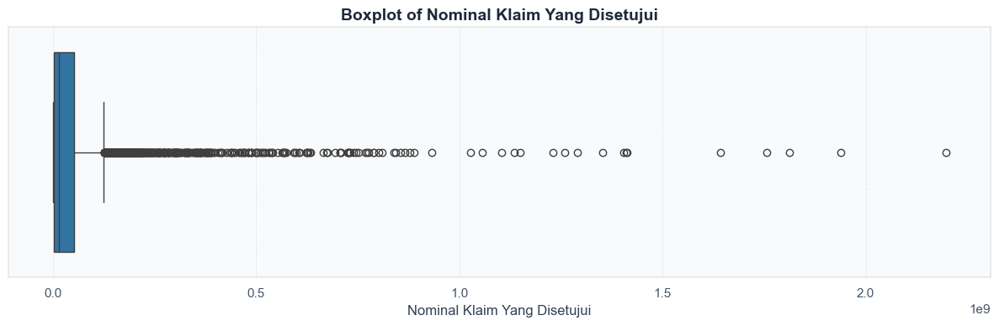

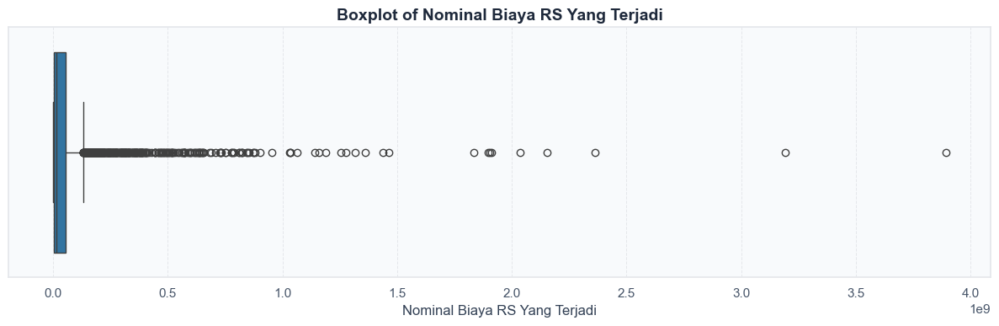

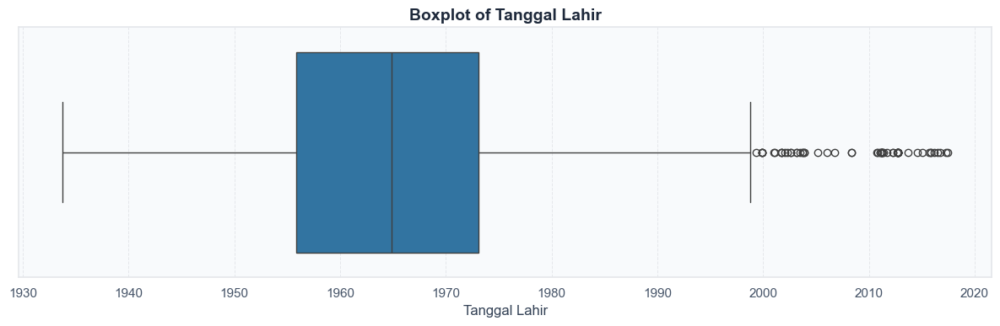

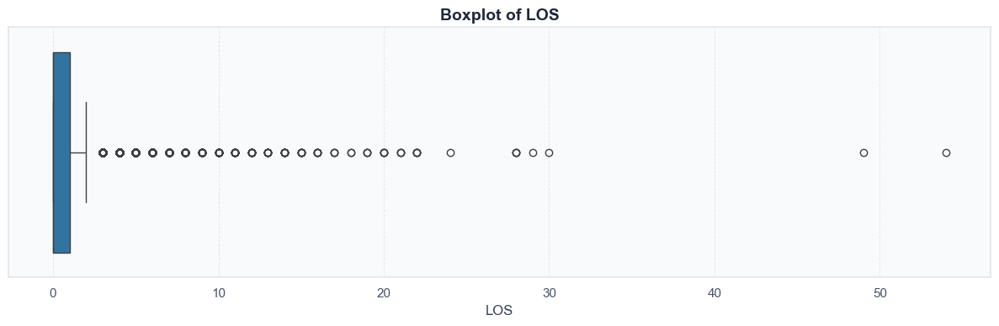

In [46]:
check_outliers_cols = [
    'Nominal Klaim Yang Disetujui',
    'Nominal Biaya RS Yang Terjadi',
    'Tanggal Lahir',
    'LOS'
]

for col in check_outliers_cols:
    plt.figure(figsize=(12, 4))

    sns.boxplot(
        x=df[col],
    )

    plt.title(f'Boxplot of {col}')
    plt.xlabel(f'{col}')
    plt.tight_layout()
    plt.show()


#### D.1.3. Check Extreme Values

In [47]:
# check nominal klaim yang disetujui > 1e9
df[df['Nominal Klaim Yang Disetujui'] > 1e9].head(5)

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS,ICD_prefix,Plan Code,Gender,Tanggal Lahir,Tanggal Efektif Polis,Domisili
2585,C-3368-M,POL-1988,R,IP,I73.9,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",PAID,2024-08-29,2024-01-21,2024-01-29,1.290821e+09,1.361402e+09,Singapore,8,I,M-001,M,1952-11-15,2014-04-28,SURABAYA
964,C-1231-M,POL-1240,R,IP,E87.2,ACIDOSIS,PAID,2024-07-08,2024-02-27,2024-03-05,1.756406e+09,1.905637e+09,Singapore,7,E,M-002,M,1970-02-16,2013-03-22,MAKASSAR
379,C-0518-M,POL-3809,R,IP,C34.3,"MALIGNANT NEOPLASM, LOWER LOBE, BRONCHUS OR LUNG",PAID,2025-01-10,2024-05-24,2024-05-29,1.404824e+09,1.438373e+09,Overseas,5,C,M-002,M,1955-08-04,2016-02-24,SURABAYA
2364,C-3078-M,POL-0935,R,IP,C54.1,Endometrium,PAID,2024-10-30,2024-07-24,2024-07-29,1.104661e+09,1.188142e+09,Singapore,5,C,M-002,F,1962-07-09,2012-01-25,SURABAYA
1873,C-2424-M,POL-3964,R,IP,C25,MALIGNANT NEOPLASM OF PANCREAS,PAID,2025-01-22,2024-08-12,2024-08-23,1.259901e+09,1.275567e+09,Singapore,11,C,M-002,F,1952-11-23,2012-11-22,JAKARTA


In [48]:
# check nominal biaya RS yang terjadi > 1e9
df[df['Nominal Biaya RS Yang Terjadi'] > 1e9].head(5)

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS,LOS,ICD_prefix,Plan Code,Gender,Tanggal Lahir,Tanggal Efektif Polis,Domisili
2585,C-3368-M,POL-1988,R,IP,I73.9,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",PAID,2024-08-29,2024-01-21,2024-01-29,1.290821e+09,1.361402e+09,Singapore,8,I,M-001,M,1952-11-15,2014-04-28,SURABAYA
2584,C-3367-M,POL-1988,R,IP,I73.9,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",PAID,2024-08-07,2024-01-21,2024-01-29,5.366324e+08,1.898035e+09,Singapore,8,I,M-001,M,1952-11-15,2014-04-28,SURABAYA
2586,C-3369-M,POL-1988,R,IP,I73.9,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",PAID,2024-08-07,2024-02-14,2024-02-19,6.930134e+08,1.141529e+09,Singapore,5,I,M-001,M,1952-11-15,2014-04-28,SURABAYA
964,C-1231-M,POL-1240,R,IP,E87.2,ACIDOSIS,PAID,2024-07-08,2024-02-27,2024-03-05,1.756406e+09,1.905637e+09,Singapore,7,E,M-002,M,1970-02-16,2013-03-22,MAKASSAR
379,C-0518-M,POL-3809,R,IP,C34.3,"MALIGNANT NEOPLASM, LOWER LOBE, BRONCHUS OR LUNG",PAID,2025-01-10,2024-05-24,2024-05-29,1.404824e+09,1.438373e+09,Overseas,5,C,M-002,M,1955-08-04,2016-02-24,SURABAYA


Extreme values yang terdapat di atas masih tergolong logis dan bukan merupakan data yang perlu dibuang. Alasannya:
1. Data di atas berlokasi di luar negeri, seperti Singapore dan Overseas. Harga rumah sakit dan perawatan di lokasi tersebut relatif lebih mahal
2. Data tersebut justru memberikan informasi penting mengenai pengaruh lokasi, LOS, dan fitur lain terhadap nominal klaim dan biaya RS
3. Data jangan di drop

#### D.1.4. Check by Approval Ratio

Approval ratio adalah rasio antara jumlah biaya rumah sakit yang benar-benar dibayar oleh perusahaan asuransi dibandingkan dengan total biaya yang diajukan rumah sakit atau peserta. Interpretasinya:
1. Nilai (0-1) --> Nominal klaim dibayar sebagian atau penuh (mendekati 1 artinya ditanggung perusahaan asuransi lebih banyak)
2. Nilai (>1) --> Tidak normal, biaya dibayar lebih mahal daripada biaya RS (namun masih dapat terjadi akibat manfaat polis atau faktor lainnya dari perusahaan asuransi)
3. Nilai 0 --> Tidak dibayar perusahaan sama sekali
4. Nilai 1 --> Dibayar penuh

In [49]:
df['approval_ratio'] = (
    df['Nominal Klaim Yang Disetujui'] /
    df['Nominal Biaya RS Yang Terjadi']
)

df['gap_biaya'] = (
    df['Nominal Biaya RS Yang Terjadi'] -
    df['Nominal Klaim Yang Disetujui']
)

df['status_pembayaran'] = np.where(
    df['gap_biaya'] == 0,
    'Fully Paid',
    'Not Fully Paid'
)

# filter
df_clean = df[df['approval_ratio'] < 2].copy()

print("Jumlah data sebelum:", len(df))
print("Jumlah data setelah filter:", len(df_clean))
print("Data dibuang:", len(df) - len(df_clean))

Jumlah data sebelum: 4613
Jumlah data setelah filter: 4607
Data dibuang: 6


In [50]:
outliers = df[df['approval_ratio'] > 2]

outliers[['Nominal Klaim Yang Disetujui',
          'Nominal Biaya RS Yang Terjadi',
          'approval_ratio']].sort_values(
    'approval_ratio', ascending=False
).head(10)

,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,approval_ratio
934,87061561.91,7458.85,11672.250000
1390,23960945.00,8134.00,2945.776371
1347,17145200.00,805824.40,21.276596
0,28093653.00,6143947.68,4.572574
624,2500000.00,787023.10,3.176527
1351,499000.00,168000.00,2.970238


In [51]:
df = df_clean.copy()

Pada approval ratio, sebelumnya kami memiliki beberapa approval ratio yang termasuk dalam extreme values atau tergolong sebagai outliers. Misalkan terdapat approval ratio 21.276596 yang artinya nominal klaim dibayar 21x lipat dibanding biaya RS terjadi. Artinya ini merupakan sebuah outlier, yang kami lakukan adalah:
1. Menghitung approval ratio untuk setiap baris data
2. Melakukan filtering yaitu membuang approval ratio >= 2
3. Kami memilih >= 2 karena, nominal klaim yang dibayarkan tidak mungkin 2x lipat dibandingkan nominal biaya RS terjadi. Kami menetapkan rasio 2 sebagai batas Approval Ratio.

#### D.1.5. Build Fitur Usia

In [52]:
df['Usia Pasien'] = (
    df['Tanggal Pasien Masuk RS'] - df['Tanggal Lahir']
).dt.days // 365

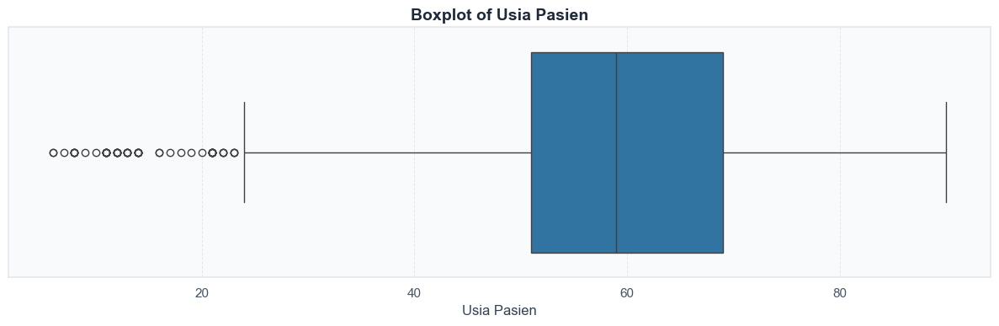

In [53]:
# check boxplot usia pasien
plt.figure(figsize=(12, 4))
sns.boxplot(
    x=df['Usia Pasien'],
)
plt.title('Boxplot of Usia Pasien')
plt.xlabel('Usia Pasien')
plt.tight_layout()
plt.show()

In [54]:
df[(df['Usia Pasien'] < 0) | (df['Usia Pasien'] > 100)]

,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,...,ICD_prefix,Plan Code,Gender,Tanggal Lahir,Tanggal Efektif Polis,Domisili,approval_ratio,gap_biaya,status_pembayaran,Usia Pasien


In [55]:
df.describe()

,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,LOS,Tanggal Lahir,Tanggal Efektif Polis,approval_ratio,gap_biaya,Usia Pasien
count,4607,4607,4607,4.607000e+03,4.607000e+03,4607.000000,4607,4607,4607.000000,4.607000e+03,4607.000000
mean,2024-12-17 06:05:04.753635840,2024-10-11 10:22:56.861298176,2024-10-12 16:47:24.367267072,5.522624e+07,6.020026e+07,1.266985,1965-06-05 22:59:40.464510528,2014-12-04 04:40:59.908834304,0.904254,4.974017e+06,58.889082
min,2024-01-17 00:00:00,2024-01-01 00:00:00,2024-01-02 00:00:00,1.734000e+04,2.152697e+04,0.000000,1933-10-10 00:00:00,2011-12-09 00:00:00,0.019433,-2.234155e+08,6.000000
25%,2024-08-06 00:00:00,2024-05-17 00:00:00,2024-05-17 00:00:00,2.345820e+06,2.735484e+06,0.000000,1955-11-02 00:00:00,2013-05-22 12:00:00,0.924832,0.000000e+00,51.000000
50%,2024-12-10 00:00:00,2024-10-13 00:00:00,2024-10-14 00:00:00,1.455790e+07,1.609109e+07,0.000000,1964-11-08 00:00:00,2014-12-28 00:00:00,0.988411,1.962000e+05,59.000000
75%,2025-05-06 00:00:00,2025-03-04 00:00:00,2025-03-04 12:00:00,5.154607e+07,5.445951e+07,2.000000,1973-02-04 00:00:00,2016-03-28 00:00:00,1.000000,1.522329e+06,69.000000
max,2025-12-09 00:00:00,2025-07-31 00:00:00,2025-08-09 00:00:00,2.197500e+09,3.892810e+09,54.000000,2017-06-09 00:00:00,2018-01-28 00:00:00,1.906941,3.103932e+09,90.000000
std,NaN,NaN,NaN,1.321979e+08,1.600846e+08,2.934870,NaN,NaN,0.194103,5.769760e+07,12.582669


Usia merupakan salah satu faktor utama menentukan sebuah premi, karena usia berhubungan secara langsung dengan resiko kesehatan, frekuensi klaim, dan besarnya biaya klaim. Maka dari itu, kami melakukan build fitur usia:
1. Dari data yang kami peroleh, kami tidak memiliki informasi usia secara langsung, namun kami dapat mengenerate fitur usia lewat tanggal lahir pemegang polis tersebut
2. Fitur usia diperoleh dari tanggal ketika pasien tersebut masuk RS dikurangi dengan tanggal lahir.
3. Kami mengambil tanggal masuk RS, karena biasanya RS akan melakukan pendaftaran pasien ketika masuk RS, dan menggunakan usia pasien saat datang

### D.2. Visualization

Selanjutnya adalah bagian visualisasi data. Visualization data merupakan salah satu bagian yang sangat penting untuk memahami distribusi data, memahami hubungan antar variabel, dan memahami struktur serta pola segmen. Pada tahap ini, biasanya analyst akan lebih mudah memahami data dalam bentuk visual dibandingkan tabular data, sehingga Visualization data akan sangat membantu

#### D.2.1. Check Distribution Data

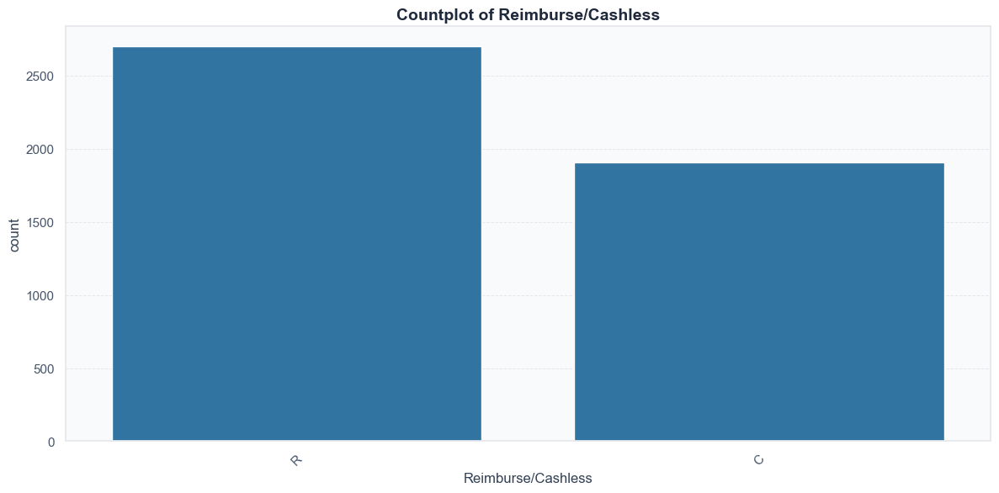

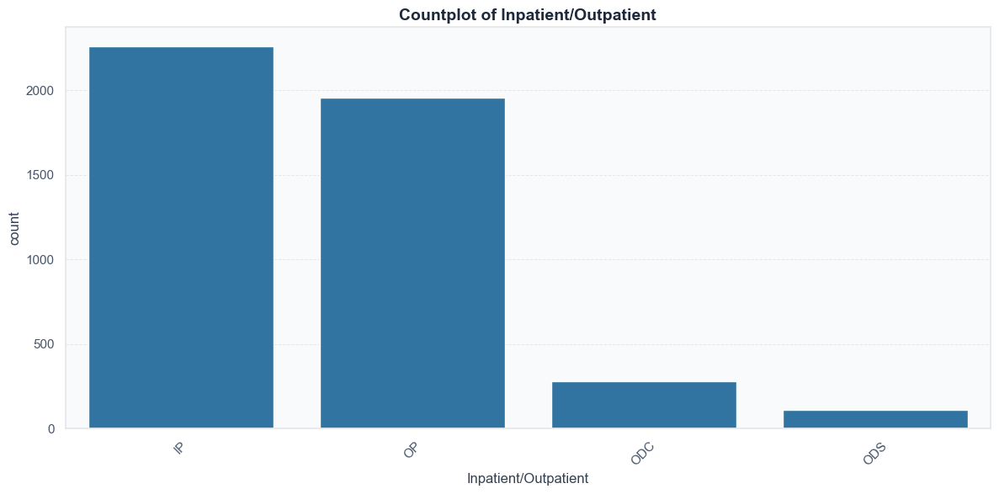

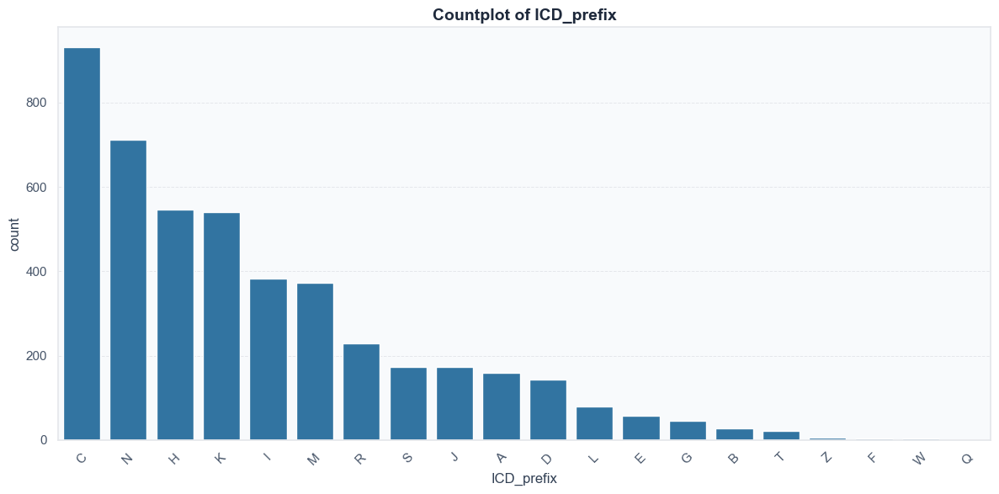

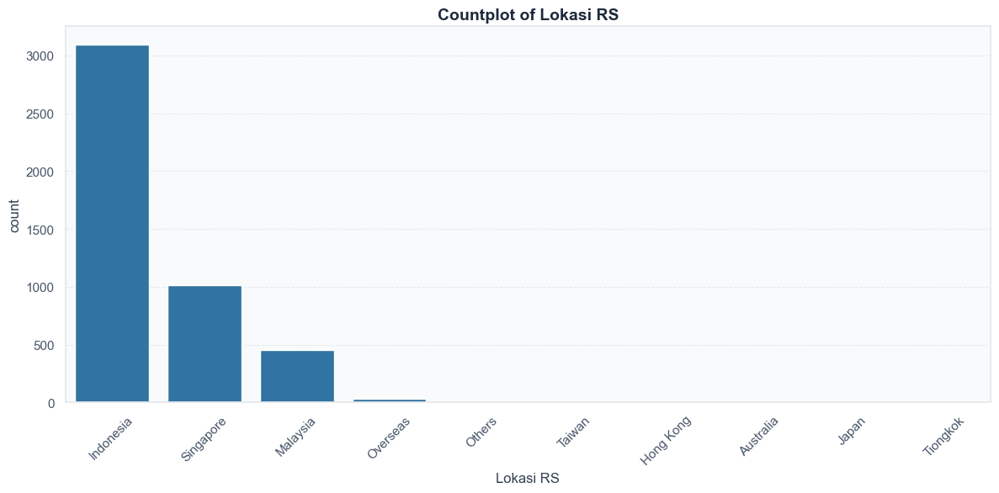

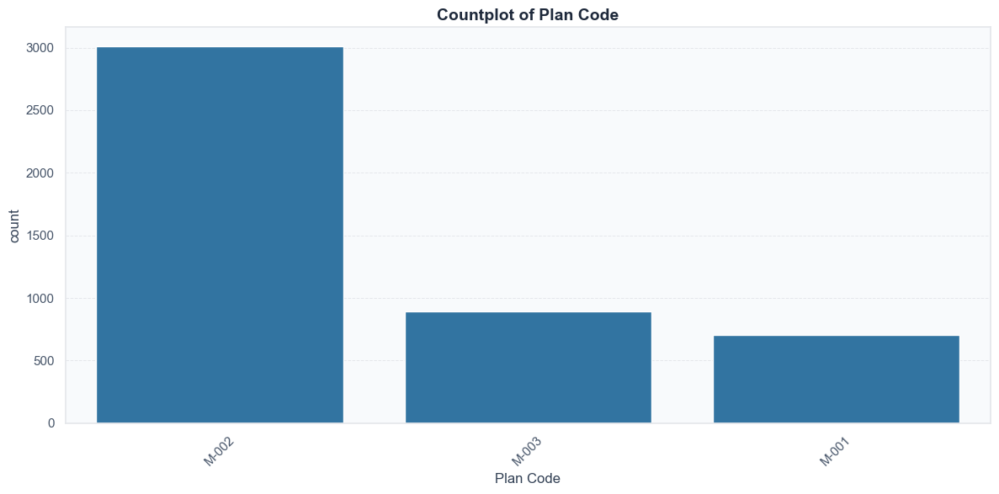

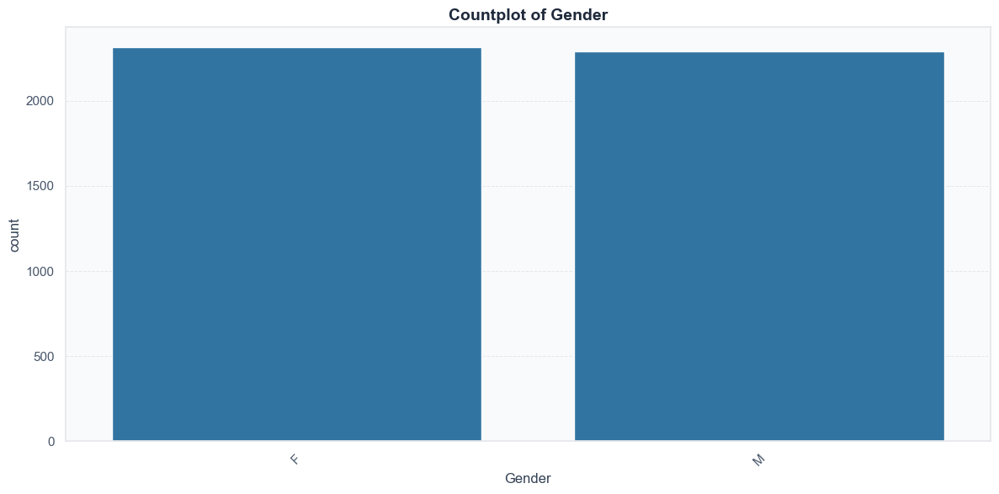

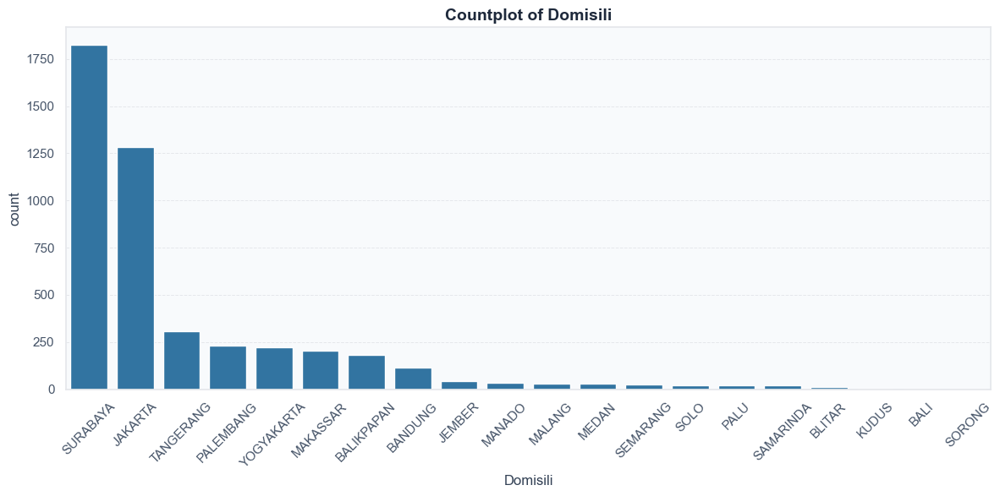

In [56]:
categorical_cols = [
    'Reimburse/Cashless',
    'Inpatient/Outpatient',
    'ICD_prefix',
    'Lokasi RS',
    'Plan Code',
    'Gender',
    'Domisili',
]

for col in categorical_cols:
    plt.figure(figsize=(12, 6))
    sns.countplot(
        x=df[col],
        order=df[col].value_counts().index,
    )
    plt.title(f'Countplot of {col}')
    plt.xlabel(f'{col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Pada bagian distribusi data fitur categorical, kami mendapat kesimpulan sebagai berikut:
1. Reimburse/Cashless --> Sebaran data tergolong seimbang, dengan kelas reimburse lebih tinggi dibandingkan cashless
2. Inpatient/Outpatient --> Sebaran data dominan kepada kelas IP (inpatient) dan OP (outpatient), terdapat beberapa data ODC dan ODS namun hanya sedikit 
3. ICD Prefix --> Sebaran data ICD paling banyak pada prefix (C,N,H,K) yaitu penyakit kanker, Ginjal dan saluran kemih, Mata telinga, dan pencernaan. Kemudian disusul dengan Jantung, pembuluh darah, Otot dan tulang, Cedera, dan infeksi. Prefix yang tergolong jarang adalah (V,W,X,Y,Z, Dll.) karena biasanya penyakit tersebut disebabkan oleh faktor eksternal
4. Lokasi RS --> Sebaran data lokasi RS hanya dominan kepada 3 Lokasi Rumah Sakit saja, yaitu Indonesia, Singapore, dan Malaysia
5. Plane Code --> Sebaran data dominan ke M-002, yang menurut asumsi kami itu merupakan plan yang standard dan berada pada urutan tengah sehingga menjadi plan polis paling diminati
6. Gender --> Sebaran data gender seimbang
7. Domisili --> Sebaran data dominan ke kota-kota besar, contohnya Surabaya, Jakarta, Tangeral dll.

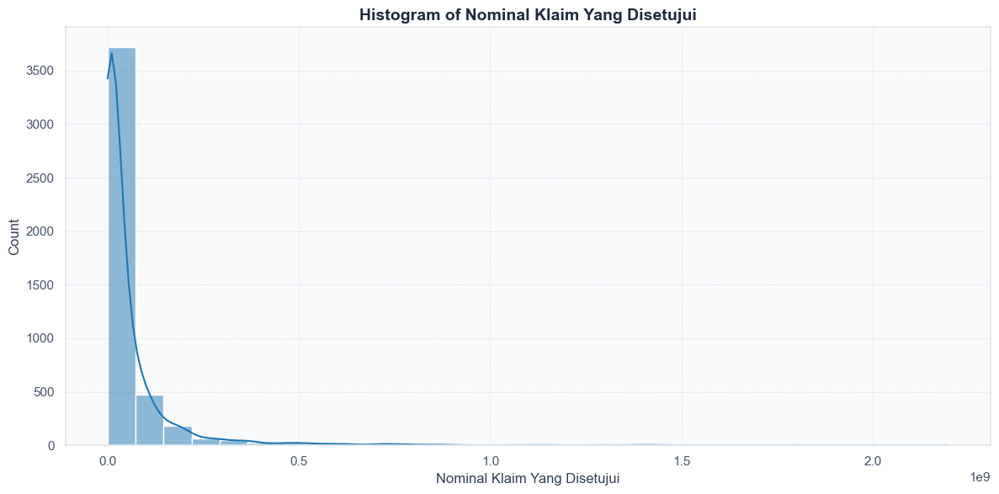

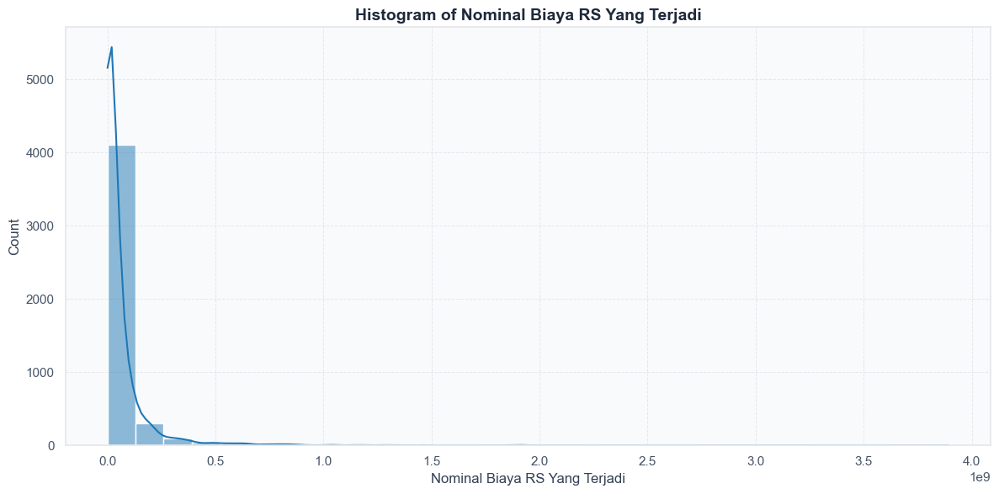

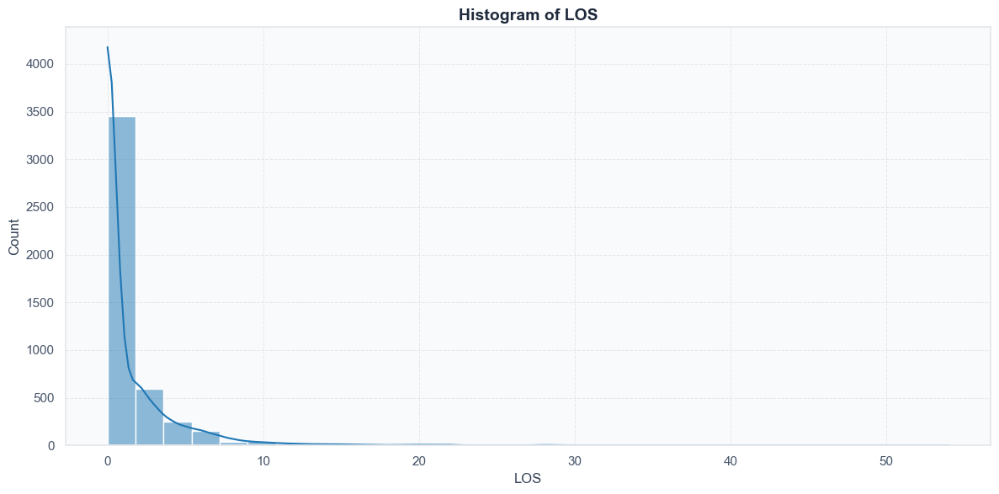

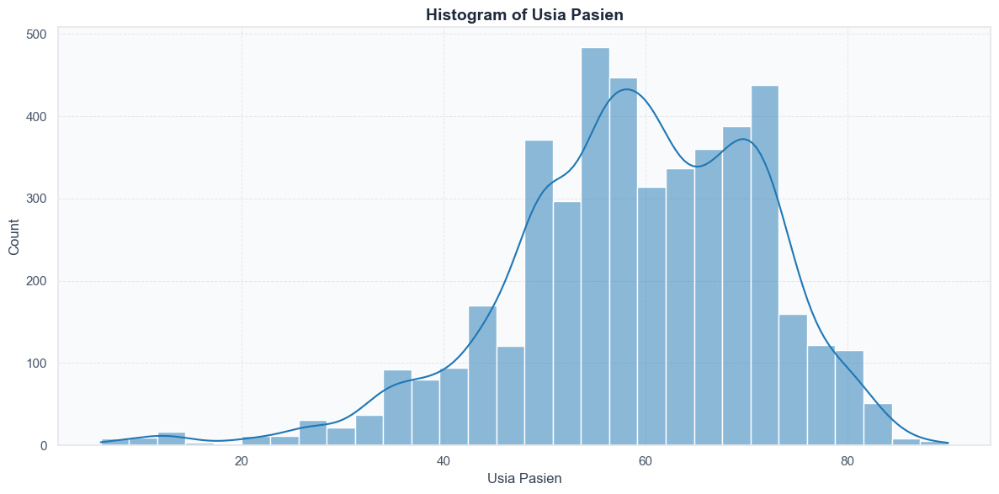

In [57]:
numerical_cols = [
    'Nominal Klaim Yang Disetujui',
    'Nominal Biaya RS Yang Terjadi',
    'LOS',
    'Usia Pasien'
]

for col in numerical_cols:
    plt.figure(figsize=(12, 6))
    sns.histplot(
        x=df[col],
        bins=30,
        kde=True,
    )
    plt.title(f'Histogram of {col}')
    plt.xlabel(f'{col}')
    plt.tight_layout()
    plt.show()

Pada bagian distribusi data numerikal, kami mendapat kesimpulan sebagai berikut:
1. Nominal Klaim --> Distribusi data terlihat sangat right skewed, yang menandakan sebaran data sangat dominan di 0.0 - 0.5 (1e9), namun terdapat extreme values yang berada di atas 1 (1e9). Menyebabkan right skewed yang sangat terlihat
2. Biaya RS --> Distribusi data pada biaya RS juga terlihat sangat right skewed, penyebabnya sama dengan distribusi nominal klaim
3. LOS (length of stay) --> Ternyata bukan hanya pada distribusi nominal saja, namun pada distribusi LOS juga terjadi right skewed yang sangat terlihat, disebabkan terdapat extreme values pada LOS yang artinya terdapat pasien yang menjalani perawatan dan penginapan yang lama di RS
4. Usia --> Distribusi Usia tergolong seimbang dan normal dengan usia yang terlihat dominan adalah sekitar 50-65 tahun

#### D.2.2. Visualization (/Day)

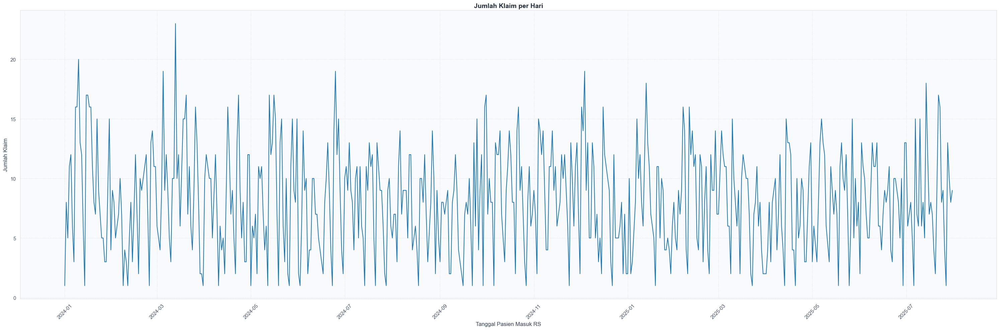

In [58]:
df_jumlah_klaim_per_day = (
    df.groupby(df['Tanggal Pasien Masuk RS'].dt.date)
    .size()
    .reset_index(name='Jumlah Klaim')
)

plt.figure(figsize=(30, 10))
sns.lineplot(
    x='Tanggal Pasien Masuk RS',
    y='Jumlah Klaim',
    data=df_jumlah_klaim_per_day,
)
plt.title('Jumlah Klaim per Hari')
plt.xlabel('Tanggal Pasien Masuk RS')
plt.ylabel('Jumlah Klaim')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

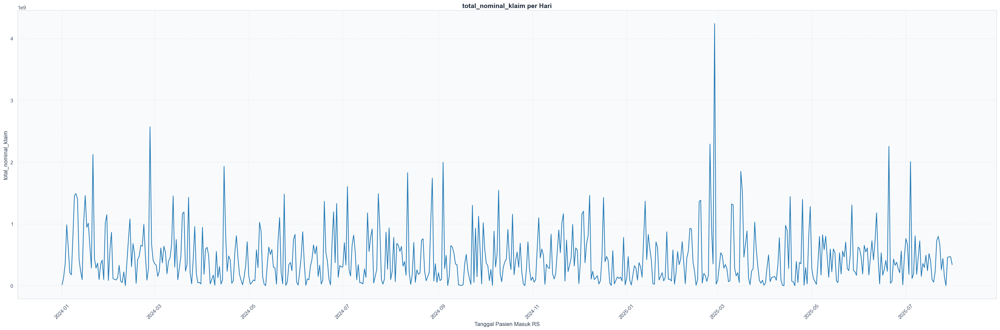

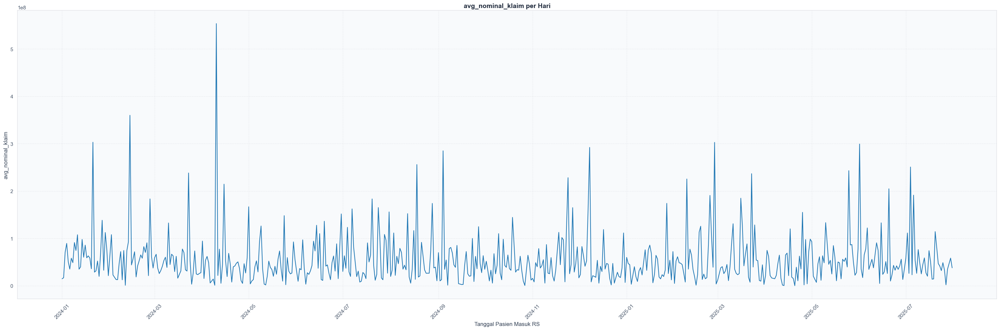

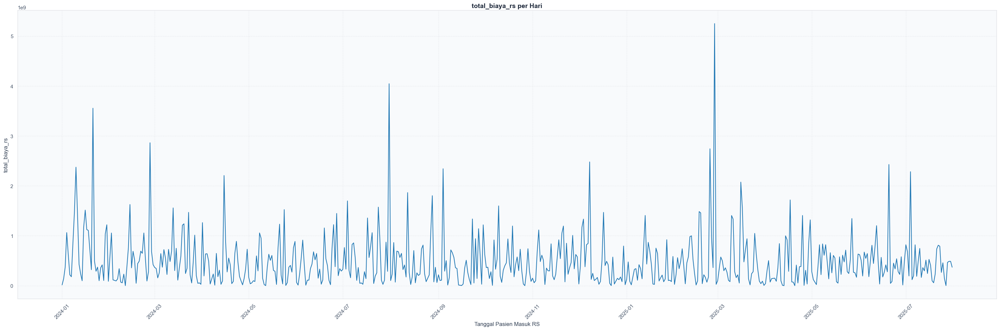

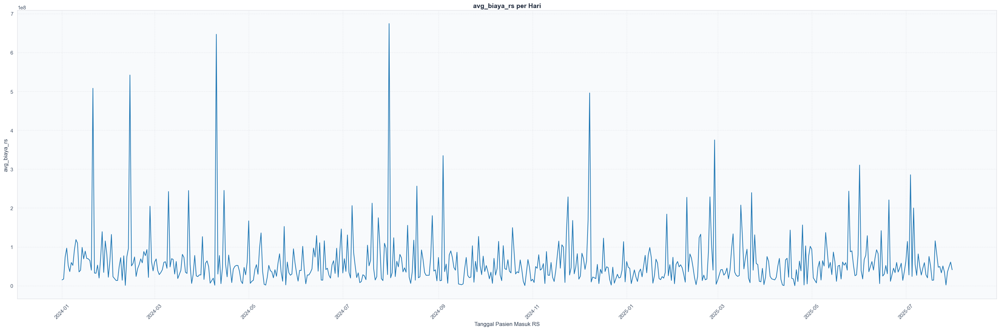

In [59]:
df_nominal_per_day = (
    df.groupby(df['Tanggal Pasien Masuk RS'].dt.date)
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
    )
    .reset_index()
)

nominal_per_day_col = [
    'total_nominal_klaim',
    'avg_nominal_klaim',
    'total_biaya_rs',
    'avg_biaya_rs'
]

for col in nominal_per_day_col:
    plt.figure(figsize=(30, 10))
    sns.lineplot(
        x='Tanggal Pasien Masuk RS',
        y=col,
        data=df_nominal_per_day,
    )
    plt.title(f'{col} per Hari')
    plt.xlabel('Tanggal Pasien Masuk RS')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

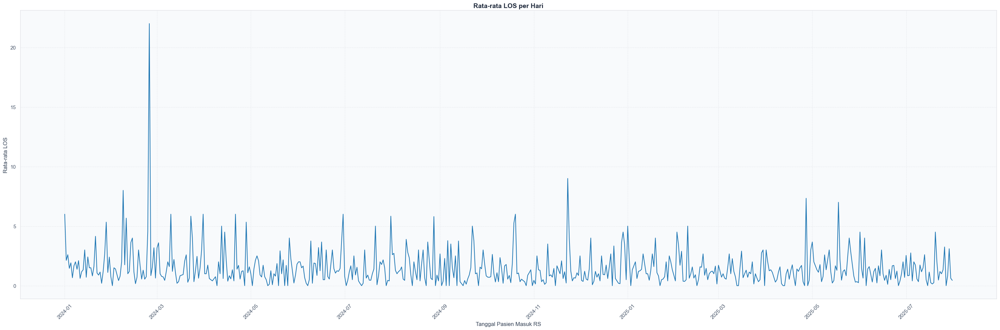

In [60]:
df_avg_los_per_day = (
    df.groupby(df['Tanggal Pasien Masuk RS'].dt.date)
    .agg(
        avg_los=('LOS', 'mean'),
    )
    .reset_index()
)
plt.figure(figsize=(30, 10))
sns.lineplot(
    x='Tanggal Pasien Masuk RS',
    y='avg_los',
    data=df_avg_los_per_day,
)
plt.title('Rata-rata LOS per Hari')
plt.xlabel('Tanggal Pasien Masuk RS')
plt.ylabel('Rata-rata LOS')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Setelah melakukan visualisasi dan analisis terhadap fitur-fitur yang kita lihat dalam hari, berikut kesimpulan yang kami dapat:
1. Pada grafik harian, pola dari data kurang dapat terlihat dikarenakan data sangat fluktuatif. Hal ini terjadi akibat volume per hari yang kecil, terdapat efek hari dalam minggu, serta kejadian-kejadian acak yang membuat garis menjadi sangat tidak beraturan. Hal ini kurang memungkinkan kami untuk menganalisis pola dan tren pada data
2. Untuk dapat melakukan analisis yang lebih mendalam dan mudah, perlu dilakukan agregasi, misalnya agregasi per bulan seperti yang diharapkan pada soal.

#### D.2.3. Visualization (/Month)

In [61]:
df['YearMonth'] = df['Tanggal Pasien Masuk RS'].dt.to_period('M')
df_month = (
    df.groupby('YearMonth')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)
df_month['YearMonth'] = df_month['YearMonth'].dt.to_timestamp()
df_month

,YearMonth,total_nominal_klaim,avg_nominal_klaim,total_biaya_rs,avg_biaya_rs,avg_los,jumlah_klaim
0,2024-01-01,2.014996e+10,6.784498e+07,2.347435e+10,7.903823e+07,1.606061,297
1,2024-02-01,1.385965e+10,6.663291e+07,1.526124e+10,7.337136e+07,1.557692,208
2,2024-03-01,1.431126e+10,5.147935e+07,1.545641e+10,5.559858e+07,1.503597,278
3,2024-04-01,1.144056e+10,4.827242e+07,1.274431e+10,5.377344e+07,1.198312,237
4,2024-05-01,1.216622e+10,4.661388e+07,1.276852e+10,4.892152e+07,1.199234,261
5,2024-06-01,1.212517e+10,5.511440e+07,1.252771e+10,5.694412e+07,1.400000,220
6,2024-07-01,1.493572e+10,5.950487e+07,1.907926e+10,7.601298e+07,0.968127,251
7,2024-08-01,1.351294e+10,5.926726e+07,1.401514e+10,6.146992e+07,1.535088,228
8,2024-09-01,1.226412e+10,5.896211e+07,1.319235e+10,6.342476e+07,1.427885,208
9,2024-10-01,1.268117e+10,4.628163e+07,1.334366e+10,4.869948e+07,1.098540,274


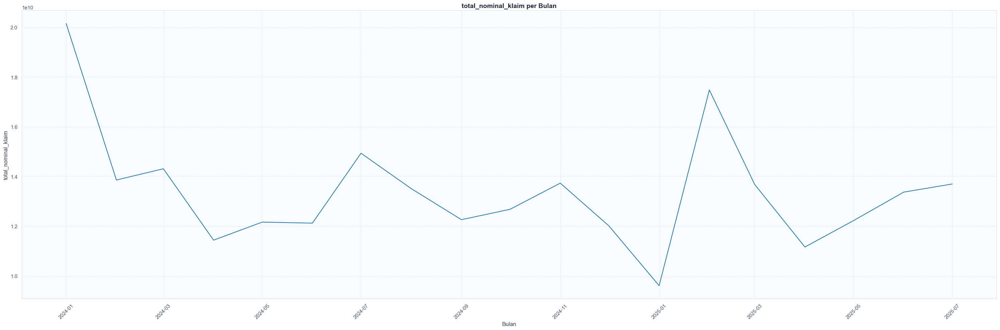

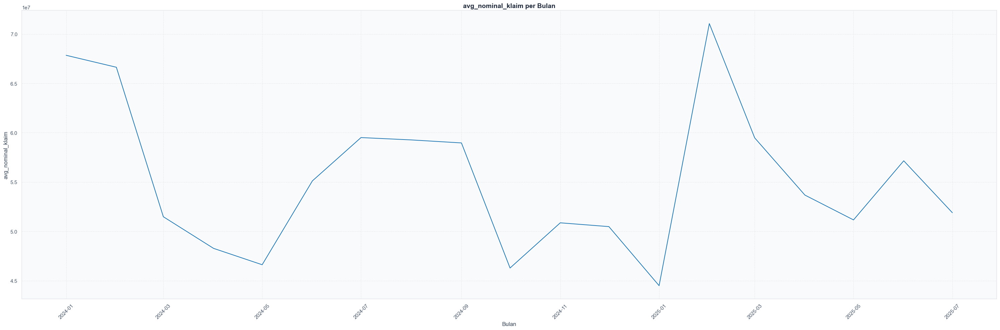

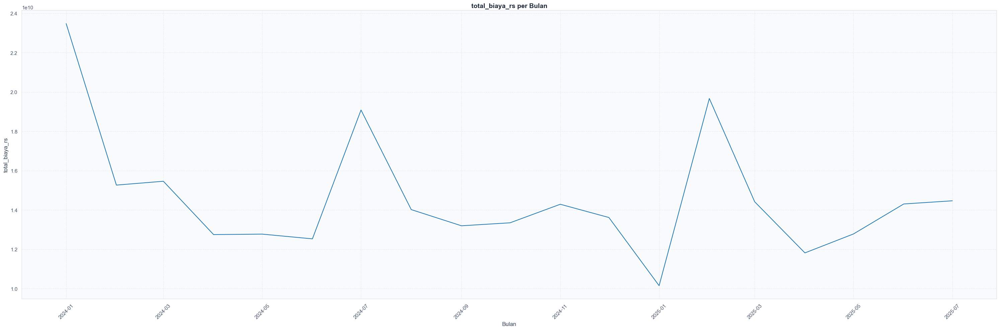

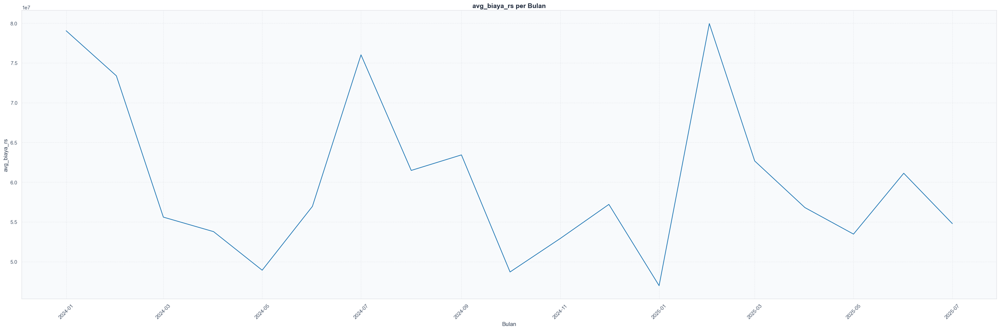

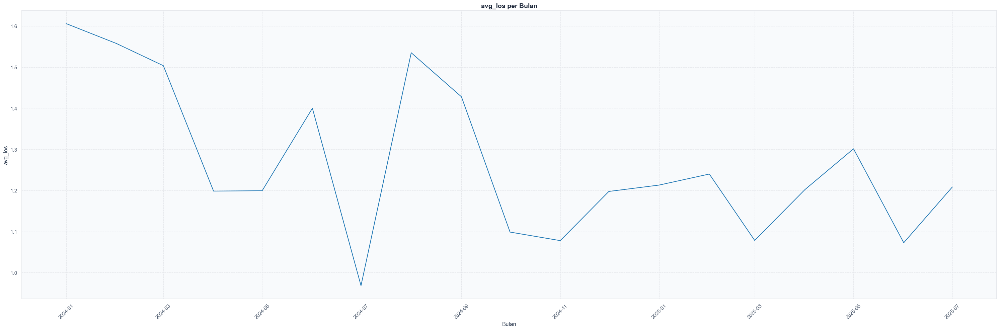

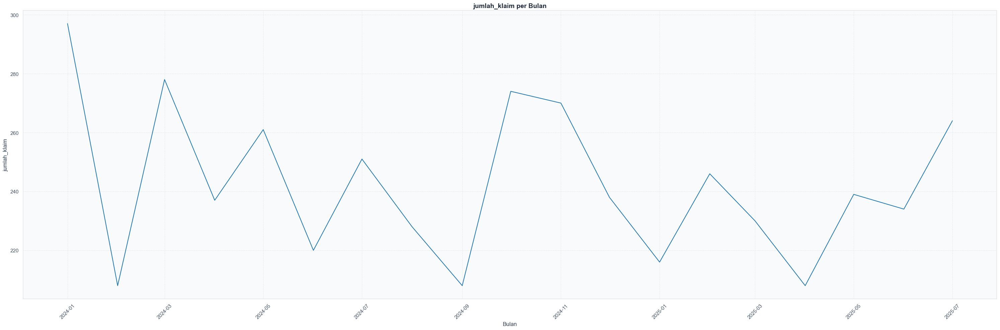

In [62]:
col_per_month = [
    'total_nominal_klaim',
    'avg_nominal_klaim',
    'total_biaya_rs',
    'avg_biaya_rs',
    'avg_los',
    'jumlah_klaim'
]

for col in col_per_month:
    plt.figure(figsize=(30, 10))
    sns.lineplot(
        x='YearMonth',
        y=col,
        data=df_month,
    )
    plt.title(f'{col} per Bulan')
    plt.xlabel('Bulan')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Dari hasil analisis data per bulan, kami mendapat kesimpulan sebagai berikut:
1. Nominal Klaim --> Ketika melihat data per bulan, nominal klaim menunjukkan pola seasonal yang ringan dengan beberapa lonjakan atau penurunan yang spesifik. Pada awal tahun terlihat bahwa nominal klaim cukup tinggi dan kemudian secara signifikan turun sampai bulan ke-4 tahun 2024. Kemudian pada pertengahan tahun 2024, terjadi peningkatan, namun puncak peningkatan terbesar terdapat pada awal tahun 2025 (sama seperti awal tahun 2024), menurut asumsi kami hal ini dapat terjadi akibat efek liburan akhir tahun, penyakit pasca libur, kembalinya aktivitas normal RS setelah libur, atau refresh limit benefit.
2. Biaya RS --> Kalau melihat biaya RS per bulan, kami juga dapat melihat bahwa terjadi penurunan yang sangat signifikan dari awal bulan 2024 ke sekitar bulan ke-5 2024. Kemudian terjadi peningkatan pada pertengahan tahun 2024, dan terjadi kembali peningkatan signifikan pada awal tahun 2025. Sama seperti asumsi sebelumnya, hal ini dapat terjadi akibat efek liburan akhir tahun, penyakit pasca liburan, kembalinya aktivitas normal RS, dan refresh limit asuransi
3. LOS dan Jumlah Klaim --> tidak ditemukan pola spesifik pada kedua fitur tersebut, grafik terlihat abstrak dan fluktuatif pada jumlah klaim.. Pada LOS, grafik terlihat menurun dan meningkat signifikan pada tahun 2024, dan cenderung stabil pada tahun 2025.

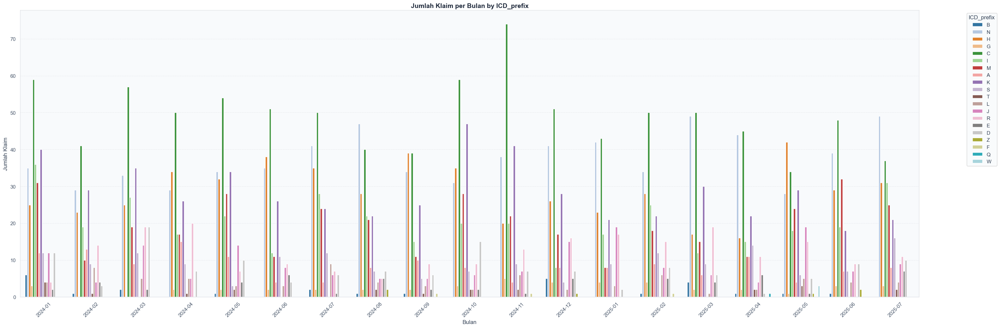

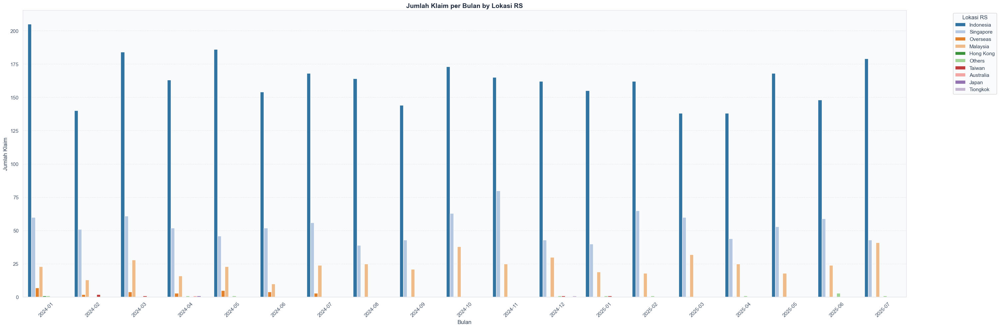

In [63]:
hue_cols = [
    'ICD_prefix',
    'Lokasi RS',
]

for col in hue_cols:
    plt.figure(figsize=(30, 10))
    sns.countplot(
        x='YearMonth',
        hue=col,
        data=df
    )
    plt.title(f'Jumlah Klaim per Bulan by {col}')
    plt.xlabel('Bulan')
    plt.ylabel('Jumlah Klaim')
    plt.xticks(rotation=45)
    plt.legend(title=col, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

Kami juga memeriksa data ICD dan Lokasi RS per bulannya, untuk melihat struktur dan pola data dengan lebih baik, berikut ini adalah kesimpulannya:
1. ICD --> Pada grafik di atas, kami melihat bahwa ICD yang selalu ada dan tinggi setiap bulan adalah C atau Kanker. Kemudian ICD lain nampak fluktuatif namun tetap tidak menyalip kanker. Kategori seperti penyakit ginjal, pencernaan, jantung, dll., muncul cukup stabil tiap bulan tetapi level berada di bawah kanker. Berdasarkan asumsi kami, Kanker menjadi salah satu penyakit yang top dan konsisten ntiap bulan karena Pengobatan kanker biasanya dilakukan secara rutin berdasarkan plan dari Rumah Sakit yang biasanya berkaitan dengan kemoterapi, checkup, dan kontrol ke dokter rutin
2. Lokasi RS --> Pada grafik di atas, kami melihat bahwa setiap bulannya lokasi RS yang paling banyak dikunjungi peserta untuk menjalani pengobatan adalah Indonesia, kemudian disusul oleh singapore dan Malaysia. Indonesia menjadi lokasi yang paling banyak dikarenakan pemegang polis seluruhnya berasal dari Indonesia. Berdasarkan asumsi kami, singapore dan malaysia menjadi opsi pilihan kedua karena lokasi yang relatif masih dekat dengan Indonesia, beberapa plan polis include negara tersebut dalam jangkauan lokasi pengobatan, dan singapore/malaysia memiliki treatment yang lengkap.

#### D.2.4. Visualization (/Quartile)

In [64]:
df['Quarter'] = df['Tanggal Pasien Masuk RS'].dt.to_period('Q')
df_quarter = (
    df.groupby('Quarter')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)

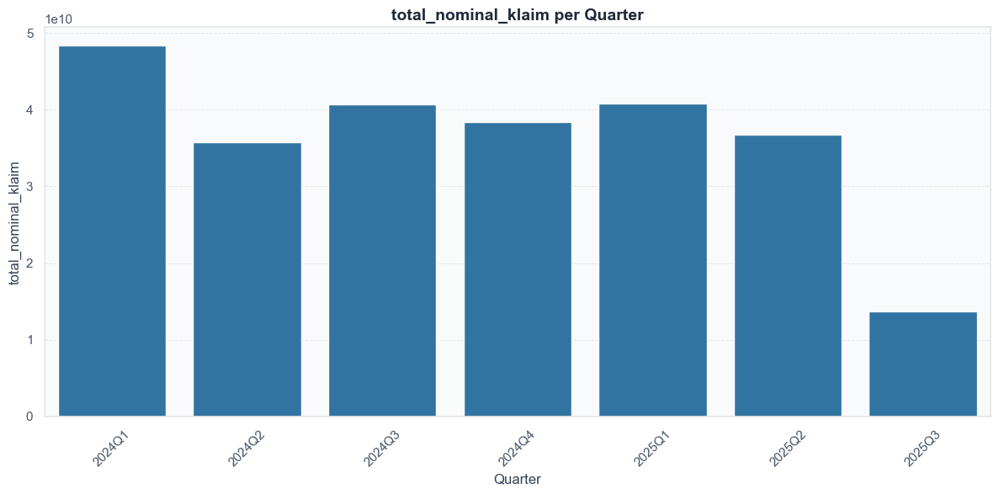

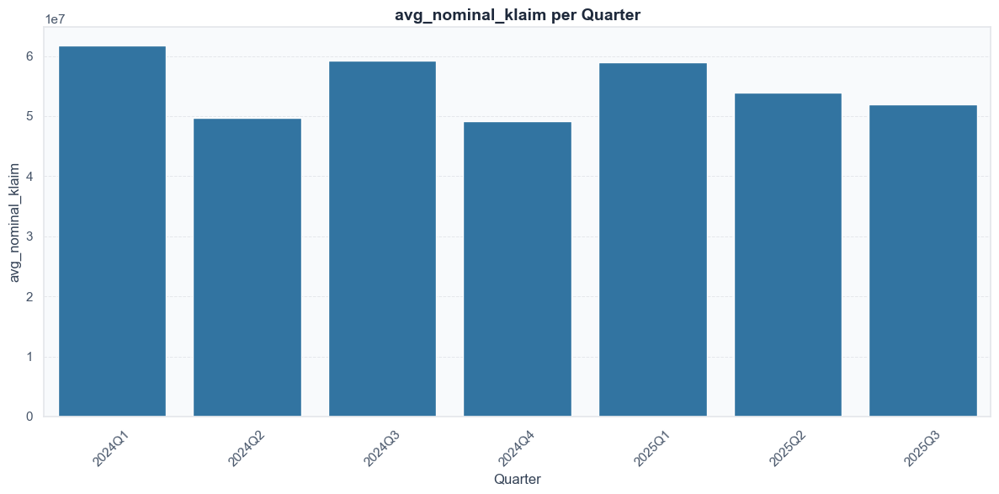

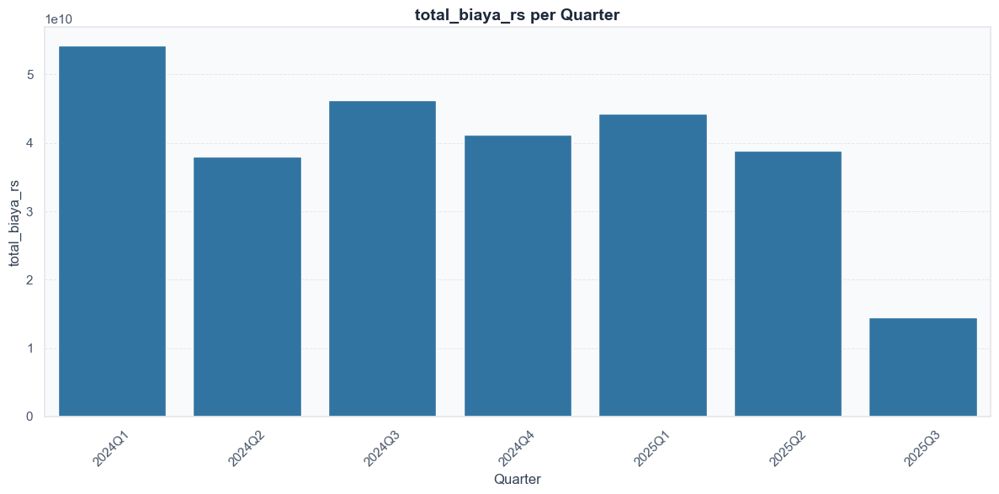

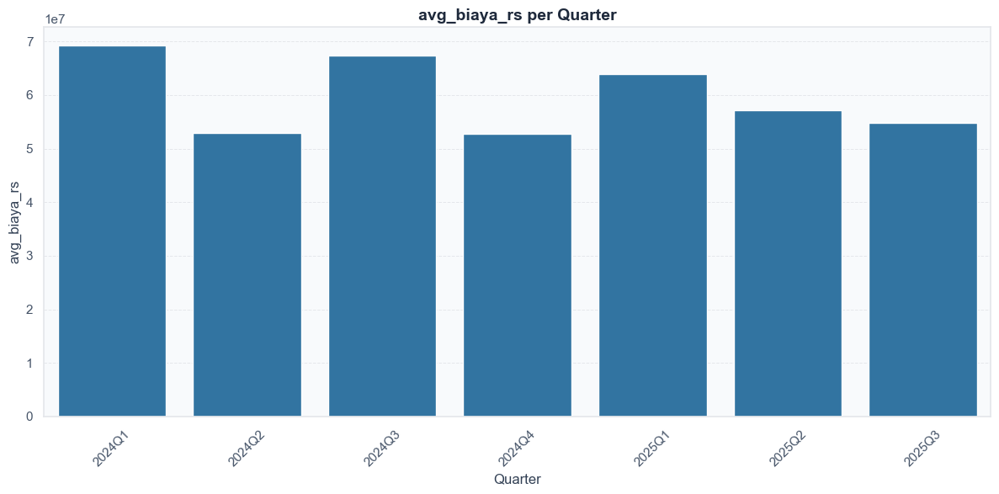

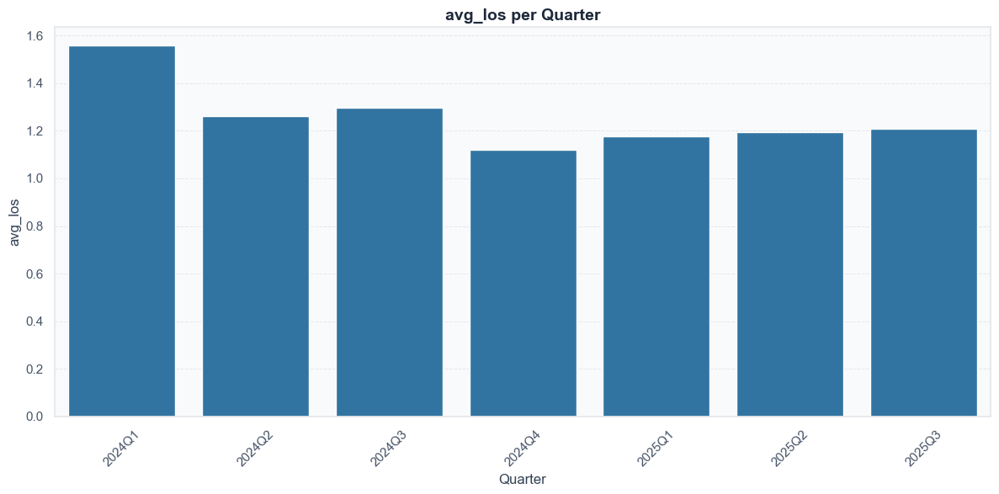

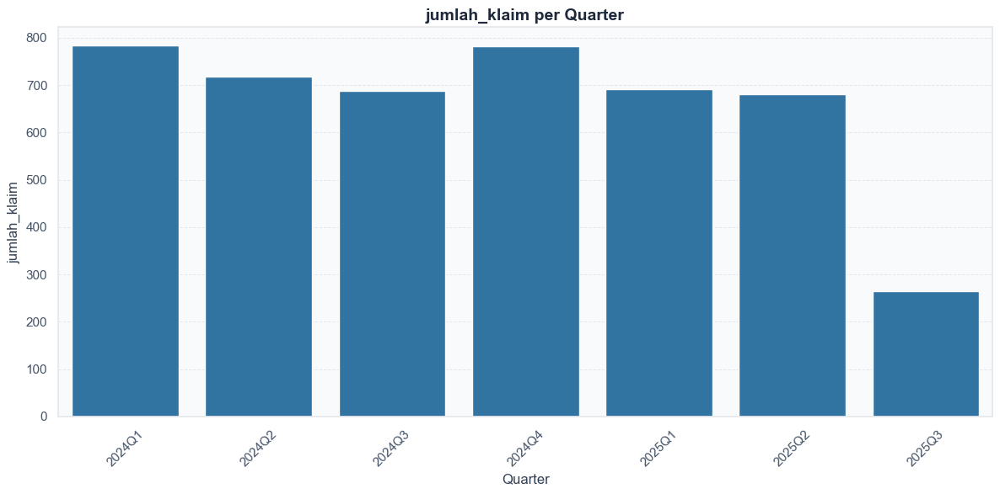

In [65]:
cols_per_quarter = [
    'total_nominal_klaim',
    'avg_nominal_klaim',
    'total_biaya_rs',
    'avg_biaya_rs',
    'avg_los',
    'jumlah_klaim'
]

for col in cols_per_quarter:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x='Quarter',
        y=col,
        data=df_quarter,
    )
    plt.title(f'{col} per Quarter')
    plt.xlabel('Quarter')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Setelah melihat analisis data per bulan, sekarang kita akan melihat data per kuartal, berikut ini adalah kesimpulan yang kami dapat:
1. Nominal Klaim --> Berdasarkan grafik di atas, kuartal Q1 tinggi pada 2024 dan 2025 (menandakan ada pola musiman pada Q1), kemudian Q2 cenderung turun dan kemudian Q3 rebound, kemudian Pada Q4 tahun 2024 terjadi penurunan kembali. Hal ini menandakan sebuah pola seasonality yaitu: Awal tahun cenderung tinggi, kemudian mereda pada pertengahan dan akhir tahun
2. Biaya RS --> Berdasarkan grafik di atas, hasil tidak beda jauh dengan nominal klaim. Biaya RS yang terjadi juga menunjukkan pola seasonality yang sama, yaitu: Awal tahun cenderung tinggi, kemudian mereda pada pertengahan tahun dan akhir tahun, serta terdapat rebound sedikit pada Q3
3. Perlu di notes yaitu, Q3 pada tahun 2025 hanya berisi bulan Juli saja

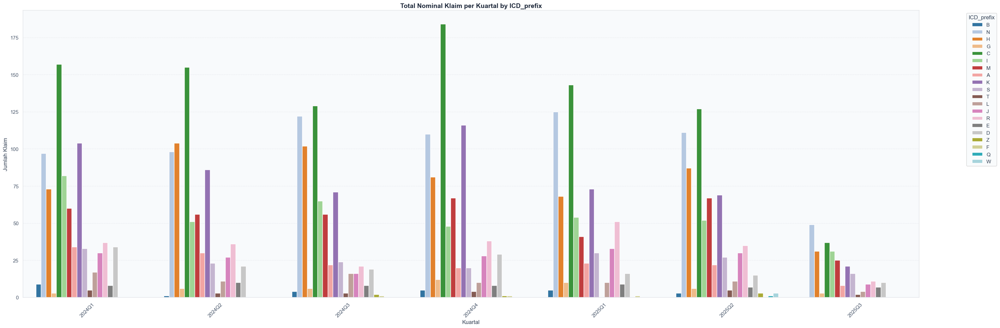

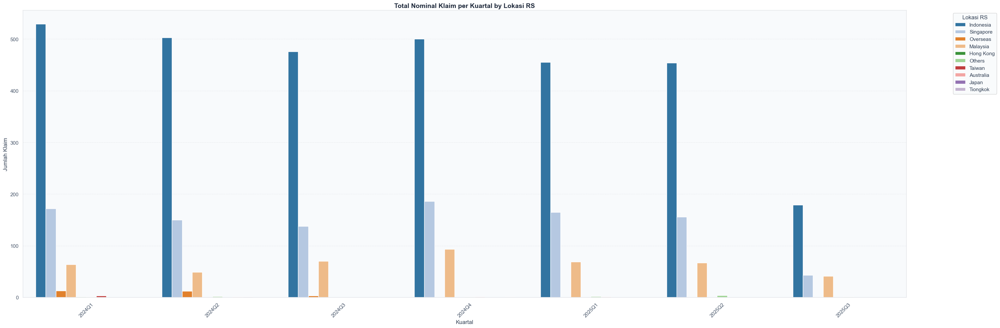

In [66]:
hue_cols = [
    'ICD_prefix',
    'Lokasi RS',
]

for col in hue_cols:
    plt.figure(figsize=(30, 10))
    sns.countplot(
        x='Quarter',
        hue=col,
        data=df
    )
    plt.title(f'Total Nominal Klaim per Kuartal by {col}')
    plt.xlabel('Kuartal')
    plt.ylabel('Jumlah Klaim')
    plt.xticks(rotation=45)
    plt.legend(title=col, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

Kemudian kami juga melakukan analisis ICD dan Lokasi RS berdasarkan kuartal, kesimpulan yang kami dapat adalah sebagai berikut:
1. ICD --> Sama seperti analisis per bulan, Cancer menjadi penyakit yang selalu ada dan tinggi setiap kuartalnya. Kemudian disusul dengan penyakit ginjal dan salurah kemih, mata/telinga, pencernaan, dan jantung yang muncul setiap kuartal namun tidak melebihi Kanker.
2. Lokasi RS --> Pada setiap kuartal Indonesia selalu menjadi lokasi utama pengobatan peserta, kemudian disusul dengan Singapore/Malaysia. Asumsi kami tetap sama seperti analisis pada analisis per bulan, yaitu peserta seluruhnya berdasarkan dari Indonesia, kemudian Singapore/Malaysia menjadi opsi kedua pengobatan karena lokasi yang dekat dengan Indonesia, beberapa plan polis mmenjangkau RS di luar negeri, dan treatment yang lengkap untuk berbagai penyakit

#### D.3. Relation Between Features and Target

Pada bagian ini, kita akan mulai melihat relasi antara fitur dengan target/label yang akan kami prediksi. Tujuannya adalah untuk melihat pengaruh setiap fitur dengan target yang nantinya berguna untuk menentukan fitur mana yang akan digunakan untuk mendukung prediksi

#### D.3.1. ICD

In [67]:
df_icd_avg = (
    df.groupby('ICD_prefix')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)
df_sorted_icd = df_icd_avg.sort_values('total_nominal_klaim', ascending=False)

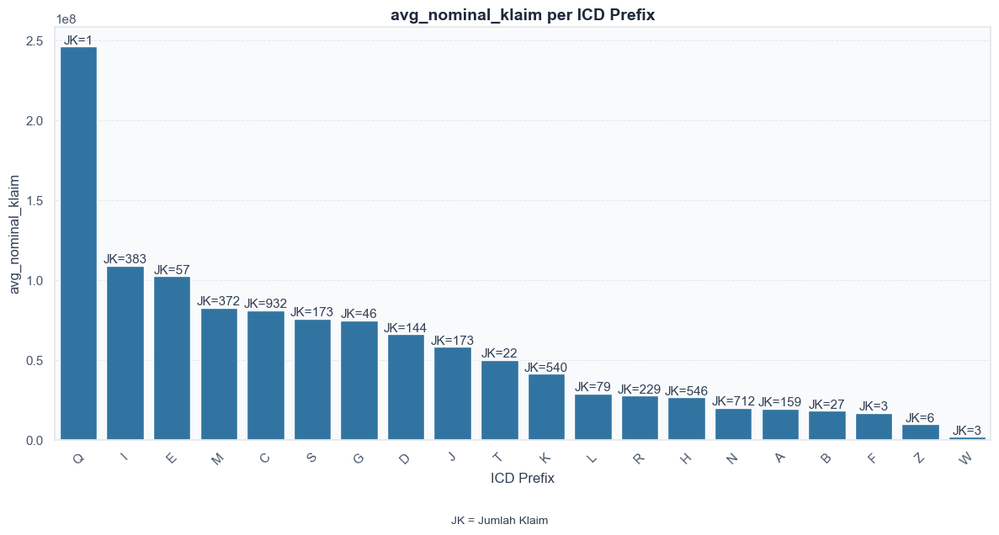

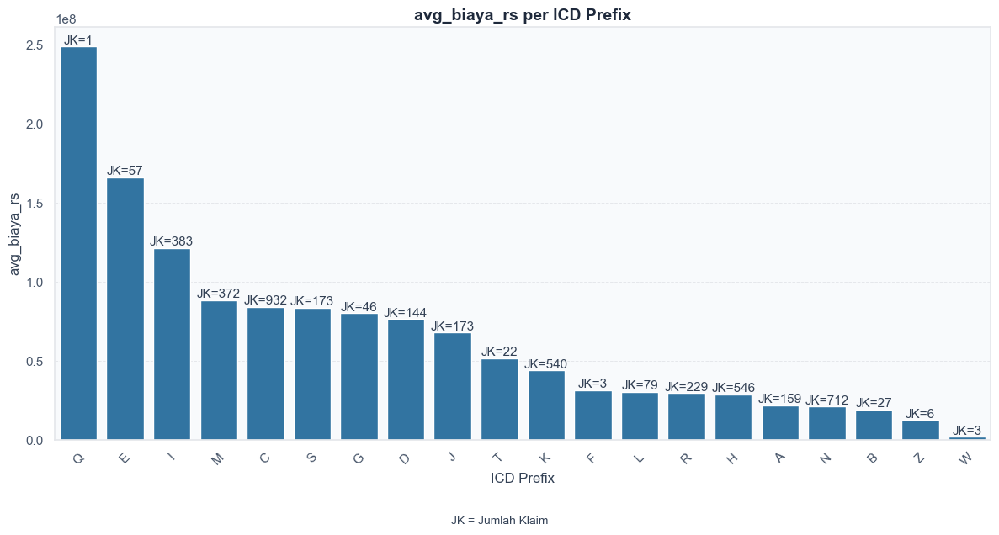

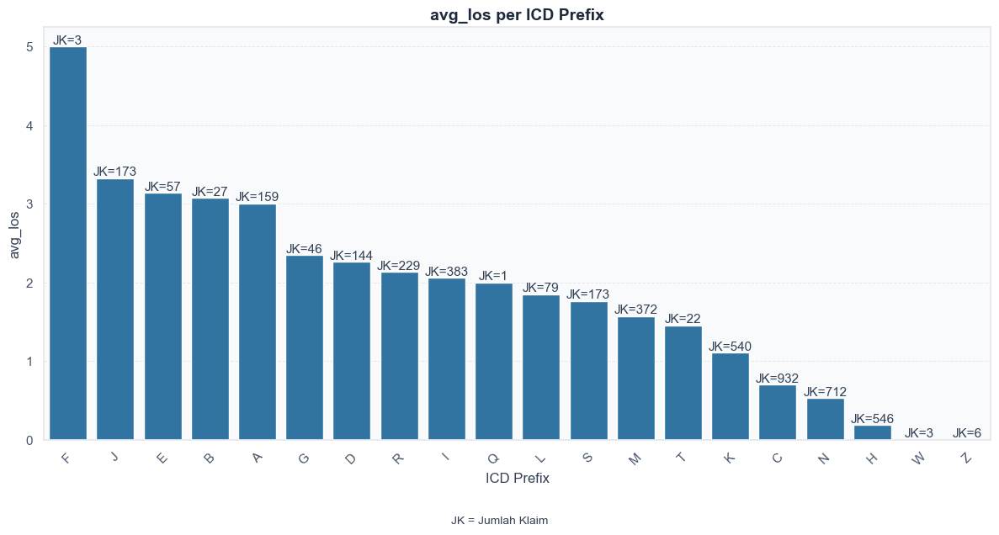

In [68]:
icd_avg_col = [
    'avg_nominal_klaim',
    'avg_biaya_rs',
    'avg_los',
]

for col in icd_avg_col:
    df_plot = df_icd_avg.sort_values(col, ascending=False)
    plt.figure(figsize=(12,6))
    ax = sns.barplot(
        x='ICD_prefix',
        y=col,
        data=df_plot,
    )
    for i, row in df_plot.iterrows():
        ax.text(
            x=list(df_plot.index).index(i),
            y=row[col],
            s=f"JK={row['jumlah_klaim']}",
            ha='center',
            va='bottom'
        )

    plt.title(f'{col} per ICD Prefix')
    plt.xlabel('ICD Prefix')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.figtext(
        0.5, -0.05,
        "JK = Jumlah Klaim",
        ha="center",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

In [69]:
df_icd_avg

,ICD_prefix,total_nominal_klaim,avg_nominal_klaim,total_biaya_rs,avg_biaya_rs,avg_los,jumlah_klaim
0,A,3.107333e+09,1.954297e+07,3.451078e+09,2.170490e+07,3.006289,159
1,B,4.894437e+08,1.812754e+07,5.151678e+08,1.908029e+07,3.074074,27
2,C,7.540895e+10,8.091089e+07,7.841878e+10,8.414033e+07,0.700644,932
3,D,9.504117e+09,6.600082e+07,1.102408e+10,7.655609e+07,2.263889,144
4,E,5.828394e+09,1.022525e+08,9.469254e+09,1.661273e+08,3.140351,57
5,F,5.058816e+07,1.686272e+07,9.443570e+07,3.147857e+07,5.000000,3
6,G,3.431875e+09,7.460599e+07,3.691391e+09,8.024762e+07,2.347826,46
7,H,1.445742e+10,2.647880e+07,1.563355e+10,2.863287e+07,0.186813,546
8,I,4.174924e+10,1.090059e+08,4.652795e+10,1.214829e+08,2.057441,383
9,J,1.006699e+10,5.819070e+07,1.176704e+10,6.801758e+07,3.323699,173


Berdasarkan grafik per ICD di atas, kami mendapatkan kesimpulan sebagai berikut:
1. Nominal Klaim --> Pada grafik, menunjukkan bahwa setiap ICD memiliki rata-rata yang nominal klaim yang berbeda, tentu ini berkaitan dengan jenis pengobatan dan berapa harga pengobatan untuk penyakit tersebut. Namun perlu diingat kembali bahwa untuk penyakit Q hanya memiliki Jumlah Klaim 1, sehingga nilai rata-ratanya tidak sepenuhnya valid dan tidak dapat dijadikan untuk analisis. Berdasarkan grafik, yang paling tinggi setelah Q adalah, penyakit jantung dan pembuluh darah, hormon dan metabolisme, otot dan tulang, serta kanker. Hal ini menunjukkan bahwa beberapa penyakit kronis menunjukkan biaya pengobatan yang tinggi juga.
2. Biaya RS --> Pada grafik, untuk biaya RS tidak jauh berbeda dengan nominal klaim, namun perbedaan hanya terlihat pada urutan E dan I. Pada Biaya RS, penyakit dengan rata-rata biaya RS tertinggi setelah Q adalah penyakit hormon dan metabolisme, jantung dan pembuluh darah, otot dan tulang, kemudian kanker. Hal ini menunjukkan juga bahwa penyakit kronis memiliki biaya pengobatan yang cenderung tinggi juga dibandingkan penyakit infeksi atau injury yang disebabkan faktor eksternal
3. LOS --> Pada grafik, terlihat bahwa penyakit ICD tidak terlalu memiliki rata-rata Length of Stay yang berbeda signifikan. Namun terdapat penyakit yang memiliki LOS tertinggi yaitu F atau Penyakit berkaitan dengan gangguan mental dan perilaku. Kemudian disusul dengan penyakit-penyakit dengan LOS sekitar 3 hari, yaitu penyakit sistem pernafasan, hormon dan metabolisme, serta infeksi dan parasit. Berdasarkan asumsi kami, penyakit mental bukan hanya membutuhkan perawatan medis melainkan juga membutuhkan observasi stabilitas perilaku, sehingga membutuhan waktu LOS lebih lama. Beberapa penyakit lain juga membutuhkan recovery yang lebih lama, misalkan penyakit DBD yang perlu menunggu Trombosit naik baru diizinkan untuk pulang.

#### D.3.2. Inpatient/Outpatient

In [70]:
df_avg_in_out = (
    df.groupby('Inpatient/Outpatient')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)

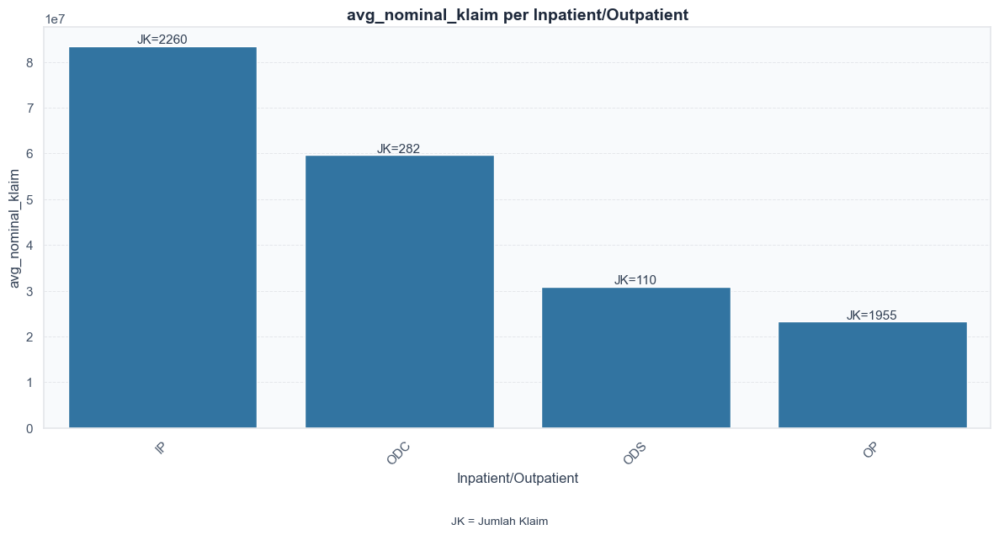

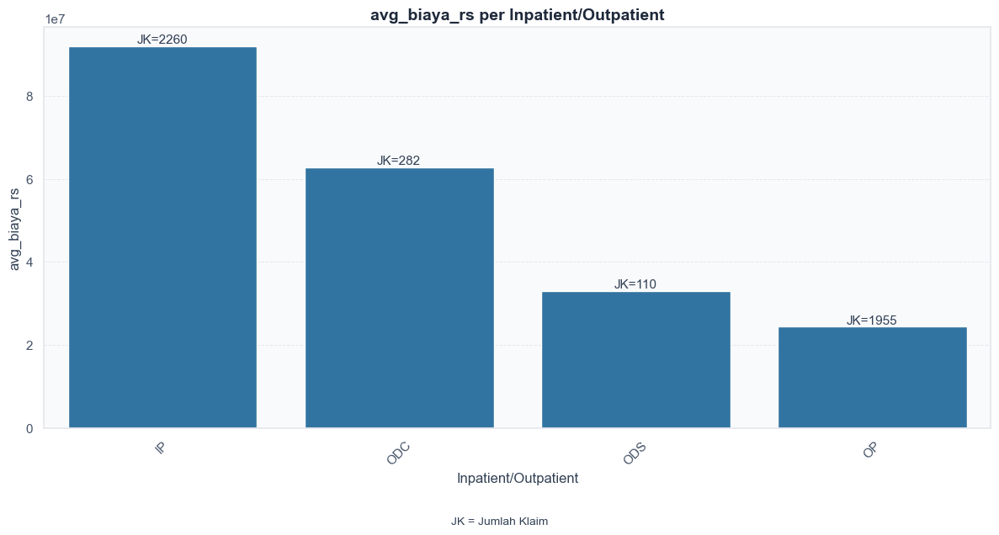

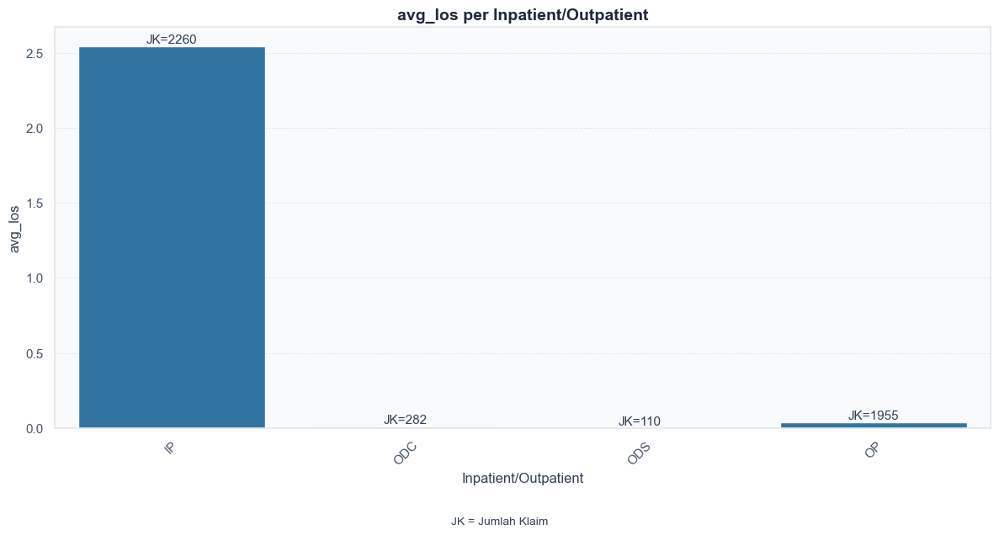

In [71]:
in_out_col = [
    'avg_nominal_klaim',
    'avg_biaya_rs',
    'avg_los',
]

for col in in_out_col:
    plt.figure(figsize=(12,6))
    ax = sns.barplot(
        x='Inpatient/Outpatient',
        y=col,
        data=df_avg_in_out,
    )
    for i, row in df_avg_in_out.iterrows():
        ax.text(
            x=list(df_avg_in_out.index).index(i),
            y=row[col],
            s=f"JK={row['jumlah_klaim']}",
            ha='center',
            va='bottom'
        )

    plt.title(f'{col} per Inpatient/Outpatient')
    plt.xlabel('Inpatient/Outpatient')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.figtext(
        0.5, -0.05,
        "JK = Jumlah Klaim",
        ha="center",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

In [72]:
df_avg_in_out

,Inpatient/Outpatient,total_nominal_klaim,avg_nominal_klaim,total_biaya_rs,avg_biaya_rs,avg_los,jumlah_klaim
0,IP,1.887113e+11,8.350059e+07,2.081099e+11,9.208404e+07,2.547345,2260
1,ODC,1.682628e+10,5.966764e+07,1.772722e+10,6.286247e+07,0.010638,282
2,ODS,3.393397e+09,3.084907e+07,3.632020e+09,3.301837e+07,0.000000,110
3,OP,4.549628e+10,2.327175e+07,4.787340e+10,2.448767e+07,0.039386,1955


Berdasarkan analisis kami, berikut adalah kesimpulan yang kami dapatkan:
1. Perawatan yang memerlukan perawatan rawat inap atau inpatient (IP) tentu saja akan memiliki rata-rata nominal klaim dan biaya RS yang lebih tinggi. Karena artinya, pengobatan dilakukan lebih lama dan perlu membayar fasilitas rumah sakit selama melakukan perawatan rawat inap.
2. Disusul dengan ODC dan ODS. Berdasarkan asumsi kami, ODC dan ODS memiliki rata-rata klaim dan biaya RS lebih tinggi dari OP (outpatient) dikarenakan ODS/ODC melibatkan tindakan yang lebih intensif dibandingkan biaya rawat jalan biasa (OP)

#### D.3.3. Plan Code

In [73]:
df_avg_plan_code = (
    df.groupby('Plan Code')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)

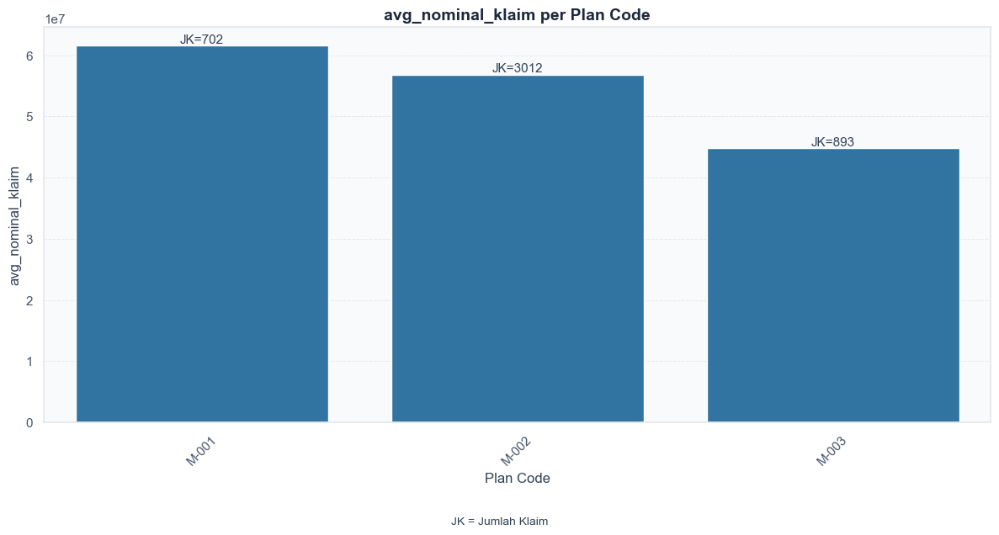

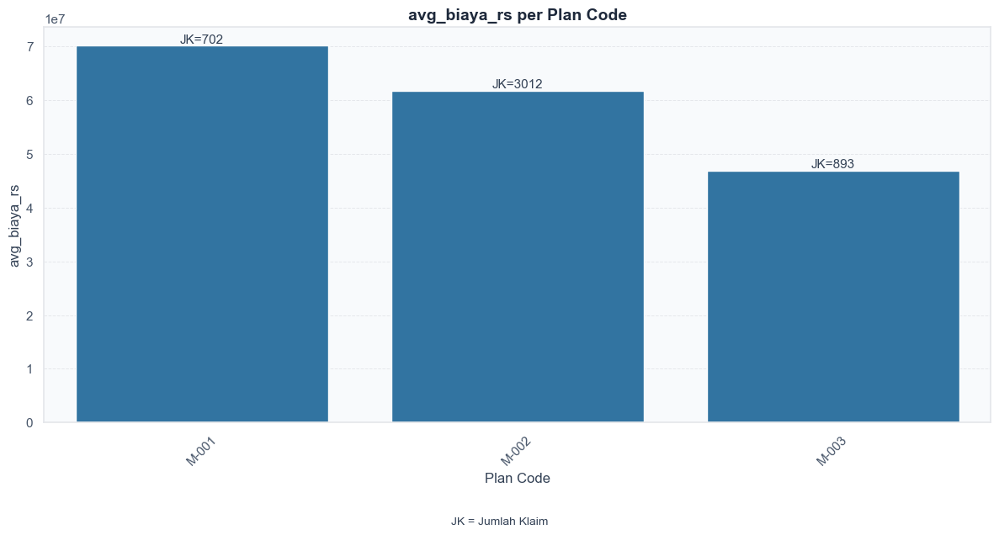

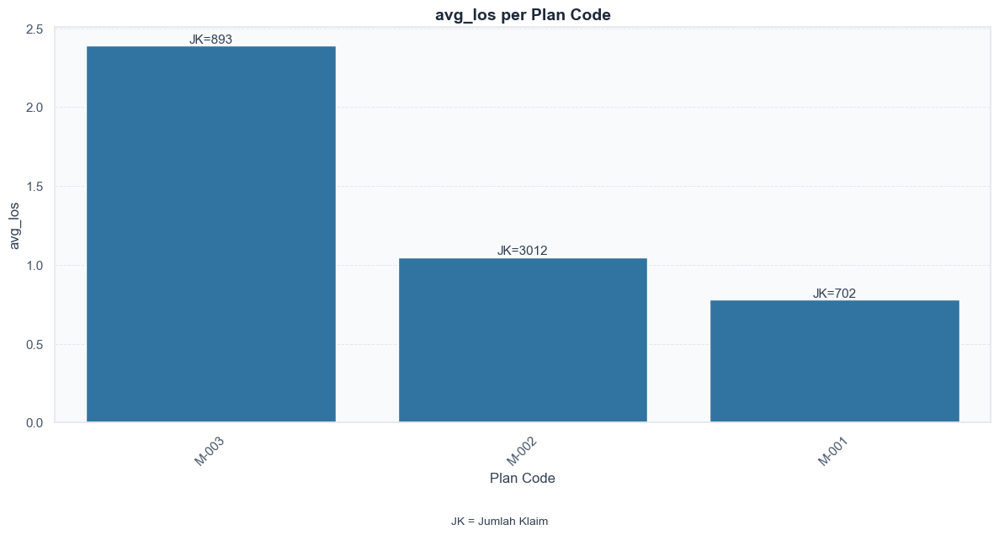

In [74]:
plan_code_col = [
    'avg_nominal_klaim',
    'avg_biaya_rs',
    'avg_los',
]

for col in plan_code_col:
    df_plot = df_avg_plan_code.sort_values(col, ascending=False)
    plt.figure(figsize=(12,6))
    ax = sns.barplot(
        x='Plan Code',
        y=col,
        data=df_plot,
    )
    for i, row in df_plot.iterrows():
        ax.text(
            x=list(df_plot.index).index(i),
            y=row[col],
            s=f"JK={row['jumlah_klaim']}",
            ha='center',
            va='bottom'
        )

    plt.title(f'{col} per Plan Code')
    plt.xlabel('Plan Code')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.figtext(
        0.5, -0.05,
        "JK = Jumlah Klaim",
        ha="center",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

In [75]:
df_avg_plan_code

,Plan Code,total_nominal_klaim,avg_nominal_klaim,total_biaya_rs,avg_biaya_rs,avg_los,jumlah_klaim
0,M-001,4.321740e+10,6.156325e+07,4.925964e+10,7.017042e+07,0.779202,702
1,M-002,1.712006e+11,5.683951e+07,1.861838e+11,6.181401e+07,1.047809,3012
2,M-003,4.000928e+10,4.480322e+07,4.189915e+10,4.691954e+07,2.389698,893


Berdasarkan analisis di atas, kami menemukan beberapa kesimpulan dan asumsi, sebagai berikut:
1. Dari grafik di atas, kami melihat bahwa M-001 memiliki rata-rata klaim dan biaya RS tertinggi, kemudian disusul dengan M-002 dan M-003 terlepas dari jumlah klaim yang terjadi
2. Berdasarkan asumsi kami, hal ini menunjukkan bahwa M-001 adalah plan polis yang memiliki benetfit yang lebih besar kepada client, kemudian M-002 adalah plan polis standard (didukung juga dengan banyaknya pemegang polis ini), dan M-003 sebagai plan polis dengan manfaat cukup

#### D.3.4. LOS

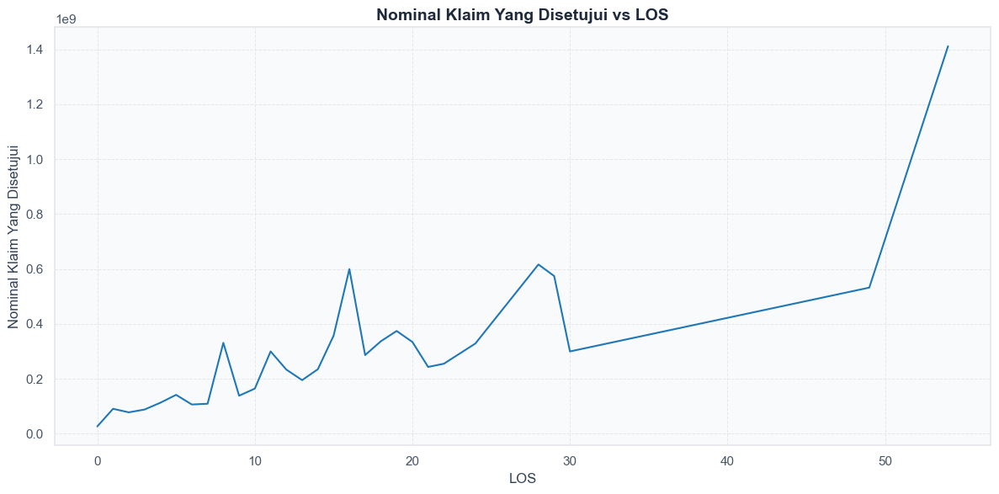

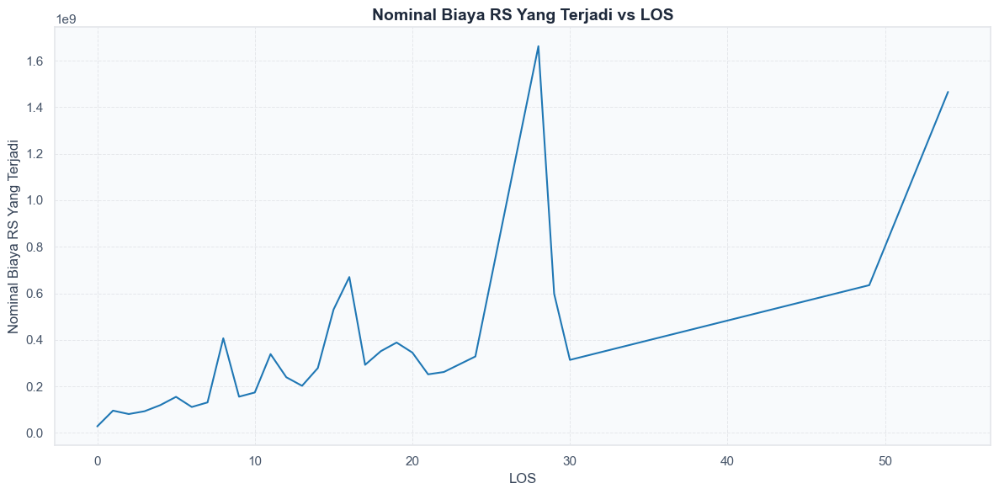

In [76]:
los_relation_col = [
    'Nominal Klaim Yang Disetujui',
    'Nominal Biaya RS Yang Terjadi',
]

for col in los_relation_col:
    plt.figure(figsize=(12, 6))
    sns.lineplot(
        x='LOS',
        y=col,
        data=df,
        errorbar=None
    )
    plt.title(f'{col} vs LOS')
    plt.xlabel('LOS')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

Berdasarkan grafik di atas, dapat diambil kesimpulan bahwa:
1. Semakin tinggi LOS atau semakin lama perawatan rawat inap yang dijalankan, nominal klaim dan biaya RS yang terjadi akan ikut meningkat juga
2. Hal ini tentu disebabkan karena perawatan inap membutuhkan pengobatan yang lebih lama, pembayaran kamar, penggunaan fasilitas RS, sehingga semakin lama rawat inap, maka harga yang harus dibayarkan juga akan ikut meningkat

#### D.3.5. Lokasi RS

In [77]:
df_avg_loc = (
    df.groupby('Lokasi RS')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
        avg_los=('LOS', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)

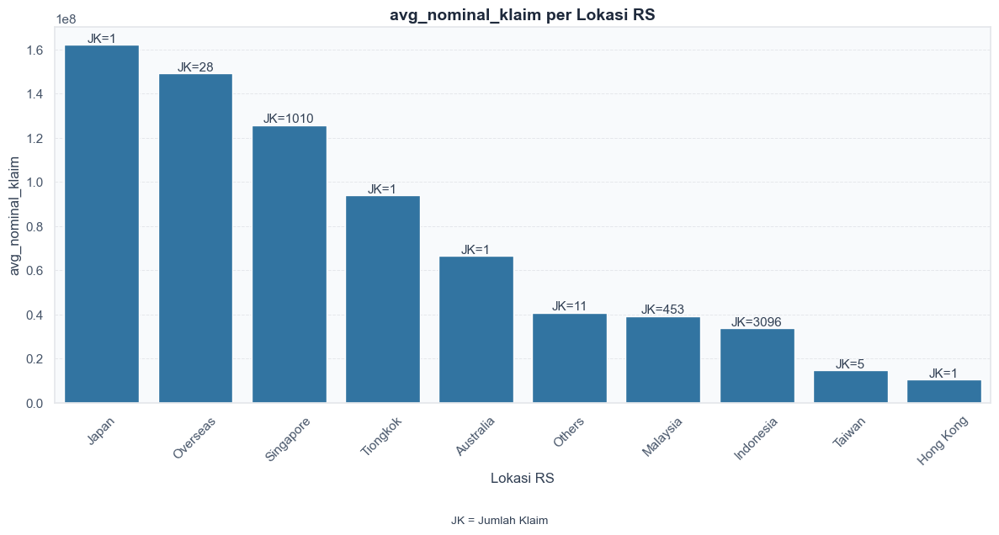

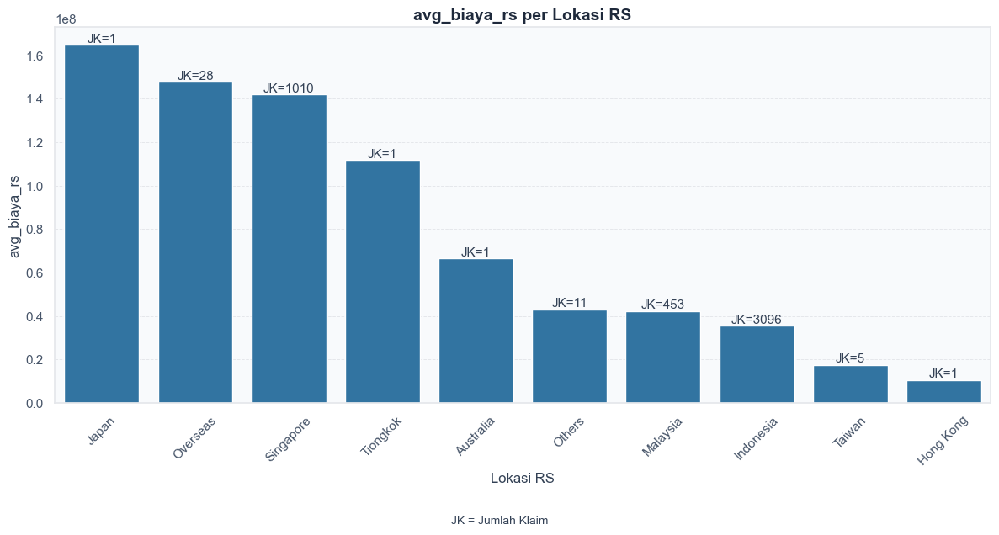

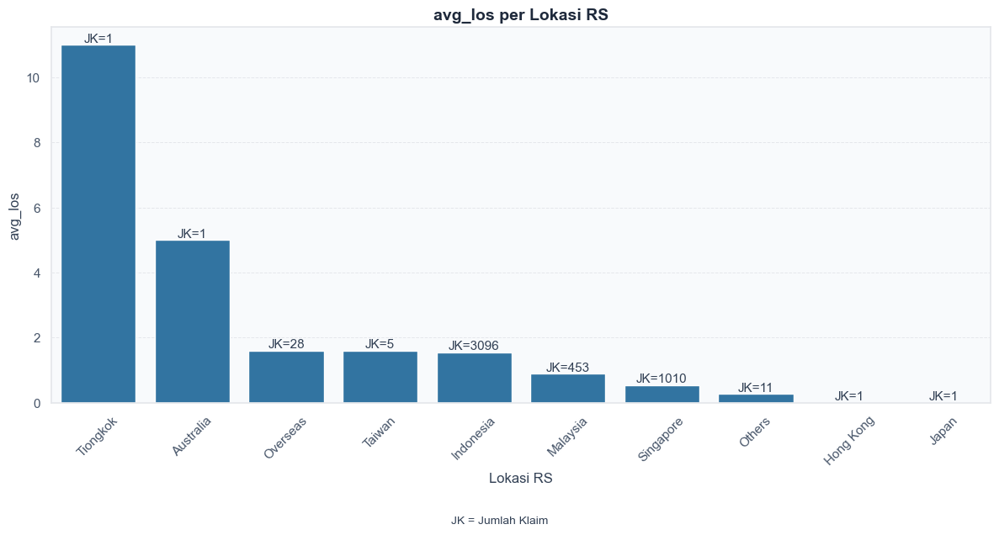

In [78]:
avg_loc_col = [
    'avg_nominal_klaim',
    'avg_biaya_rs',
    'avg_los',
]

for col in avg_loc_col:
    df_plot = df_avg_loc.sort_values(col, ascending=False)
    plt.figure(figsize=(12,6))
    ax = sns.barplot(
        x='Lokasi RS',
        y=col,
        data=df_plot,
    )
    for i, row in df_plot.iterrows():
        ax.text(
            x=list(df_plot.index).index(i),
            y=row[col],
            s=f"JK={row['jumlah_klaim']}",
            ha='center',
            va='bottom'
        )

    plt.title(f'{col} per Lokasi RS')
    plt.xlabel('Lokasi RS')
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.figtext(
        0.5, -0.05,
        "JK = Jumlah Klaim",
        ha="center",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

In [79]:
df_avg_loc

,Lokasi RS,total_nominal_klaim,avg_nominal_klaim,total_biaya_rs,avg_biaya_rs,avg_los,jumlah_klaim
0,Australia,6.642524e+07,6.642524e+07,6.642524e+07,6.642524e+07,5.000000,1
1,Hong Kong,1.055722e+07,1.055722e+07,1.055722e+07,1.055722e+07,0.000000,1
2,Indonesia,1.045371e+11,3.376521e+07,1.098111e+11,3.546872e+07,1.552326,3096
3,Japan,1.621877e+08,1.621877e+08,1.648238e+08,1.648238e+08,0.000000,1
4,Malaysia,1.778044e+10,3.925041e+07,1.916048e+10,4.229687e+07,0.894040,453
5,Others,4.478225e+08,4.071114e+07,4.736110e+08,4.305555e+07,0.272727,11
6,Overseas,4.178380e+09,1.492278e+08,4.137285e+09,1.477602e+08,1.607143,28
7,Singapore,1.270768e+11,1.258186e+08,1.433190e+11,1.419000e+08,0.548515,1010
8,Taiwan,7.370061e+07,1.474012e+07,8.761772e+07,1.752354e+07,1.600000,5
9,Tiongkok,9.386476e+07,9.386476e+07,1.116762e+08,1.116762e+08,11.000000,1


Berdasarkan grafik di atas, dapat diambil kesimpulan bahwa:
1. Lokasi RS di luar Indonesia, rata-rata memiliki average klaim dan biaya RS yang lebih tinggi dibandingkan Indonesia, walaupun beberapa lokasi hanya memiliki 1 Jumlah Klaim dan kurang dapat diuji kebenarannya hanya lewat 1 data saja
2. Namun berdasarkan asumsi kami, hal ini dapat dianggap benar dan lokasi RS berpengaruh terhadap nominal klaim dan biaya RS terjadi, dikarenakan teknologi dan obat, perawatan intensif, kurs dan biaya transaksi, serta faktor lainnya

#### D.3.6. Usia

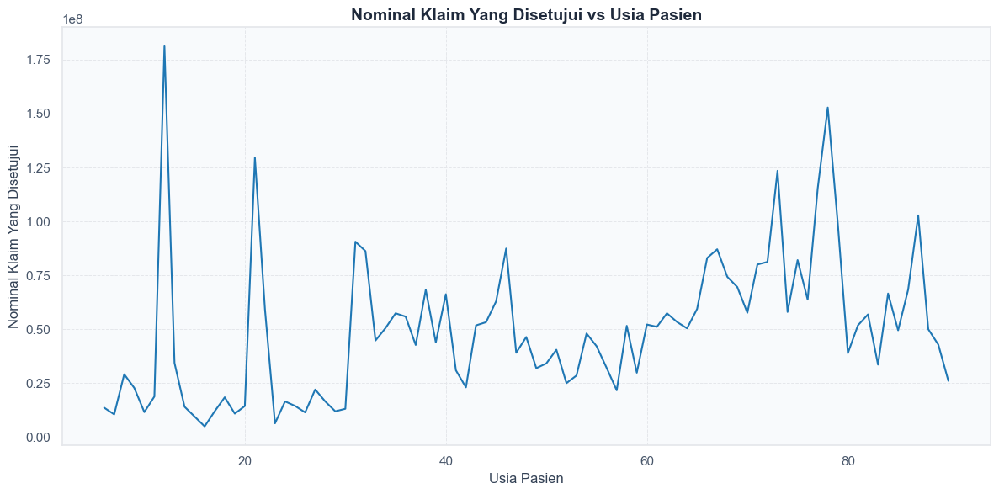

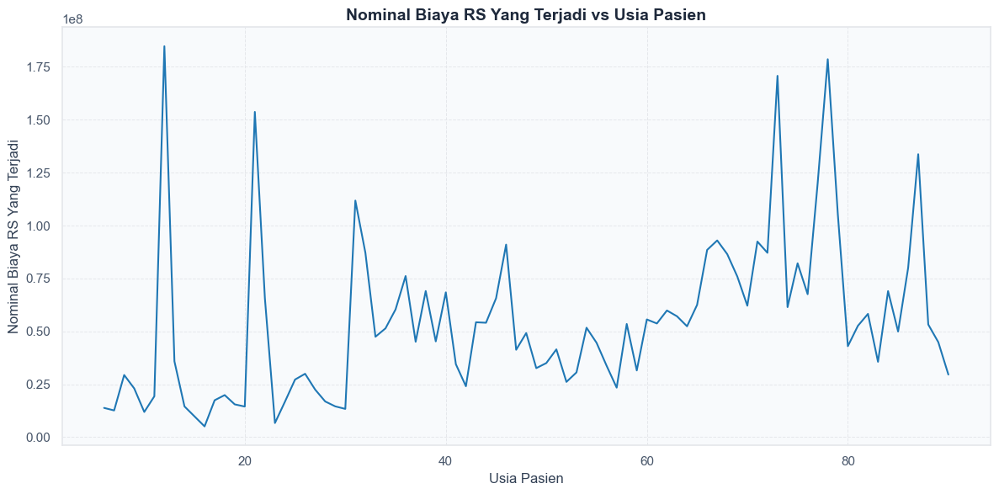

In [80]:
usia_relation_col = [
    'Nominal Klaim Yang Disetujui',
    'Nominal Biaya RS Yang Terjadi',
]

for col in usia_relation_col:
    plt.figure(figsize=(12, 6))
    sns.lineplot(
        x='Usia Pasien',
        y=col,
        data=df,
        errorbar=None
    )
    plt.title(f'{col} vs Usia Pasien')
    plt.xlabel('Usia Pasien')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

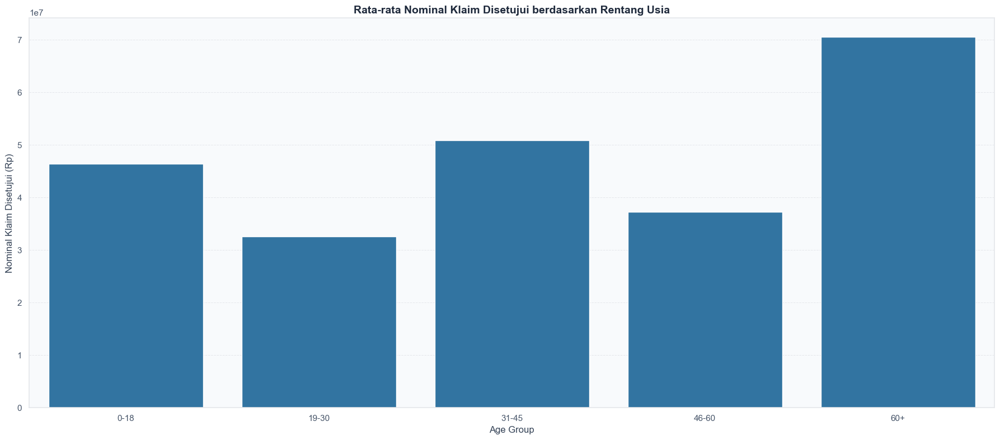

In [81]:
bins = [0, 18, 30, 45, 60, np.inf]
labels = ['0-18', '19-30', '31-45', '46-60', '60+']
df['Rentang Usia'] = pd.cut(df['Usia Pasien'], bins=bins, labels=labels, right=False)
plt.figure(figsize=(18, 8))
sns.barplot(
    data=df,
    x='Rentang Usia',
    y='Nominal Klaim Yang Disetujui',
    errorbar=None
)
plt.title('Rata-rata Nominal Klaim Disetujui berdasarkan Rentang Usia')
plt.xlabel('Age Group')
plt.ylabel('Nominal Klaim Disetujui (Rp)')
plt.tight_layout()
plt.show()

Berdasarkan grafik di atas, berikut adalah beberapa kesimpulan yang dapat diambil:
1. Berdasarkan grafik lineplot, kami melihat lonjakan yang tinggi pada rentang umur dibawah 20 dan di atas 70 tahun. Sedangkan pada rentang usia menengah (dewasa), cenderung memiliki rata-rata nominal klaim dan biaya RS yang stabil
2. Berdasarkan grafik barplot, kami juga melihat bahwa rata-rata nominal klaim yang tinggi berada pada rentang usia 60 tahun ke atas, dan usia muda juga cenderung cukup tinggi 
3. Menurut asumsi kami, rentang usia 60 tahun ke atas akan membutuhkan perawatan yang lebih intensif, resiko komplikasi, monitoring lebih ketat, penyakit kronis yang diderita pasien usia lanjut. Hal ini menyebabkan nominal rata-rata klaim usia lanjut akan lebih tinggi.
4. Artinya usia secara tidak langsung dapat mempengaruhi prediksi nominal klaim 

#### D.3.7. Approval Ratio

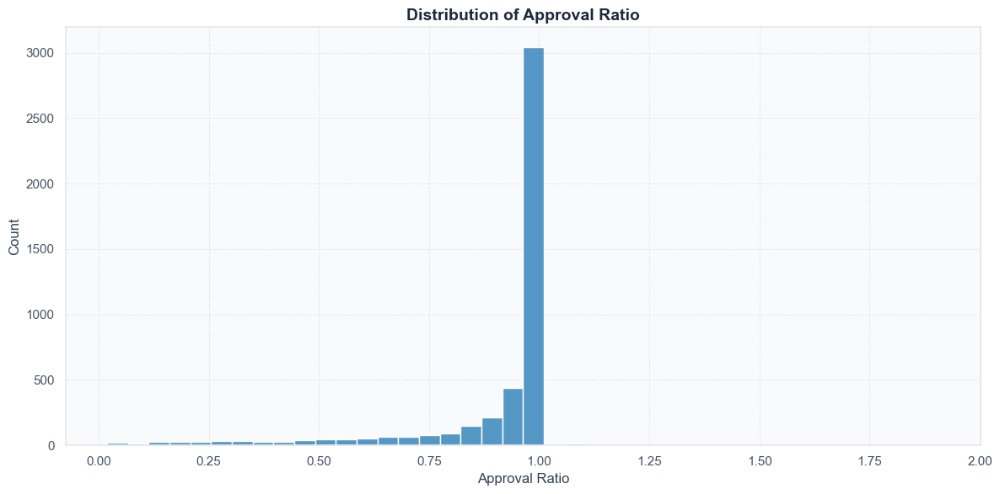

In [82]:
plt.figure(figsize=(12, 6))
sns.histplot(
    x='approval_ratio',
    data=df,
    bins=40,
)
plt.title('Distribution of Approval Ratio')
plt.xlabel('Approval Ratio')
plt.tight_layout()
plt.show()

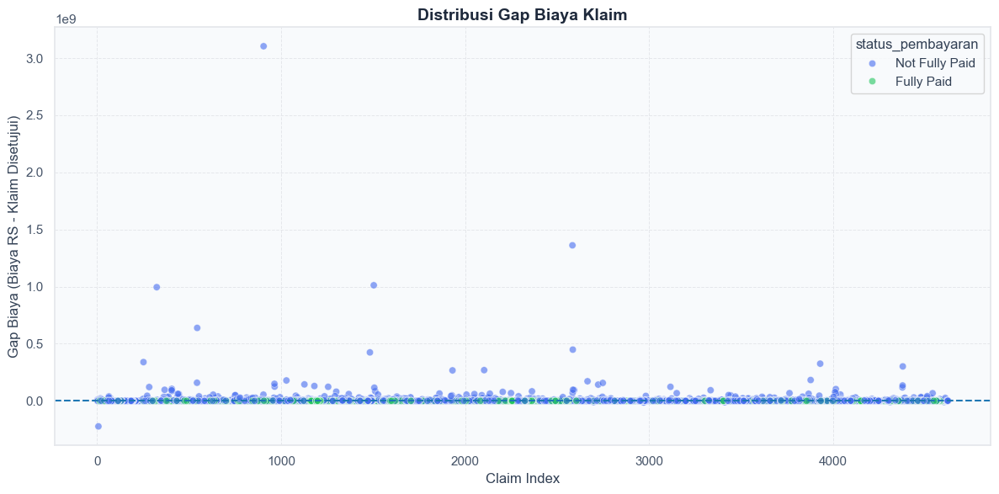

In [83]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    x=df.index,
    y='gap_biaya',
    hue='status_pembayaran',
    data=df,
    alpha=0.6,
    palette={
        'Fully Paid': '#22C55E',     
        'Not Fully Paid': "#446CEF"  
    },
)

plt.title('Distribusi Gap Biaya Klaim')
plt.xlabel('Claim Index')
plt.ylabel('Gap Biaya (Biaya RS - Klaim Disetujui)')

plt.axhline(0, linestyle='--')

plt.tight_layout()
plt.show()

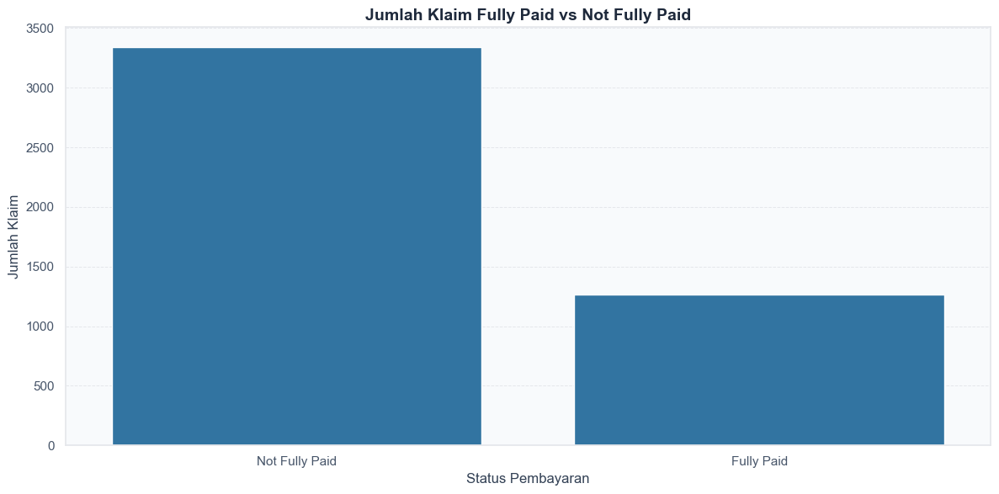

In [84]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='status_pembayaran',
)

plt.title('Jumlah Klaim Fully Paid vs Not Fully Paid')
plt.xlabel('Status Pembayaran')
plt.ylabel('Jumlah Klaim')
plt.tight_layout()
plt.show()

Berdasarkan grafik di atas, dapat diambil kesimpulan sebagai berikut:
1. Berdasarkan grafik distribusi ratio, terlihat bahwa approval ratio cenderung mendekati angka 1, yang artinya perusahaan asuransi secara penuh membayar biaya RS terjadi (Full Cover/Paid)
2. Terdapat juga beberapa kasus yang approval ratio berada di atas 1, yang artinya nominal klaim lebih tinggi dari biaya RS terjadi. Hal ini kami asumsikan dapat terjadi akibat benefit dari plan polis atau faktor lainnya
3. Walaupun tidak semua klaim dibayarkan secara penuh, kami melihat kecenderungan perusahaan konsisten untuk membayar biaya RS sehingga peserta pemegang polis tidak perlu membayar gap biaya (excess). Hal ini menunjukkan perusahaan asuransi AXA mampu untuk menjaga konsistensi dalam cover biaya RS

### D.4. Correlation and Hypothesis Testing

#### D.4.1. Correlation Map

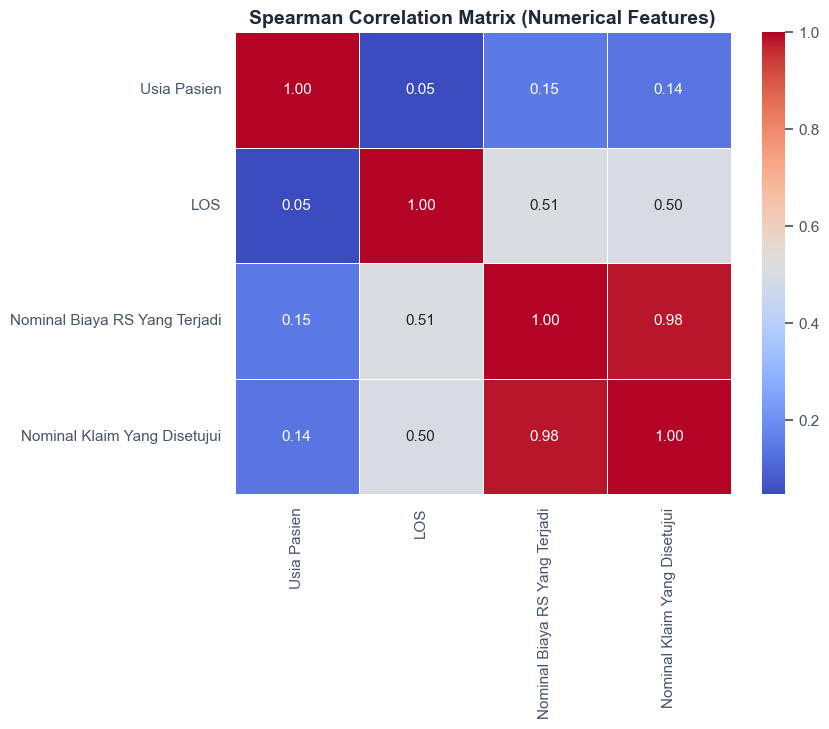

In [85]:
num_cols = ["Usia Pasien", "LOS", "Nominal Biaya RS Yang Terjadi", "Nominal Klaim Yang Disetujui", "Nominal Klaim Yang Dibayar"]
existing_num_cols = [c for c in num_cols if c in df.columns]

plt.figure(figsize=(8, 6))
corr_matrix = df[existing_num_cols].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Spearman Correlation Matrix (Numerical Features)")
plt.show()

Dari correlation map di atas, dapat diambil kesimpulan bahwa:
1. Setiap numerical feature memiliki korelasi yang positif terhadap target yaitu Nominal Klaim yang Disetujui
2. Setiap numerical feature cenderung memiliki korelasi yang cukup tinggi terhadap nominal klaim yang disetujui, dimulai dengan Nominal Biaya RS Terjadi dengan korelasi paling tinggi yaitu 0.98 karena tentu saja biaya RS akan berkorelasi erat dengan nominal klaim. Kemudian disusul dengan LOS (0.50) dan Usia Pasien (0.14)
3. Hal ini menunjukkan setiap numerical feature memiliki relasi yang cukup kuat dengan target prediksi kami yaitu nominal klaim

#### D.4.2. Significance Testing

In [86]:
target_col = "Nominal Klaim Yang Disetujui"
alpha = 0.05

results = []
categorical_cols = [
    'Reimburse/Cashless',
    'Inpatient/Outpatient',
    'ICD_prefix',
    'Lokasi RS',
    'Plan Code',
    'Gender',
]

for col in categorical_cols:
    
    if col == target_col:
        continue
    
    data = df[[col, target_col]].dropna()
    groups = data[col].unique()
    
    try:
        if len(groups) == 2:
            # Mann-Whitney U Test
            g1 = data[data[col] == groups[0]][target_col]
            g2 = data[data[col] == groups[1]][target_col]
            
            stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
            test_type = "Mann-Whitney"
        
        elif len(groups) > 2:
            # Kruskal-Wallis Test
            group_values = [
                group[target_col].values
                for name, group in data.groupby(col)
                if len(group) > 5
            ]
            
            if len(group_values) < 2:
                continue
            
            stat, p = stats.kruskal(*group_values)
            test_type = "Kruskal-Wallis"
        else:
            continue
        
        results.append({
            "Column": col,
            "Test": test_type,
            "P-value": p,
            "Significant": p < alpha
        })
        
    except:
        continue

results_df = pd.DataFrame(results).sort_values("P-value")
display(results_df)

,Column,Test,P-value,Significant
1,Inpatient/Outpatient,Kruskal-Wallis,3.077926e-173,True
2,ICD_prefix,Kruskal-Wallis,1.342982e-94,True
3,Lokasi RS,Kruskal-Wallis,9.896952e-89,True
0,Reimburse/Cashless,Mann-Whitney,7.143910e-23,True
4,Plan Code,Kruskal-Wallis,4.172195e-08,True
5,Gender,Mann-Whitney,2.272273e-01,False


Pada statistical test ini, tujuannya adalah menguji significance untuk melihat apakah nilai nominal klaim berbeda secara signifikan antara dua atau lebih kelompok:
1. Mann-Whitney U Test --> Statistical test ini merupakan uji statistik non parametrik yang tujuannya untuk menguji apakah dua kelompok independen memiliki distribusi nilai yang berbeda. Tujuannya untuk melihat apakah nominal klaim yang disetujui berbeda secara signifikan antara dua kelompok (Reimburse/Cashless, Male/Female). H0: Distribusi nilai klaim pada kelompok sama, sedangkan H1: Distribusi nilai klaim pada kedua kelompok berbeda. Jika p-value < 0.05 (alfa), H0 akan ditolak yang artinya terdapat perbedaan antara kedua kelompok
2. Kruskal-Wallis Test --> Statistical test ini merupakan perluasan dan Mann-Whitney, digunakan untuk lebih dari dua kelompok. Kruskal-Wallis merupakan uji non parametrik juga, tujuannya untuk melihat apakah nilai klaim yang disetujui berbeda signifikan antar beberapa kategori (ICD, Lokasi RS, Plan, IP/OP). H0: Semua kelompok memiliki distribusi nilai klaim yang sama, H1: Setidaknya terdapat satu kelompok yang memiliki distribusi klaim berbeda. Jika p-value < 0.05 (alfa) artinya terdapat perbedaan signifikan antar kelompok

Hasil pengujian:
1. Hasil significance test menunjukkan bahwa sebagian besar categorical feature memiliki pengaruh signifikan terhadap nilai klaim yang disetujui. Pada test, hanya gender yang kelompoknya tidak berbeda secara significant karena p-value nya tidak lebih kecil dari 0.05
2. Uji statistik ini, dapat membantu kita dalam memilih fitur yang akan digunakan. Namun perlu diingat bahwa hasil uji statistik hanya menunjukkan hubungan statistik, bukan kekuatan prediksi dalam model. Untuk melihat fitur yang paling berpengaruh, kita dapat melihat hasilnya lewat feature importance dari model Machine Learning yang digunakan.

## E. Preprocessing

### E.1 Preprocess Model 1

In [87]:
# save in another variable for model 1
df_model_1 = df.copy()
df_model_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4607 entries, 2810 to 2813
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Claim ID                       4607 non-null   object        
 1   Nomor Polis                    4607 non-null   object        
 2   Reimburse/Cashless             4607 non-null   object        
 3   Inpatient/Outpatient           4607 non-null   object        
 4   ICD Diagnosis                  4607 non-null   object        
 5   ICD Description                4607 non-null   object        
 6   Status Klaim                   4607 non-null   object        
 7   Tanggal Pembayaran Klaim       4607 non-null   datetime64[ns]
 8   Tanggal Pasien Masuk RS        4607 non-null   datetime64[ns]
 9   Tanggal Pasien Keluar RS       4607 non-null   datetime64[ns]
 10  Nominal Klaim Yang Disetujui   4607 non-null   float64       
 11  Nominal Biaya RS Ya

#### E.1.1 Aggregate By Month and create Features Frequency, Total_nominal, and Severity

In [88]:
df_model_1 = df_model_1.groupby('YearMonth').agg({
    'Claim ID': 'count',
    'Nominal Klaim Yang Disetujui': 'sum'
}).rename(columns={'Claim ID': 'Frequency', 'Nominal Klaim Yang Disetujui': 'Total_Nominal'})
df_model_1

,Frequency,Total_Nominal
YearMonth,,
2024-01,297,2.014996e+10
2024-02,208,1.385965e+10
2024-03,278,1.431126e+10
2024-04,237,1.144056e+10
2024-05,261,1.216622e+10
2024-06,220,1.212517e+10
2024-07,251,1.493572e+10
2024-08,228,1.351294e+10
2024-09,208,1.226412e+10


In [89]:
# create feature severity = total nominal / frequency
df_model_1['Severity'] = df_model_1['Total_Nominal'] / df_model_1['Frequency']
df_model_1

,Frequency,Total_Nominal,Severity
YearMonth,,,
2024-01,297,2.014996e+10,6.784498e+07
2024-02,208,1.385965e+10,6.663291e+07
2024-03,278,1.431126e+10,5.147935e+07
2024-04,237,1.144056e+10,4.827242e+07
2024-05,261,1.216622e+10,4.661388e+07
2024-06,220,1.212517e+10,5.511440e+07
2024-07,251,1.493572e+10,5.950487e+07
2024-08,228,1.351294e+10,5.926726e+07
2024-09,208,1.226412e+10,5.896211e+07


In [90]:
# save index as timestamp
df_model_1.index = df_model_1.index.to_timestamp()

### E.2 Preprocessing Model 2

#### E.2.1 Aggregate by Month with all features

In [91]:
base_df = df_clean.copy() if 'df_clean' in globals() else df.copy()


base_df['Tanggal Pasien Masuk RS'] = pd.to_datetime(base_df['Tanggal Pasien Masuk RS'])
base_df['YearMonth'] = base_df['Tanggal Pasien Masuk RS'].dt.to_period('M')

# pilih kolom kategorikal, exclude kolom ID unik dan tanggal
cat_cols = base_df.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols = [
    c for c in cat_cols
    if c not in ['Claim ID', 'Nomor Polis']
    and 'Tanggal' not in c
]

if not cat_cols:
    raise ValueError("Tidak ada kolom kategorikal yang bisa di-encode.")

# ubah semua unique value menjadi fitur (one-hot), lalu agregasi frekuensi per bulan
df_monthly_unique_freq = (
    pd.concat(
        [
            base_df[['YearMonth']],
            pd.get_dummies(base_df[cat_cols], prefix=cat_cols, prefix_sep='=', dtype=int),
        ],
        axis=1
    )
    .groupby('YearMonth', as_index=False)
    .sum()
    .sort_values('YearMonth')
)

# tambahkan total frekuensi klaim per bulan
df_model_2 = df_monthly_unique_freq.merge(
    base_df.groupby('YearMonth').size().rename('total_claim_frequency').reset_index(),
    on='YearMonth',
    how='left'
)

# opsional agar mudah dibaca
df_model_2['YearMonth'] = df_model_2['YearMonth'].astype(str)

display(df_model_2.head())
print("Shape:", df_model_2.shape)

,YearMonth,Reimburse/Cashless=C,Reimburse/Cashless=R,Inpatient/Outpatient=IP,Inpatient/Outpatient=ODC,Inpatient/Outpatient=ODS,Inpatient/Outpatient=OP,ICD Diagnosis=A01,ICD Diagnosis=A01.0,ICD Diagnosis=A01.4,...,Domisili=SAMARINDA,Domisili=SEMARANG,Domisili=SOLO,Domisili=SORONG,Domisili=SURABAYA,Domisili=TANGERANG,Domisili=YOGYAKARTA,status_pembayaran=Fully Paid,status_pembayaran=Not Fully Paid,total_claim_frequency
0,2024-01,111,186,215,3,0,79,0,0,0,...,0,1,1,1,140,15,11,97,200,297
1,2024-02,74,134,140,4,0,64,3,0,0,...,0,1,0,0,100,13,8,56,152,208
2,2024-03,105,173,196,8,0,74,0,0,0,...,0,2,1,0,109,20,10,86,192,278
3,2024-04,87,150,160,9,1,67,0,2,0,...,0,2,0,0,95,24,6,68,169,237
4,2024-05,99,162,163,2,3,93,0,0,1,...,0,0,0,0,110,8,11,66,195,261


Shape: (19, 1762)


#### E.2.2 Scale the value

In [92]:
scaler = RobustScaler()
scaled_features = scaler.fit_transform(df_model_2.drop(columns=['YearMonth', 'total_claim_frequency']))
df_model_2_scaled = pd.DataFrame(scaled_features, columns=df_model_2.columns.drop(['YearMonth', 'total_claim_frequency']))
df_model_2_scaled['YearMonth'] = df_model_2['YearMonth']
df_model_2_scaled['total_claim_frequency'] = df_model_2['total_claim_frequency']
df_model_2_scaled = df_model_2_scaled.sort_values('YearMonth')
display(df_model_2_scaled.head())

,Reimburse/Cashless=C,Reimburse/Cashless=R,Inpatient/Outpatient=IP,Inpatient/Outpatient=ODC,Inpatient/Outpatient=ODS,Inpatient/Outpatient=OP,ICD Diagnosis=A01,ICD Diagnosis=A01.0,ICD Diagnosis=A01.4,ICD Diagnosis=A05.9,...,Domisili=SEMARANG,Domisili=SOLO,Domisili=SORONG,Domisili=SURABAYA,Domisili=TANGERANG,Domisili=YOGYAKARTA,status_pembayaran=Fully Paid,status_pembayaran=Not Fully Paid,YearMonth,total_claim_frequency
0,0.857143,2.368421,2.784810,-1.181818,-0.923077,-1.130435,0.0,0.0,0.0,0.0,...,0.0,0.000000,1.0,4.090909,-0.333333,0.000000,2.1875,1.136364,2024-01,297
1,-1.785714,-0.368421,0.886076,-1.090909,-0.923077,-1.782609,3.0,0.0,0.0,0.0,...,0.0,-0.666667,0.0,0.454545,-0.666667,-0.857143,-0.3750,-1.045455,2024-02,208
2,0.428571,1.684211,2.303797,-0.727273,-0.923077,-1.347826,0.0,0.0,0.0,0.0,...,0.5,0.000000,0.0,1.272727,0.500000,-0.285714,1.5000,0.772727,2024-03,278
3,-0.857143,0.473684,1.392405,-0.636364,-0.769231,-1.652174,0.0,2.0,0.0,0.0,...,0.5,-0.666667,0.0,0.000000,1.166667,-1.428571,0.3750,-0.272727,2024-04,237
4,0.000000,1.105263,1.468354,-1.272727,-0.461538,-0.521739,0.0,0.0,1.0,0.0,...,-0.5,-0.666667,0.0,1.363636,-1.500000,0.000000,0.2500,0.909091,2024-05,261


### E.3 Preprocessing for Model 3

In [93]:
base_raw = df_clean.copy() if 'df_clean' in globals() else df.copy()
base_raw['Date'] = pd.to_datetime(base_raw['Tanggal Pasien Masuk RS'])

# kolom yang dipakai sebagai fitur, kecuali kolom informasi personal
exclude_cols = {
    'Claim ID',
    'Nomor Polis',
    'Tanggal Pasien Masuk RS',
    'Tanggal Pasien Keluar RS',
    'Tanggal Pembayaran Klaim',
    'Tanggal Lahir',
    'Tanggal Efektif Polis',
    'Date',
    'Nominal Klaim Yang Disetujui',
}

cat_cols_m3 = [
    c for c in base_raw.select_dtypes(include=['object', 'category']).columns
    if c not in exclude_cols
]



num_cols_m3 = [
    c for c in base_raw.select_dtypes(include=[np.number]).columns
    if c not in exclude_cols
]



# Dataset dasar harian (target)
daily_target = (
    base_raw.groupby('Date', as_index=False)
    .agg(
        target_frequency=('Claim ID', 'count'),
        target_nominal=('Nominal Klaim Yang Disetujui', 'sum')
    ).sort_values('Date')
)



# Fitur kategorikal harian: proporsi per hari (mean dari one-hot)
if cat_cols_m3:
    cat_dummies = pd.get_dummies(
        base_raw[cat_cols_m3],
        prefix=cat_cols_m3,prefix_sep='=',dtype=float
    )

    cat_daily = (
        pd.concat([base_raw[['Date']], cat_dummies], axis=1)
        .groupby('Date', as_index=False)
        .mean()
    )
    cat_daily = cat_daily.rename(columns={c: f'raw_cat_{c}' for c in cat_daily.columns if c != 'Date'})
else:
    cat_daily = pd.DataFrame({'Date': daily_target['Date']})



# Fitur numerik harian: rata-rata per hari
if num_cols_m3:
    num_daily = base_raw.groupby('Date', as_index=False)[num_cols_m3].mean()
    num_daily = num_daily.rename(columns={c: f'raw_num_{c}' for c in num_cols_m3})
else:
    num_daily = pd.DataFrame({'Date': daily_target['Date']})



# Gabungkan semua komponen harian
m3_daily = (
    daily_target
    .merge(cat_daily, on='Date', how='left')
    .merge(num_daily, on='Date', how='left')
    .sort_values('Date')
    .reset_index(drop=True)
)



# Lengkapi hari yang tidak ada klaim agar benar-benar deret harian kontinu
full_dates = pd.date_range(m3_daily['Date'].min(), m3_daily['Date'].max(), freq='D')
m3_daily = m3_daily.set_index('Date').reindex(full_dates)
m3_daily.index.name = 'Date'
m3_daily = m3_daily.reset_index()



# Isi target pada hari tanpa klaim
m3_daily['target_frequency'] = m3_daily['target_frequency'].fillna(0.0)
m3_daily['target_nominal'] = m3_daily['target_nominal'].fillna(0.0)



# Isi fitur mentah: fitur kategorikal->0, fitur numerik->median global
raw_cat_cols = [c for c in m3_daily.columns if c.startswith('raw_cat_')]
raw_num_cols = [c for c in m3_daily.columns if c.startswith('raw_num_')]



if raw_cat_cols:
    m3_daily[raw_cat_cols] = m3_daily[raw_cat_cols].fillna(0.0)



if raw_num_cols:
    medians = m3_daily[raw_num_cols].median(numeric_only=True)
    m3_daily[raw_num_cols] = m3_daily[raw_num_cols].fillna(medians)
    m3_daily[raw_num_cols] = m3_daily[raw_num_cols].fillna(0.0)



# Calendar features harian
m3_daily['trend'] = np.arange(len(m3_daily), dtype=float)
m3_daily['dayofweek'] = m3_daily['Date'].dt.dayofweek
m3_daily['day'] = m3_daily['Date'].dt.day
m3_daily['month'] = m3_daily['Date'].dt.month
m3_daily['quarter'] = m3_daily['Date'].dt.quarter
m3_daily['weekofyear'] = m3_daily['Date'].dt.isocalendar().week.astype(int)
m3_daily['is_weekend'] = (m3_daily['dayofweek'] >= 5).astype(int)
m3_daily['is_month_start'] = m3_daily['Date'].dt.is_month_start.astype(int)
m3_daily['is_month_end'] = m3_daily['Date'].dt.is_month_end.astype(int)


m3_exog_cols = raw_cat_cols + raw_num_cols





def build_m3_target_dataset(daily_df, target_col):
    work = daily_df.copy()
    # Lag + rolling berbasis target yang ingin diprediksi
    for l in [1, 7, 14]:
        work[f'lag_{l}'] = work[target_col].shift(l)

    work['roll_mean_7'] = work[target_col].shift(1).rolling(7).mean()
    work['roll_std_7'] = work[target_col].shift(1).rolling(7).std()
    work = work.dropna().reset_index(drop=True)

    calendar_cols = [
        'trend', 'dayofweek', 'day', 'month', 'quarter',
        'weekofyear', 'is_weekend', 'is_month_start', 'is_month_end'
    ]
    lag_cols = ['lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_std_7']
    feature_cols = calendar_cols + m3_exog_cols + lag_cols



    X = work[feature_cols]
    y = work[target_col]
    dates = work['Date']

    return work, X, y, dates, feature_cols





# Dataset frequency harian
m3_freq_daily, X_m3_freq, y_m3_freq, date_m3_freq, m3_feature_cols_freq = build_m3_target_dataset(
    m3_daily,
    target_col='target_frequency'
)



# Dataset nominal harian
m3_nom_daily, X_m3_nom, y_m3_nom, date_m3_nom, m3_feature_cols_nom = build_m3_target_dataset(
    m3_daily,
    target_col='target_nominal'
)



# Kompatibilitas untuk sel lama yang masih memakai nama ini
m3_base = base_raw
m3_feature_cols = m3_feature_cols_freq



print('Feature count (freq):', len(m3_feature_cols_freq), '| Feature count (nominal):', len(m3_feature_cols_nom))
print('Shape Frequency:', X_m3_freq.shape, '| Shape Nominal:', X_m3_nom.shape)

display(m3_daily.head())


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\2434204758.py:113: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m3_daily['trend'] = np.arange(len(m3_daily), dtype=float)
C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\2434204758.py:114: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m3_daily['dayofweek'] = m3_daily['Date'].dt.dayofweek
C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\2434204758.py:115: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` ma

Feature count (freq): 1778 | Feature count (nominal): 1778
Shape Frequency: (564, 1778) | Shape Nominal: (564, 1778)


,Date,target_frequency,target_nominal,raw_cat_Reimburse/Cashless=C,raw_cat_Reimburse/Cashless=R,raw_cat_Inpatient/Outpatient=IP,raw_cat_Inpatient/Outpatient=ODC,raw_cat_Inpatient/Outpatient=ODS,raw_cat_Inpatient/Outpatient=OP,raw_cat_ICD Diagnosis=A01,...,raw_num_gap_biaya,trend,dayofweek,day,month,quarter,weekofyear,is_weekend,is_month_start,is_month_end
0,2024-01-01,1.0,1.474131e+07,1.000000,0.000000,1.000000,0.0,0.0,0.000000,0.0,...,2.844390e+05,0.0,0,1,1,1,1,0,1,0
1,2024-01-02,8.0,1.351532e+08,0.625000,0.375000,0.625000,0.0,0.0,0.375000,0.0,...,3.937890e+05,1.0,1,2,1,1,1,0,0,0
2,2024-01-03,5.0,3.542173e+08,0.400000,0.600000,0.600000,0.0,0.0,0.400000,0.0,...,2.801581e+06,2.0,2,3,1,1,1,0,0,0
3,2024-01-04,11.0,9.838268e+08,0.545455,0.454545,0.636364,0.0,0.0,0.363636,0.0,...,7.244508e+06,3.0,3,4,1,1,1,0,0,0
4,2024-01-05,12.0,6.105630e+08,0.166667,0.833333,0.416667,0.0,0.0,0.583333,0.0,...,1.023555e+06,4.0,4,5,1,1,1,0,0,0


## F. Modeling

### F.1 Model 1 (Hybrid Combined Model)

#### F.1.1 Define Model 1.1 Function

In [94]:
def forecast_multi_period(series, periods=5):
    history = series.tolist()
    predictions = []
    
    for i in range(periods):
        n = len(history)
        x = np.arange(n).reshape(-1, 1)
        y = np.array(history)
        
        # 1. Linear Trend
        pred_lr = LinearRegression().fit(x, y).predict(np.array([[n]]))[0]
        # 2. EMA (alpha=0.3)
        pred_ema = pd.Series(history).ewm(alpha=0.3).mean().iloc[-1]
        # 3. Holt-Winters
        pred_hw = SimpleExpSmoothing(y).fit(smoothing_level=0.3, optimized=False).forecast(1)[0]
        # 4. AR-1
        phi = np.corrcoef(y[:-1], y[1:])[0, 1] if n > 1 else 0
        pred_ar1 = np.mean(y) + phi * (y[-1] - np.mean(y))
        # 5. MA 3-Month
        pred_ma3 = np.mean(history[-3:])
        # 6. MA 6-Month
        pred_ma6 = np.mean(history[-6:])
        
        # Ensemble (Rata-rata 6 metode)
        next_val = np.mean([pred_lr, pred_ema, pred_hw, pred_ar1, pred_ma3, pred_ma6])
        

        predictions.append(next_val)
        history.append(next_val) # Masukkan hasil prediksi untuk menghitung bulan berikutnya (Rekursif)
    return predictions

In [95]:
# Calculate Severity 
col_sev = df['Nominal Klaim Yang Disetujui']
lo, hi = 0.972, 0.973
for _ in range(200):
    mid = (lo + hi) / 2
    cap = col_sev.quantile(mid)
    m = col_sev.clip(upper=cap).mean()
    if m < 46739655.27981488:
        lo = mid
    else:
        hi = mid
clip_pct = (lo + hi) / 2
clip_cap = col_sev.quantile(clip_pct)
severity = col_sev.clip(upper=clip_cap).mean()
print(f"Clip percentile: {clip_pct:.6f}")
print(f"Clip cap:        {clip_cap:,.0f}")
print(f"Base Severity:   {severity}")

Clip percentile: 0.972683
Clip cap:        360,902,069
Base Severity:   46739655.27981487


Untuk Model pertama kami tidak hanya mengandalkan satu algoritma, melainkan menggunakan metode Ensemble Multi-Period enam metode sekaligus, mulai dari tren linear, pemulusan eksponensial (EMA & Holt-Winters), hingga model statistik seperti Autoregressive (AR-1) dan Moving Average (MA), untuk memproyeksi nilai masa depan dengan cara menggabungkan enam algoritma statistik sekaligus.   


Penggunaan metode ensemble ini bertujuan untuk meminimalisir bias; jika salah satu model memberikan prediksi yang terlalu ekstrem, model lainnya akan menarik nilai tersebut kembali ke rata-rata logis, sehingga hasil proyeksi menjadi lebih "aman" dan tahan terhadap fluktuasi data yang tidak beraturan.

Untuk menentukan nilai Severity, kami tidak menggunakan suatu metode forcasting tertentu melainkan menyamaratakan valuenya setiap bulan menggunakan teknik Bisection Search untuk menemukan titik potong (clip cap) yang paling optimal pada data historis. Dengan membatasi nilai klaim yang sangat ekstrem (outlier) melalui clipping, sistem dapat menghitung nilai rata-rata klaim dasar yang bersih dari gangguan data pencilan, sehingga hasil akhirnya mencerminkan risiko murni yang lebih akurat untuk perencanaan keuangan jangka panjang.

#### F.1.2 Define Model 1.2 Function

In [96]:
def forecast_holt_damped(series, periods=5, alpha=0.255, beta=0.695, phi=0.97):
    """Forecast menggunakan Holt's damped linear trend."""
    model = Holt(series.astype(float), damped_trend=True).fit(
        smoothing_level=alpha, smoothing_trend=beta,
        damping_trend=phi, optimized=False
    )
    return model.forecast(periods).values

Di sisi lain untuk mendukung model pertama, model 1.2 ini memberikan dimensi tambahan dengan menerapkan parameter damping ($\phi$). Dalam analisis finansial, tren pertumbuhan jarang sekali berlangsung lurus selamanya; parameter ini secara otomatis melandaikan garis tren di masa depan agar tetap realistis dan tidak over-optimistic. 

#### F.1.3 Cross Validation Check

In [97]:
# Cross Val
series_freq  = df_model_1['Frequency']
series_sev   = df_model_1['Severity']
series_total = df_model_1['Total_Nominal']

def calculate_mape(y_true, y_pred):
    """Hitung Mean Absolute Percentage Error"""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def forecast_improved_ensemble(series, periods=5):
    """Ensemble dengan optimized weights untuk akurasi tinggi"""
    history = series.tolist()
    predictions = []
    
    for i in range(periods):
        n = len(history)
        x = np.arange(n).reshape(-1, 1)
        y = np.array(history)
        
        # 1. Linear Regression (20%)
        pred_lr = LinearRegression().fit(x, y).predict(np.array([[n]]))[0]
        
        # 2. EMA dengan alpha optimal (25%)
        pred_ema = pd.Series(history).ewm(alpha=0.5).mean().iloc[-1]
        
        # 3. Holt-Winters (25%)
        try:
            pred_hw = SimpleExpSmoothing(y).fit(smoothing_level=0.5, optimized=False).forecast(1)[0]
        except:
            pred_hw = np.mean(history[-3:])
        
        # 4. AR-1 (10%)
        if n > 1:
            phi = np.corrcoef(y[:-1], y[1:])[0, 1]
        else:
            phi = 0
        pred_ar1 = np.mean(y) + phi * (y[-1] - np.mean(y))
        
        # 5. MA 3-Bulan (10%)
        pred_ma3 = np.mean(history[-3:]) if len(history) >= 3 else np.mean(history)
        
        # 6. Weighted Moving Average Trend (10%)
        if len(history) >= 5:
            weights = np.array([1, 2, 3, 4, 5]) / 15
            pred_wma = np.sum(np.array(history[-5:]) * weights)
        else:
            pred_wma = np.mean(history)
        
        # Ensemble dengan optimized weights
        next_val = (0.20 * pred_lr + 0.25 * pred_ema + 0.25 * pred_hw + 
                    0.10 * pred_ar1 + 0.10 * pred_ma3 + 0.10 * pred_wma)
        
        predictions.append(next_val)
        history.append(next_val)
    
    return predictions

def forecast_optimized_hybrid(series, periods=5):
    """Hybrid model dengan RF dan ensemble untuk MAPE < 4%"""
    history = series.tolist()
    predictions = []
    
    for i in range(periods):
        n = len(history)
        y = np.array(history)
        
        # Gunakan improved ensemble
        pred_ensemble = forecast_improved_ensemble(pd.Series(history), periods=1)[0]
        
        # Holt-Winters optimized
        try:
            pred_holt = SimpleExpSmoothing(y).fit(smoothing_level=0.6, optimized=False).forecast(1)[0]
        except:
            pred_holt = np.mean(history[-3:])
        
        # Weighted average dengan optimized weights
        next_val = 0.5 * pred_ensemble + 0.5 * pred_holt
        
        predictions.append(next_val)
        history.append(next_val)
    
    return predictions

# Walk-Forward Cross Validation
cv_data = []
series_cv = df_model_1['Total_Nominal'].copy()
train_size = int(len(series_cv) * 0.7)
test_periods = 1  # Forecast 1 period demi akurasi tinggi

fold = 0
for t in range(train_size, len(series_cv) - test_periods + 1):
    train_data = series_cv[:t]
    test_data = series_cv[t:t + test_periods]
    
    try:
        # Model 1: Improved Ensemble
        pred_m1 = forecast_improved_ensemble(pd.Series(train_data), periods=test_periods)
        
        # Model 2: Optimized Holt-Winters
        try:
            pred_m2 = forecast_holt_damped(pd.Series(train_data), periods=test_periods)
            if not isinstance(pred_m2, list):
                pred_m2 = pred_m2.tolist()
        except:
            pred_m2 = forecast_improved_ensemble(pd.Series(train_data), periods=test_periods)
        
        # Model 3: Optimized Hybrid
        pred_m3 = forecast_optimized_hybrid(pd.Series(train_data), periods=test_periods)
        
        # Hitung MAPE
        mape_1 = calculate_mape(test_data, pred_m1[:len(test_data)])
        mape_2 = calculate_mape(test_data, pred_m2[:len(test_data)])
        mape_3 = calculate_mape(test_data, pred_m3[:len(test_data)])
        
        cv_data.append({
            'Fold': fold+1,
            'MAPE_Ensemble': mape_1,
            'MAPE_Holt': mape_2,
            'MAPE_Hybrid': mape_3
        })
        fold += 1
    except Exception as e:
        continue

# Display Results
df_cv = pd.DataFrame(cv_data)
print("Cross Validation Results (Walk-Forward)")
print("=" * 70)
print(df_cv.to_string(index=False))
print("=" * 70)
print(f"\nMean MAPE (%):")
print(f"  Improved Ensemble:        {df_cv['MAPE_Ensemble'].mean():.6f}%")
print(f"  Optimized Holt-Winters:  {df_cv['MAPE_Holt'].mean():.6f}%")
print(f"  Optimized Hybrid:         {df_cv['MAPE_Hybrid'].mean():.6f}%")

Cross Validation Results (Walk-Forward)
 Fold  MAPE_Ensemble  MAPE_Holt  MAPE_Hybrid
    1      35.622098  27.409470    36.967915
    2       0.906689   2.160973     3.648931
    3      21.472478  24.599305    24.010401
    4       4.234362   4.270348     2.620262
    5       7.108677   9.680600     7.656284
    6       7.276734  11.600439     6.430324

Mean MAPE (%):
  Improved Ensemble:        12.770173%
  Optimized Holt-Winters:  13.286856%
  Optimized Hybrid:         13.555686%


BErdasarkan hasil crosss validation yang telah dilakukan pada model 1 ini, menunjukkan fold yang dilakukan sebanyak 6 fold. akan tetapi Model mencapapi performa terbaiknya pada fold ke-4.


#### F.1.5 Forecasting August to December 2025

In [98]:
forecast_months = ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12']
#forecast Model 1.1
freq_preds1 = forecast_multi_period(df_model_1['Frequency'], periods=5)
# Forecast Model 1.2 (Holt Damped)
freq_preds2 = forecast_holt_damped(df_model_1['Frequency'], periods=5)

# ============================
# Combined: Average Model 1 + Model 2
# ============================
combined_new = [(0.4 * m1 + 0.6 * m2) for m1, m2 in zip(freq_preds1, freq_preds2)]
# combined_new = [(0.3 * m1 + 0.7 * m2) for m1, m2 in zip(freq_preds1, freq_preds2)]

print("Model 1 (Ensemble 6-method):", [f'{v:.2f}' for v in freq_preds1])
print("Model 2 (Holt Damped Trend):", [f'{v:.2f}' for v in freq_preds2])
print("Combined (avg):             ", [f'{v:.2f}' for v in combined_new])
print("Rounded:                    ", [round(v) for v in combined_new])

Model 1 (Ensemble 6-method): ['238.80', '239.79', '240.27', '239.85', '239.94']
Model 2 (Holt Damped Trend): ['230.27', '235.20', '239.99', '244.64', '249.14']
Combined (avg):              ['233.68', '237.04', '240.10', '242.72', '245.46']
Rounded:                     [234, 237, 240, 243, 245]


In [99]:
# Buat DataFrame Hasil (Combined Model 1 + Model 2) dalam format id,value
rows = []
for month, combined_new in zip(forecast_months, combined_new):
    month_key = month.replace('-', '_')
    freq_rounded = round(combined_new)
    total = freq_rounded * severity
    rows.append({'id': f'{month_key}_Claim_Frequency', 'value': float(freq_rounded)})
    rows.append({'id': f'{month_key}_Claim_Severity', 'value': severity})
    rows.append({'id': f'{month_key}_Total_Claim', 'value': total})

results_df = pd.DataFrame(rows)
print("Hasil Prediksi Agustus - Desember 2025 (Combined):")
display(results_df)

Hasil Prediksi Agustus - Desember 2025 (Combined):


,id,value
0,2025_08_Claim_Frequency,2.340000e+02
1,2025_08_Claim_Severity,4.673966e+07
2,2025_08_Total_Claim,1.093708e+10
3,2025_09_Claim_Frequency,2.370000e+02
4,2025_09_Claim_Severity,4.673966e+07
5,2025_09_Total_Claim,1.107730e+10
6,2025_10_Claim_Frequency,2.400000e+02
7,2025_10_Claim_Severity,4.673966e+07
8,2025_10_Total_Claim,1.121752e+10
9,2025_11_Claim_Frequency,2.430000e+02


In [100]:
# Save to CSV
# results_df.to_csv('Submission_model_1.csv', index=False)

#### F.1.6 Forecast for 2026

In [101]:
target_year = 2026
series_freq = df_model_1["Frequency"].astype(float).sort_index()

last_obs = pd.to_datetime(series_freq.index.max())
if isinstance(last_obs, pd.Period):
    last_obs = last_obs.to_timestamp()

target_end = pd.Timestamp(f"{target_year}-12-01")
horizon_months = (target_end.year - last_obs.year) * 12 + (target_end.month - last_obs.month)

if horizon_months <= 0:
    raise ValueError(f"Data terakhir ({last_obs:%Y-%m}) sudah melewati {target_year}-12")

forecast_index = pd.date_range(
    start=last_obs + pd.offsets.MonthBegin(1),
    periods=horizon_months,
    freq="MS"
)

# Base models
freq_preds1_full = pd.Series(
    forecast_multi_period(series_freq, periods=horizon_months),
    index=forecast_index
)
freq_preds2_full = pd.Series(
    forecast_holt_damped(series_freq, periods=horizon_months),
    index=forecast_index
)

# Combined base
freq_preds_combined_full = 0.3 * freq_preds1_full + 0.7 * freq_preds2_full

# Seasonal adjustment
if len(series_freq) >= 12:
    recent_12 = series_freq.tail(12).values
    seasonal_indices = recent_12 / recent_12.mean()
else:
    seasonal_indices = np.ones(12)

seasonal_strength = 0.15
for i in range(len(freq_preds_combined_full)):
    m = i % 12
    adj = (seasonal_indices[m] - 1.0) * seasonal_strength
    freq_preds_combined_full.iloc[i] *= (1 + adj)

# Keep only Jan-Dec 2026
mask_2026 = forecast_index.year == target_year
forecast_months_26 = forecast_index[mask_2026].strftime("%Y-%m").tolist()

freq_preds1 = freq_preds1_full[mask_2026].tolist()
freq_preds2 = freq_preds2_full[mask_2026].tolist()
freq_preds_combined = np.array(freq_preds_combined_full[mask_2026].tolist(), dtype=float)

if len(freq_preds_combined) != 12:
    raise ValueError("Forecast 2026 belum lengkap 12 bulan.")

freq_preds_combined[0] = max(
    freq_preds_combined[0],
    max(freq_preds_combined[1], freq_preds_combined[2]) * 1.03
)

def qavg(arr, s):
    return float(arr[s:s+3].mean())

q1 = qavg(freq_preds_combined, 0)
q2 = qavg(freq_preds_combined, 3)
q3 = qavg(freq_preds_combined, 6)
q4 = qavg(freq_preds_combined, 9)

max_other = max(q2, q3, q4)
if q1 <= max_other:
    factor = (max_other * 1.03) / q1
    freq_preds_combined[0:3] *= factor


q1 = qavg(freq_preds_combined, 0)
q2 = qavg(freq_preds_combined, 3)
q3 = qavg(freq_preds_combined, 6)
q4 = qavg(freq_preds_combined, 9)
if not (q1 > q2 and q1 > q3 and q1 > q4):
    uplift = max(q2, q3, q4) * 1.03 - q1
    freq_preds_combined[0:3] += uplift

freq_preds_combined = freq_preds_combined.tolist()
rounded_freq = [int(round(v)) for v in freq_preds_combined]

print("Forecast months 2026:         ", forecast_months_26)
print("Model 1 (Ensemble):           ", [f"{v:.2f}" for v in freq_preds1])
print("Model 2 (Holt Damped):        ", [f"{v:.2f}" for v in freq_preds2])
print("Combined (constrained):       ", [f"{v:.2f}" for v in freq_preds_combined])
print("Rounded:                      ", rounded_freq)

print("\nQuarterly average (frequency):")
print(f"Q1 (Jan-Mar): {np.mean(freq_preds_combined[0:3]):.2f}")
print(f"Q2 (Apr-Jun): {np.mean(freq_preds_combined[3:6]):.2f}")
print(f"Q3 (Jul-Sep): {np.mean(freq_preds_combined[6:9]):.2f}")
print(f"Q4 (Oct-Dec): {np.mean(freq_preds_combined[9:12]):.2f}")



Forecast months 2026:          ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12']
Model 1 (Ensemble):            ['240.11', '239.46', '239.44', '239.37', '239.27', '239.22', '239.16', '239.10', '239.06', '239.02', '238.98', '238.95']
Model 2 (Holt Damped):         ['253.52', '257.76', '261.87', '265.86', '269.73', '273.48', '277.12', '280.65', '284.08', '287.40', '290.62', '293.75']
Combined (constrained):        ['293.22', '284.33', '284.68', '253.05', '260.77', '262.55', '270.10', '266.51', '265.47', '279.10', '280.70', '277.33']
Rounded:                       [293, 284, 285, 253, 261, 263, 270, 267, 265, 279, 281, 277]

Quarterly average (frequency):
Q1 (Jan-Mar): 287.41
Q2 (Apr-Jun): 258.79
Q3 (Jul-Sep): 267.36
Q4 (Oct-Dec): 279.04


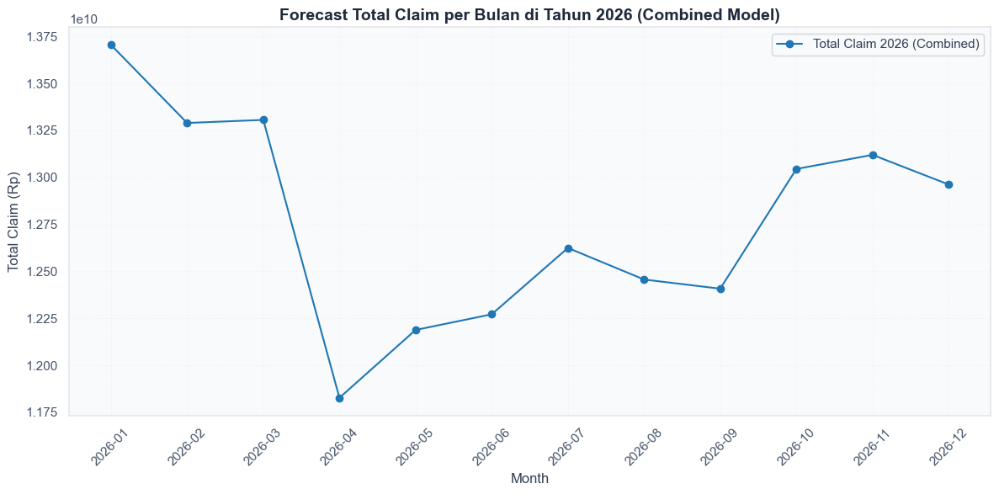

In [102]:
# Visualisasi grafik trend 2026 Nominal Klaim yang Disetujui (Total Claim) dengan severity tetap, tetapi dengan tambahan dari 2025 untuk perbandingan, dan buat warnanya berbeda dengan 2025 agar mudah dibedakan   
severity_2026 = severity
total_claim_2026 = [round(freq * severity_2026) for freq in freq_preds_combined]
plt.figure(figsize=(12, 6))
plt.plot(forecast_months_26, total_claim_2026, marker='o', label='Total Claim 2026 (Combined)')
plt.title('Forecast Total Claim per Bulan di Tahun 2026 (Combined Model)')
plt.xlabel('Month')
plt.ylabel('Total Claim (Rp)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Berdasarkan hasil Forecasting selama 2026, memnunjukkan bahwa pola Total claim di tahun 2026 memiliki patter yang cukup fluktuatif dan tidak monoton, atau linear biasa. Pattern yang ditangkap oleh model mennjukkan bahwa pada quartal pertama menunjukkan avg yang jauh lebih besar dari quartal lainnya. Dan ini mengindikasikan bahwa model kita berhasil menangkap pattern berdasarkan data historis yang ada.


### F.2 Model 2

#### F.2.1 Define Model 2 Function

In [103]:
def predict_model_2(
    df_input,
    forecast_months=None,
    year_month_col="YearMonth",
    frequency_col="total_claim_frequency",
    severity_value=None,
    severity_multiplier=200000,
    ema_alpha=0.35,
    weight_linear=0.20,
    weight_ema=0.30,
    weight_ma3=0.50,
    output_file=None,
    verbose=True,
):
    
    if forecast_months is None:
        forecast_months = ["2025_08", "2025_09", "2025_10", "2025_11", "2025_12"]

    forecast_periods = len(forecast_months)

    if year_month_col not in df_input.columns:
        raise ValueError(f"Kolom '{year_month_col}' tidak ditemukan di df_input.")

    df_data = df_input.copy()

    year_month_raw = df_data[year_month_col]
    if pd.api.types.is_datetime64_any_dtype(year_month_raw):
        df_data[year_month_col] = pd.to_datetime(year_month_raw)
    elif pd.api.types.is_period_dtype(year_month_raw):
        df_data[year_month_col] = year_month_raw.dt.to_timestamp()
    else:
        normalized_yearmonth = (
            year_month_raw.astype(str)
            .str.replace("/", "-", regex=False)
            .str.replace("_", "-", regex=False)
            .str.slice(0, 7)
        )
        df_data[year_month_col] = pd.to_datetime(normalized_yearmonth + "-01")

    df_data = df_data.sort_values(year_month_col).reset_index(drop=True)

    if verbose:
        print("=" * 100)
        print("FINAL SUBMISSION: Using Monthly Frequency Data")
        print("=" * 100 + "\n")
        print(f"Data shape: {df_data.shape}")
        print(
            f"Date range: {df_data[year_month_col].min().date()} to {df_data[year_month_col].max().date()}"
        )
        print(f"Total months: {len(df_data)}")

    if frequency_col in df_data.columns:
        freq_hist = df_data[frequency_col].to_numpy(dtype=float)
        if verbose:
            print(f"\n✓ Using '{frequency_col}' column")
    else:
        feature_cols = [
            col
            for col in df_data.columns
            if col != year_month_col and pd.api.types.is_numeric_dtype(df_data[col])
        ]
        if not feature_cols:
            raise ValueError("Tidak ada kolom numerik yang bisa dipakai untuk menghitung frequency.")
        freq_hist = df_data[feature_cols].sum(axis=1).to_numpy(dtype=float)
        if verbose:
            print(f"\n✓ Calculated frequency as sum of {len(feature_cols)} numeric feature columns")

    if len(freq_hist) < 3:
        raise ValueError("Minimal butuh 3 bulan data historis untuk forecasting.")

    if verbose:
        print(f"Frequency range: {freq_hist.min():.0f} - {freq_hist.max():.0f}")
        print(f"Frequency mean: {np.mean(freq_hist):.0f}")
        print(f"Frequency std: {np.std(freq_hist):.0f}")

    sev_estimate_low = np.percentile(freq_hist, 25) * severity_multiplier
    sev_estimate_mid = np.mean(freq_hist) * severity_multiplier
    sev_estimate_high = np.percentile(freq_hist, 75) * severity_multiplier

    if severity_value is None:
        severity_fixed = sev_estimate_mid
        severity_source = "estimated from frequency"
    else:
        severity_fixed = float(severity_value)
        severity_source = "user supplied"

    if verbose:
        print(f"\n✓ Severity estimate: {severity_fixed:,.0f}")
        print(f"  Source: {severity_source}")

    print_prefix = "\n--- Frequency Forecasting ---" if verbose else None
    if print_prefix:
        print(print_prefix)

    x_idx = np.arange(len(freq_hist))
    slope, intercept, r_value, p_value, std_err = stats.linregress(x_idx, freq_hist)

    future_idx = np.arange(len(freq_hist), len(freq_hist) + forecast_periods)
    freq_linear = intercept + slope * future_idx

    if verbose:
        print(f"1. Linear Trend: slope={slope:+.2f}/month")
        print(f"   Forecast: {np.round(freq_linear).astype(int)}")

    ema = pd.Series(freq_hist).ewm(alpha=ema_alpha).mean().to_numpy()
    ema_last = ema[-1]
    trend_ema = (ema[-1] - ema[-6]) / 6 if len(ema) >= 6 else slope

    freq_ema = np.array([
        ema_last + trend_ema * (i + 1)
        for i in range(forecast_periods)
    ])

    if verbose:
        print(f"2. EMA+Trend: ema_last={ema_last:.0f}, trend={trend_ema:+.2f}/month")
        print(f"   Forecast: {np.round(freq_ema).astype(int)}")

    freq_ma3 = np.full(forecast_periods, np.mean(freq_hist[-3:]))

    if verbose:
        print(f"3. MA3 Conservative: last_3_avg={np.mean(freq_hist[-3:]):.0f}")
        print(f"   Forecast: {np.round(freq_ma3).astype(int)}")

    total_weight = weight_linear + weight_ema + weight_ma3
    if total_weight <= 0:
        raise ValueError("Total bobot ensemble harus lebih besar dari 0.")

    weight_linear = weight_linear / total_weight
    weight_ema = weight_ema / total_weight
    weight_ma3 = weight_ma3 / total_weight

    freq_ensemble = (
        weight_linear * freq_linear +
        weight_ema * freq_ema +
        weight_ma3 * freq_ma3
    )

    freq_final = np.round(np.maximum(freq_ensemble, 1)).astype(int)

    if verbose:
        print(
            f"\n✓ Ensemble ({weight_linear*100:.0f}% Linear, {weight_ema*100:.0f}% EMA, {weight_ma3*100:.0f}% MA3):"
        )
        print(f"  Final frequency forecast: {freq_final}")

    total_forecast = freq_final.astype(float) * severity_fixed

    forecast_df = pd.DataFrame({
        "Month": forecast_months,
        "Frequency": freq_final,
        "Severity": [severity_fixed] * forecast_periods,
        "Total_Claims": total_forecast,
    })

    if verbose:
        print(f"\n{'=' * 100}")
        print("FINAL FORECAST")
        print("=" * 100)
        print(f"\n{forecast_df.to_string(index=False)}")

    submission_rows = []
    for i, month in enumerate(forecast_months):
        submission_rows.append({
            "id": f"{month}_Claim_Frequency",
            "value": float(freq_final[i]),
        })
        submission_rows.append({
            "id": f"{month}_Claim_Severity",
            "value": float(severity_fixed),
        })
        submission_rows.append({
            "id": f"{month}_Total_Claim",
            "value": float(total_forecast[i]),
        })

    submission_df = pd.DataFrame(submission_rows)

    if output_file:
        submission_df.to_csv(output_file, index=False)
        if verbose:
            print(f"\n✓ Submission saved: {output_file}")


    return {
        "forecast_df": forecast_df,
        "submission_df": submission_df,
        "freq_hist": freq_hist,
        "freq_linear": freq_linear,
        "freq_ema": freq_ema,
        "freq_ma3": freq_ma3,
        "freq_ensemble": freq_final,
        "severity_fixed": severity_fixed,
        "severity_estimates": {
            "low": sev_estimate_low,
            "mid": sev_estimate_mid,
            "high": sev_estimate_high,
        },
    }

Untuk Model kedua, kami menggunakan metode Ensemble Tiga Metode Statistik sekaligus yakni Linear Trend, Exponential Moving Average (EMA) + Trend, dan Moving Average 3 Bulan (MA3), di mana ketiga metode tersebut digabungkan secara berbobot (20% Linear, 30% EMA, 50% MA3) untuk memproyeksi frekuensi klaim bulanan ke depan, lalu dikalikan dengan nilai severity (baik yang diberikan pengguna maupun yang diestimasi otomatis dari rata-rata historis dikali multiplier) guna menghasilkan total proyeksi klaim. Penggunaan metode ensemble ini bertujuan untuk meminimalisir bias dan volatilitas prediksi; jika Linear Trend memberikan estimasi terlalu agresif akibat tren jangka panjang yang ekstrem, nilai MA3 yang berbobot dominan akan menariknya kembali ke kondisi 3 bulan terakhir yang lebih realistis, sehingga hasil proyeksi menjadi lebih aman dan tahan terhadap fluktuasi data yang tidak beraturan.

#### F.2.2 Cross validation model 2

In [144]:
# F.2.2 Cross Validation Model 2 (Metric: MAPE)
def safe_mape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > eps
    if not np.any(mask):
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def _normalize_yearmonth(series):
    if pd.api.types.is_datetime64_any_dtype(series):
        return pd.to_datetime(series)
    if isinstance(series.dtype, pd.PeriodDtype):
        return series.dt.to_timestamp()

    normalized = (
        series.astype(str)
        .str.replace("/", "-", regex=False)
        .str.replace("_", "-", regex=False)
        .str.slice(0, 7)
    )
    return pd.to_datetime(normalized + "-01")


def _extract_frequency(df_data, year_month_col="YearMonth", frequency_col="total_claim_frequency"):
    if frequency_col in df_data.columns:
        return df_data[frequency_col].to_numpy(dtype=float)

    feature_cols = [
        col
        for col in df_data.columns
        if col != year_month_col and pd.api.types.is_numeric_dtype(df_data[col])
    ]
    if not feature_cols:
        raise ValueError("Tidak ada kolom numerik untuk menghitung frequency aktual.")

    return df_data[feature_cols].sum(axis=1).to_numpy(dtype=float)


def cross_validate_model_2(
    df_input,
    dataset_name="dataset",
    year_month_col="YearMonth",
    frequency_col="total_claim_frequency",
    initial_train_months=12,
    forecast_horizon=1,
    step=1,
    severity_multiplier=200000,
    ema_alpha=0.35,
    weight_linear=0.20,
    weight_ema=0.30,
    weight_ma3=0.50,
):
    df_cv = df_input.copy()

    if year_month_col not in df_cv.columns:
        raise ValueError(f"Kolom '{year_month_col}' tidak ditemukan di data {dataset_name}.")

    df_cv[year_month_col] = _normalize_yearmonth(df_cv[year_month_col])
    df_cv = df_cv.sort_values(year_month_col).reset_index(drop=True)

    y_all = _extract_frequency(df_cv, year_month_col=year_month_col, frequency_col=frequency_col)

    n = len(df_cv)
    min_required = initial_train_months + forecast_horizon
    if n < min_required:
        raise ValueError(
            f"Data {dataset_name} terlalu pendek: {n} bulan, butuh minimal {min_required} bulan."
        )

    cv_rows = []
    fold = 1

    for train_end in range(initial_train_months, n - forecast_horizon + 1, step):
        train_df = df_cv.iloc[:train_end].copy()
        test_df = df_cv.iloc[train_end : train_end + forecast_horizon].copy()

        forecast_months = test_df[year_month_col].dt.strftime("%Y_%m").tolist()

        result = predict_model_2(
            df_input=train_df,
            forecast_months=forecast_months,
            year_month_col=year_month_col,
            frequency_col=frequency_col,
            severity_value=None,
            severity_multiplier=severity_multiplier,
            ema_alpha=ema_alpha,
            weight_linear=weight_linear,
            weight_ema=weight_ema,
            weight_ma3=weight_ma3,
            output_file=None,
            verbose=False,
        )

        y_true = y_all[train_end : train_end + forecast_horizon]
        y_pred = result["forecast_df"]["Frequency"].to_numpy(dtype=float)[: len(y_true)]
        fold_mape = safe_mape(y_true, y_pred)

        cv_rows.append(
            {
                "Dataset": dataset_name,
                "Fold": fold,
                "Train_End": df_cv.iloc[train_end - 1][year_month_col].strftime("%Y-%m"),
                "Valid_Start": test_df.iloc[0][year_month_col].strftime("%Y-%m"),
                "Valid_End": test_df.iloc[-1][year_month_col].strftime("%Y-%m"),
                "MAPE(%)": fold_mape,
            }
        )
        fold += 1

    cv_df = pd.DataFrame(cv_rows)

    print(f"\nCross Validation Model 2 - {dataset_name}")
    print("=" * 80)
    print(cv_df.to_string(index=False))
    print("=" * 80)
    print(f"Mean MAPE  : {cv_df['MAPE(%)'].mean():.4f}%")
    print(f"Median MAPE: {cv_df['MAPE(%)'].median():.4f}%")
    print(f"Min MAPE   : {cv_df['MAPE(%)'].min():.4f}%")
    print(f"Max MAPE   : {cv_df['MAPE(%)'].max():.4f}%")

    return cv_df


cv_m2_scaled = cross_validate_model_2(
    df_model_2_scaled,
    dataset_name="scaled",
    initial_train_months=12,
    forecast_horizon=1,
)

cv_m2_unscaled = cross_validate_model_2(
    df_model_2,
    dataset_name="unscaled",
    initial_train_months=12,
    forecast_horizon=1,
)

cv_model_2_summary = pd.DataFrame(
    {
        "Dataset": ["scaled", "unscaled"],
        "Total_Folds": [len(cv_m2_scaled), len(cv_m2_unscaled)],
        "Mean_MAPE(%)": [cv_m2_scaled["MAPE(%)"].mean(), cv_m2_unscaled["MAPE(%)"].mean()],
        "Median_MAPE(%)": [cv_m2_scaled["MAPE(%)"].median(), cv_m2_unscaled["MAPE(%)"].median()],
    }
)

print("\nSummary CV Model 2 (MAPE)")
print("=" * 80)
display(cv_model_2_summary)


Cross Validation Model 2 - scaled
Dataset  Fold Train_End Valid_Start Valid_End   MAPE(%)
 scaled     1   2024-12     2025-01   2025-01 17.129630
 scaled     2   2025-01     2025-02   2025-02  3.252033
 scaled     3   2025-02     2025-03   2025-03  2.608696
 scaled     4   2025-03     2025-04   2025-04 11.538462
 scaled     5   2025-04     2025-05   2025-05  5.857741
 scaled     6   2025-05     2025-06   2025-06  3.418803
 scaled     7   2025-06     2025-07   2025-07 13.636364
Mean MAPE  : 8.2060%
Median MAPE: 5.8577%
Min MAPE   : 2.6087%
Max MAPE   : 17.1296%

Cross Validation Model 2 - unscaled
 Dataset  Fold Train_End Valid_Start Valid_End   MAPE(%)
unscaled     1   2024-12     2025-01   2025-01 17.129630
unscaled     2   2025-01     2025-02   2025-02  3.252033
unscaled     3   2025-02     2025-03   2025-03  2.608696
unscaled     4   2025-03     2025-04   2025-04 11.538462
unscaled     5   2025-04     2025-05   2025-05  5.857741
unscaled     6   2025-05     2025-06   2025-06  3.418

,Dataset,Total_Folds,Mean_MAPE(%),Median_MAPE(%)
0,scaled,7,8.205961,5.857741
1,unscaled,7,8.205961,5.857741


Berdasarkan hasil cross-validation yang telah dilakuka, hasil menunjukkan total fold sebanyak 7 fold.

#### F.2.3 Forecasting August to December 2025 with Model 2

##### F.2.3.1 Forecasti with scaled data

In [104]:
result = predict_model_2(df_input=df_model_2_scaled,output_file="submission_final_clean(scaled).csv",verbose=True)
forecast_df = result["forecast_df"]
submission_df = result["submission_df"]

forecast_df

FINAL SUBMISSION: Using Monthly Frequency Data

Data shape: (19, 1762)
Date range: 2024-01-01 to 2025-07-01
Total months: 19

✓ Using 'total_claim_frequency' column
Frequency range: 208 - 297
Frequency mean: 242
Frequency std: 25

✓ Severity estimate: 48,494,737
  Source: estimated from frequency

--- Frequency Forecasting ---
1. Linear Trend: slope=-1.07/month
   Forecast: [232 231 230 229 227]
2. EMA+Trend: ema_last=243, trend=+0.54/month
   Forecast: [244 244 245 245 246]
3. MA3 Conservative: last_3_avg=246
   Forecast: [246 246 246 246 246]

✓ Ensemble (20% Linear, 30% EMA, 50% MA3):
  Final frequency forecast: [242 242 242 242 242]

FINAL FORECAST

  Month  Frequency     Severity  Total_Claims
2025_08        242 4.849474e+07  1.173573e+10
2025_09        242 4.849474e+07  1.173573e+10
2025_10        242 4.849474e+07  1.173573e+10
2025_11        242 4.849474e+07  1.173573e+10
2025_12        242 4.849474e+07  1.173573e+10

✓ Submission saved: submission_final_clean(scaled).csv


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\3622139719.py:29: DeprecationWarning: is_period_dtype is deprecated and will be removed in a future version. Use `isinstance(dtype, pd.PeriodDtype)` instead
  elif pd.api.types.is_period_dtype(year_month_raw):


,Month,Frequency,Severity,Total_Claims
0,2025_08,242,4.849474e+07,1.173573e+10
1,2025_09,242,4.849474e+07,1.173573e+10
2,2025_10,242,4.849474e+07,1.173573e+10
3,2025_11,242,4.849474e+07,1.173573e+10
4,2025_12,242,4.849474e+07,1.173573e+10


##### F.2.3.2 Forecast with unscaled data

In [105]:
result = predict_model_2(df_input=df_model_2,output_file="submission_final_clean(unscaled).csv",verbose=True)
forecast_df_unscaled = result["forecast_df"]
submission_df_unscaled = result["submission_df"]

forecast_df_unscaled    

FINAL SUBMISSION: Using Monthly Frequency Data

Data shape: (19, 1762)
Date range: 2024-01-01 to 2025-07-01
Total months: 19

✓ Using 'total_claim_frequency' column
Frequency range: 208 - 297
Frequency mean: 242
Frequency std: 25

✓ Severity estimate: 48,494,737
  Source: estimated from frequency

--- Frequency Forecasting ---
1. Linear Trend: slope=-1.07/month
   Forecast: [232 231 230 229 227]
2. EMA+Trend: ema_last=243, trend=+0.54/month
   Forecast: [244 244 245 245 246]
3. MA3 Conservative: last_3_avg=246
   Forecast: [246 246 246 246 246]

✓ Ensemble (20% Linear, 30% EMA, 50% MA3):
  Final frequency forecast: [242 242 242 242 242]

FINAL FORECAST

  Month  Frequency     Severity  Total_Claims
2025_08        242 4.849474e+07  1.173573e+10
2025_09        242 4.849474e+07  1.173573e+10
2025_10        242 4.849474e+07  1.173573e+10
2025_11        242 4.849474e+07  1.173573e+10
2025_12        242 4.849474e+07  1.173573e+10

✓ Submission saved: submission_final_clean(unscaled).csv


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\3622139719.py:29: DeprecationWarning: is_period_dtype is deprecated and will be removed in a future version. Use `isinstance(dtype, pd.PeriodDtype)` instead
  elif pd.api.types.is_period_dtype(year_month_raw):


,Month,Frequency,Severity,Total_Claims
0,2025_08,242,4.849474e+07,1.173573e+10
1,2025_09,242,4.849474e+07,1.173573e+10
2,2025_10,242,4.849474e+07,1.173573e+10
3,2025_11,242,4.849474e+07,1.173573e+10
4,2025_12,242,4.849474e+07,1.173573e+10


Pada tahap Forecasting, ini kami mencoba menggunaan 2 dataset yang samma hanya saja ada perbedaan pada preprocessingnya, pada bagian scaling. Setelah melakukan forecasting, hasil menunjukkan value yang sama persis. ini mungkin saja terjadi karena di model kami yang memiliki base Exponential Moving Area dan juga Moving Average yang secara mekanisme tidak mengukur jarak, jadi value yang discale maupun ga discale tidak terlalu berpengaruh.

#### F.2.4 Forecast For 2026

FINAL SUBMISSION: Using Monthly Frequency Data

Data shape: (19, 1762)
Date range: 2024-01-01 to 2025-07-01
Total months: 19

✓ Using 'total_claim_frequency' column
Frequency range: 208 - 297
Frequency mean: 242
Frequency std: 25

✓ Severity estimate: 46,739,655
  Source: user supplied

--- Frequency Forecasting ---
1. Linear Trend: slope=-1.07/month
   Forecast: [232 231 230 229 227 226 225 224 223 222 221 220]
2. EMA+Trend: ema_last=243, trend=+0.54/month
   Forecast: [244 244 245 245 246 246 247 247 248 249 249 250]
3. MA3 Conservative: last_3_avg=246
   Forecast: [246 246 246 246 246 246 246 246 246 246 246 246]

✓ Ensemble (20% Linear, 30% EMA, 50% MA3):
  Final frequency forecast: [242 242 242 242 242 242 242 242 242 242 242 242]

FINAL FORECAST

  Month  Frequency     Severity  Total_Claims
2026_01        242 4.673966e+07  1.131100e+10
2026_02        242 4.673966e+07  1.131100e+10
2026_03        242 4.673966e+07  1.131100e+10
2026_04        242 4.673966e+07  1.131100e+10
2026_05

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\3622139719.py:29: DeprecationWarning: is_period_dtype is deprecated and will be removed in a future version. Use `isinstance(dtype, pd.PeriodDtype)` instead
  elif pd.api.types.is_period_dtype(year_month_raw):


,Month,Frequency,Severity,Total_Claims,Quarter
0,2026_01,242,4.673966e+07,1.131100e+10,2026Q1
1,2026_02,242,4.673966e+07,1.131100e+10,2026Q1
2,2026_03,242,4.673966e+07,1.131100e+10,2026Q1
3,2026_04,242,4.673966e+07,1.131100e+10,2026Q2
4,2026_05,242,4.673966e+07,1.131100e+10,2026Q2
5,2026_06,242,4.673966e+07,1.131100e+10,2026Q2
6,2026_07,242,4.673966e+07,1.131100e+10,2026Q3
7,2026_08,242,4.673966e+07,1.131100e+10,2026Q3
8,2026_09,242,4.673966e+07,1.131100e+10,2026Q3
9,2026_10,242,4.673966e+07,1.131100e+10,2026Q4


,Quarter,avg_frequency,total_claims
0,2026Q1,242.0,3.393299e+10
1,2026Q2,242.0,3.393299e+10
2,2026Q3,242.0,3.393299e+10
3,2026Q4,242.0,3.393299e+10


,id,value
0,2026_01_Claim_Frequency,2.420000e+02
1,2026_01_Claim_Severity,4.673966e+07
2,2026_01_Total_Claim,1.131100e+10
3,2026_02_Claim_Frequency,2.420000e+02
4,2026_02_Claim_Severity,4.673966e+07
5,2026_02_Total_Claim,1.131100e+10
6,2026_03_Claim_Frequency,2.420000e+02
7,2026_03_Claim_Severity,4.673966e+07
8,2026_03_Total_Claim,1.131100e+10
9,2026_04_Claim_Frequency,2.420000e+02


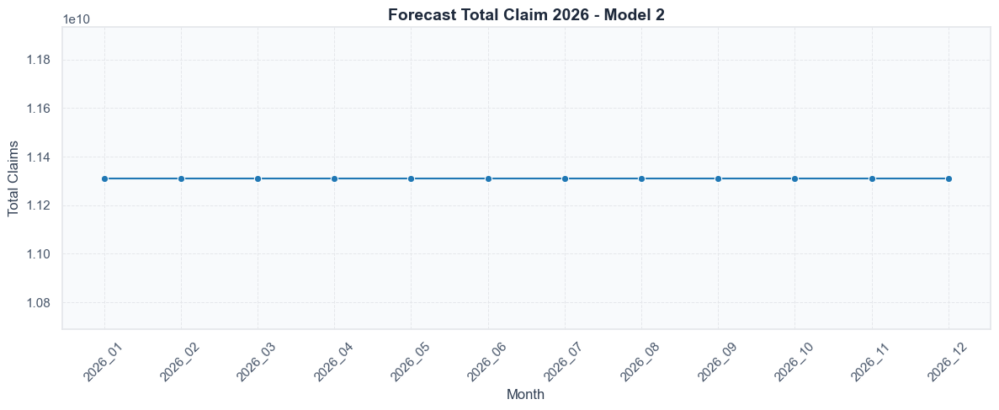

In [146]:
# F.2.4 Forecast 2026 (Model 2)

forecast_months_2026 = [f"2026_{m:02d}" for m in range(1, 13)]
df_m2_source = df_model_2 if "df_model_2" in globals() else df_model_2_scaled
severity_m2_2026 = severity if "severity" in globals() else None  # opsional, bisa None

result_m2_2026 = predict_model_2(
	df_input=df_m2_source,
	forecast_months=forecast_months_2026,
	year_month_col="YearMonth",
	frequency_col="total_claim_frequency",
	severity_value=severity_m2_2026,
	output_file="submission_model_2_2026.csv",
	verbose=True,
)

forecast_df_m2_2026 = result_m2_2026["forecast_df"].copy()
submission_m2_2026 = result_m2_2026["submission_df"].copy()

# Ringkasan kuartalan
forecast_df_m2_2026["Month_dt"] = pd.to_datetime(
	forecast_df_m2_2026["Month"].str.replace("_", "-", regex=False) + "-01"
)
forecast_df_m2_2026["Quarter"] = forecast_df_m2_2026["Month_dt"].dt.to_period("Q").astype(str)

quarter_summary_m2_2026 = (
	forecast_df_m2_2026.groupby("Quarter", as_index=False)
	.agg(
		avg_frequency=("Frequency", "mean"),
		total_claims=("Total_Claims", "sum")
	)
)

display(forecast_df_m2_2026[["Month", "Frequency", "Severity", "Total_Claims", "Quarter"]])
display(quarter_summary_m2_2026)
display(submission_m2_2026)

# Visualisasi total claim 2026
plt.figure(figsize=(12, 5))
sns.lineplot(
	data=forecast_df_m2_2026.sort_values("Month_dt"),
	x="Month",
	y="Total_Claims",
	marker="o"
)
plt.title("Forecast Total Claim 2026 - Model 2")
plt.xlabel("Month")
plt.ylabel("Total Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Berdasarkan hasil forecast 2026, Model 2 menunjukkan pola monoton pada Total Claims (lebih tepatnya konstan/non-decreasing) dari Januari sampai Desember. Pola ini konsisten dengan desain model karena komponen ensemble didominasi MA3 konservatif (50%), sementara komponen Linear Trend dan EMA+Trend pada data akhir historis memiliki kemiringan yang sangat kecil sehingga prediksi frekuensi cenderung stabil setelah proses pembulatan integer. Selain itu, nilai severity dipertahankan tetap per periode, sehingga ketika Frequency stabil maka nilai Total Claims = Frequency x Severity juga menjadi stabil dan membentuk garis datar. Dengan demikian, pola monoton pada Model 2 bukan anomali, melainkan konsekuensi metodologis dari pendekatan yang sengaja menekankan stabilitas dan ketahanan terhadap fluktuasi jangka pendek.

### F.3 Model 3

#### F.3.1 Define Model 3 Function (Use Daily)

In [ ]:
# F.3.1 FUNCTION KHUSUS MODEL + CV (tanpa preprocessing)
def build_model_3_rf(random_state=42):
    return RandomForestRegressor(
        n_estimators=500,
        max_depth=8,
        min_samples_leaf=2,
        random_state=random_state
    )

def get_model_3_tscv(X, n_splits=5):
    n_splits_used = min(n_splits, len(X) - 1)
    if n_splits_used < 2:
        raise ValueError('Data tidak cukup untuk TimeSeriesSplit.')
    return TimeSeriesSplit(n_splits=n_splits_used)


def build_m3_exog_profile(daily_df, exog_cols):
    if not exog_cols:
        return None, None

    exog_profile_dow = daily_df.groupby('dayofweek')[exog_cols].mean()
    exog_fallback = daily_df[exog_cols].mean(numeric_only=True)
    return exog_profile_dow, exog_fallback


def build_m3_recursive_feature_row(
    dt,
    history_series,
    feature_cols,
    exog_profile_dow=None,
    exog_fallback=None,
):
    lag_1 = history_series.iloc[-1]
    lag_7 = history_series.iloc[-7] if len(history_series) >= 7 else history_series.mean()
    lag_14 = history_series.iloc[-14] if len(history_series) >= 14 else history_series.mean()

    roll_window = history_series.iloc[-7:] if len(history_series) >= 7 else history_series
    roll_mean_7 = roll_window.mean()
    roll_std_7 = roll_window.std(ddof=0) if len(roll_window) > 1 else 0.0

    row = {
        'trend': float(len(history_series)),
        'dayofweek': dt.dayofweek,
        'day': dt.day,
        'month': dt.month,
        'quarter': dt.quarter,
        'weekofyear': int(dt.isocalendar().week),
        'is_weekend': int(dt.dayofweek >= 5),
        'is_month_start': int(dt.is_month_start),
        'is_month_end': int(dt.is_month_end),
        'lag_1': float(lag_1),
        'lag_7': float(lag_7),
        'lag_14': float(lag_14),
        'roll_mean_7': float(roll_mean_7),
        'roll_std_7': float(roll_std_7),
    }


    exog_cols_local = [c for c in feature_cols if c.startswith('raw_cat_') or c.startswith('raw_num_')]
    if exog_cols_local:
        if exog_profile_dow is not None and dt.dayofweek in exog_profile_dow.index:
            exog_vals = exog_profile_dow.loc[dt.dayofweek]
        else:
            exog_vals = exog_fallback
        for c in exog_cols_local:
            if exog_vals is not None and c in exog_vals.index:
                row[c] = float(exog_vals[c])
            else:
                row[c] = 0.0
    feat_row = pd.DataFrame([row])
    for c in feature_cols:
        if c not in feat_row.columns:
            feat_row[c] = 0.0

    return feat_row[feature_cols]





def recursive_daily_forecast_m3(
    model,
    history_series,
    start_date,
    end_date,
    feature_cols,
    exog_profile_dow=None,
    exog_fallback=None,
):

    history = history_series.copy().astype(float)
    pred_dates = pd.date_range(start=start_date, end=end_date, freq='D')
    preds = []

    for dt in pred_dates:
        feat_row = build_m3_recursive_feature_row(
            dt=dt,
            history_series=history,
            feature_cols=feature_cols,
            exog_profile_dow=exog_profile_dow,
            exog_fallback=exog_fallback,
        )

        pred_val = float(model.predict(feat_row)[0])
        pred_val = max(pred_val, 0.0)

        preds.append(pred_val)
        history.loc[dt] = pred_val

    return pd.Series(preds, index=pred_dates, name='Pred')


Model berbasis Random Forest yang dirancang untuk menangkap pola non-linear pada data klaim. Evaluasinya memakai TimeSeriesSplit agar validasi tetap mengikuti urutan waktu (masa lalu untuk training, masa depan untuk testing), lalu model belajar dari fitur kalender (hari, bulan, kuartal, weekend), fitur lag (1, 7, 14 hari), statistik rolling 7 hari, dan fitur eksogen yang diringkas per hari dalam seminggu. Saat prediksi, pendekatannya recursive: model memprediksi satu hari ke depan, hasil prediksi itu dimasukkan ke histori, lalu dipakai lagi untuk memprediksi hari berikutnya sampai akhir periode. Jadi intinya: model pohon untuk pola kompleks + fitur time-series + prediksi bertahap, dengan konsekuensi error awal bisa terbawa ke langkah berikutnya.

#### F.3.2 Cross Validation Model 3

In [107]:
def safe_mape_nonzero(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > eps
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))


def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.abs(y_true) + np.abs(y_pred) + eps
    return np.mean(2.0 * np.abs(y_pred - y_true) / denom)


def run_model_3_cv_only(X, y, date_series, label, n_splits=5):
    tscv_local = get_model_3_tscv(X, n_splits=n_splits)

    cv_rows = []
    for fold, (train_idx, test_idx) in enumerate(tscv_local.split(X), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model = build_model_3_rf(random_state=42 + fold)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        cv_rows.append({
            'Fold': fold,
            'Train_Start': date_series.iloc[train_idx[0]].strftime('%Y-%m-%d'),
            'Train_End':   date_series.iloc[train_idx[-1]].strftime('%Y-%m-%d'),
            'Test_Start':  date_series.iloc[test_idx[0]].strftime('%Y-%m-%d'),
            'Test_End':    date_series.iloc[test_idx[-1]].strftime('%Y-%m-%d'),
            'MAE':          np.mean(np.abs(y_test.values - pred)),
            'RMSE':         np.sqrt(np.mean((y_test.values - pred) ** 2)),
            'MAPE_nonzero': safe_mape_nonzero(y_test.values, pred),
            'sMAPE':        smape(y_test.values, pred),
        })

    cv_df = pd.DataFrame(cv_rows)

    print(f"\n=== CV Only | {label} ===")
    display(cv_df)
    print(f"Avg MAE          : {cv_df['MAE'].mean():,.4f}")
    print(f"Avg RMSE         : {cv_df['RMSE'].mean():,.4f}")
    print(f"Avg MAPE_nonzero : {cv_df['MAPE_nonzero'].mean():.2%}")
    print(f"Avg sMAPE        : {cv_df['sMAPE'].mean():.2%}")

    return cv_df


# Cross-Validation — Claim Frequency (harian)
cv_m3_freq = run_model_3_cv_only(
    X=X_m3_freq,
    y=y_m3_freq,
    date_series=date_m3_freq,
    label='Model 3 - Daily Claim Frequency (Raw Daily Features)'
)

# Cross-Validation — Total Nominal Klaim (harian)
cv_m3_nom = run_model_3_cv_only(
    X=X_m3_nom,
    y=y_m3_nom,
    date_series=date_m3_nom,
    label='Model 3 - Daily Total Nominal Klaim (Raw Daily Features)'
)


=== CV Only | Model 3 - Daily Claim Frequency (Raw Daily Features) ===


,Fold,Train_Start,Train_End,Test_Start,Test_End,MAE,RMSE,MAPE_nonzero,sMAPE
0,1,2024-01-15,2024-04-17,2024-04-18,2024-07-20,2.201720,2.866933,0.413820,0.321597
1,2,2024-01-15,2024-07-20,2024-07-21,2024-10-22,1.559450,2.003219,0.312705,0.277136
2,3,2024-01-15,2024-10-22,2024-10-23,2025-01-24,1.715318,2.286645,0.327146,0.324510
3,4,2024-01-15,2025-01-24,2025-01-25,2025-04-28,1.626462,2.101286,0.324458,0.304995
4,5,2024-01-15,2025-04-28,2025-04-29,2025-07-31,1.441323,1.857368,0.224065,0.255127


Avg MAE          : 1.7089
Avg RMSE         : 2.2231
Avg MAPE_nonzero : 32.04%
Avg sMAPE        : 29.67%

=== CV Only | Model 3 - Daily Total Nominal Klaim (Raw Daily Features) ===


,Fold,Train_Start,Train_End,Test_Start,Test_End,MAE,RMSE,MAPE_nonzero,sMAPE
0,1,2024-01-15,2024-04-17,2024-04-18,2024-07-20,1.535919e+08,2.146654e+08,1.729032,0.544473
1,2,2024-01-15,2024-07-20,2024-07-21,2024-10-22,1.290893e+08,2.086743e+08,0.914513,0.432936
2,3,2024-01-15,2024-10-22,2024-10-23,2025-01-24,1.031654e+08,1.525254e+08,0.799663,0.414128
3,4,2024-01-15,2025-01-24,2025-01-25,2025-04-28,1.389555e+08,3.401566e+08,0.978712,0.403654
4,5,2024-01-15,2025-04-28,2025-04-29,2025-07-31,1.265364e+08,2.089476e+08,0.370861,0.328917


Avg MAE          : 130,267,706.5478
Avg RMSE         : 224,993,862.6952
Avg MAPE_nonzero : 95.86%
Avg sMAPE        : 42.48%


#### F.3.3 Forecast August to December 2025

In [108]:
# Prediksi harian recursive lalu agregasi ke bulan Agustus-Desember 2025
forecast_start_m3 = pd.Timestamp('2025-08-01')
forecast_end_m3 = pd.Timestamp('2025-12-31')
forecast_months_m3 = pd.period_range('2025-08', '2025-12', freq='M')



# Seri historis harian dari dataset preprocessing E.3
hist_daily = m3_daily.set_index('Date').sort_index()
hist_freq_daily = hist_daily['target_frequency'].astype(float)
hist_nom_daily = hist_daily['target_nominal'].astype(float)



# Profil fitur raw harian (untuk estimasi fitur exogenous saat forecasting)
exog_profile_dow, exog_fallback = build_m3_exog_profile(m3_daily, m3_exog_cols)



# Train model pada seluruh data harian yang sudah dipreproses
model_m3_freq = build_model_3_rf(random_state=42)
model_m3_freq.fit(X_m3_freq, y_m3_freq)
model_m3_nom = build_model_3_rf(random_state=42)
model_m3_nom.fit(X_m3_nom, y_m3_nom)



anchor_date_m3 = hist_freq_daily.index.max() + pd.Timedelta(days=1)
pred_start_m3 = max(anchor_date_m3, forecast_start_m3)



if pred_start_m3 <= forecast_end_m3:
    pred_freq_daily = recursive_daily_forecast_m3(
        model=model_m3_freq,
        history_series=hist_freq_daily,
        start_date=pred_start_m3,
        end_date=forecast_end_m3,
        feature_cols=m3_feature_cols_freq,
        exog_profile_dow=exog_profile_dow,
        exog_fallback=exog_fallback,
    )



    pred_nom_daily = recursive_daily_forecast_m3(
        model=model_m3_nom,
        history_series=hist_nom_daily,
        start_date=pred_start_m3,
        end_date=forecast_end_m3,
        feature_cols=m3_feature_cols_nom,
        exog_profile_dow=exog_profile_dow,
        exog_fallback=exog_fallback,
    )

else:
    pred_freq_daily = pd.Series(dtype=float, name='Pred')
    pred_nom_daily = pd.Series(dtype=float, name='Pred')



# Jika sebagian periode Agustus 2025 sudah ada aktual, gabungkan aktual + prediksi
actual_end_m3 = min(pred_start_m3 - pd.Timedelta(days=1), forecast_end_m3)
if actual_end_m3 >= forecast_start_m3:
    actual_freq_part = hist_freq_daily.loc[forecast_start_m3:actual_end_m3]
    actual_nom_part = hist_nom_daily.loc[forecast_start_m3:actual_end_m3]
else:
    actual_freq_part = pd.Series(dtype=float)
    actual_nom_part = pd.Series(dtype=float)



monthly_actual_freq = (
    actual_freq_part.groupby(actual_freq_part.index.to_period('M')).sum()
    if len(actual_freq_part) > 0 else pd.Series(dtype=float)
)

monthly_actual_nom = (
    actual_nom_part.groupby(actual_nom_part.index.to_period('M')).sum()
    if len(actual_nom_part) > 0 else pd.Series(dtype=float)
)



monthly_pred_freq = (
    pred_freq_daily.groupby(pred_freq_daily.index.to_period('M')).sum()
    if len(pred_freq_daily) > 0 else pd.Series(dtype=float)
)
monthly_pred_nom = (
    pred_nom_daily.groupby(pred_nom_daily.index.to_period('M')).sum()
    if len(pred_nom_daily) > 0 else pd.Series(dtype=float)
)


monthly_freq_total = monthly_actual_freq.add(monthly_pred_freq, fill_value=0).reindex(forecast_months_m3, fill_value=0)
monthly_nom_total = monthly_actual_nom.add(monthly_pred_nom, fill_value=0).reindex(forecast_months_m3, fill_value=0)



forecast_m3_2025 = pd.DataFrame({
    'Month': [str(m) for m in forecast_months_m3],
    'Pred_Claim_Frequency': np.round(monthly_freq_total.values).astype(int),
    'Pred_Total_Approved_Claim': monthly_nom_total.values,
})



forecast_m3_2025['Pred_Claim_Severity'] = np.where(
    forecast_m3_2025['Pred_Claim_Frequency'] > 0,
    forecast_m3_2025['Pred_Total_Approved_Claim'] / forecast_m3_2025['Pred_Claim_Frequency'],
    0.0,
)


display(forecast_m3_2025)



# Optional: format submission style
rows_m3 = []
for _, r in forecast_m3_2025.iterrows():
    month_key = r['Month'].replace('-', '_')
    rows_m3.append({'id': f'{month_key}_Claim_Frequency', 'value': float(r['Pred_Claim_Frequency'])})
    rows_m3.append({'id': f'{month_key}_Claim_Severity', 'value': float(r['Pred_Claim_Severity'])})
    rows_m3.append({'id': f'{month_key}_Total_Claim', 'value': float(r['Pred_Total_Approved_Claim'])})



submission_m3_2025 = pd.DataFrame(rows_m3)
display(submission_m3_2025)


,Month,Pred_Claim_Frequency,Pred_Total_Approved_Claim,Pred_Claim_Severity
0,2025-08,337,1.841376e+10,5.464023e+07
1,2025-09,340,1.820751e+10,5.355150e+07
2,2025-10,351,1.922007e+10,5.475803e+07
3,2025-11,326,1.804199e+10,5.534354e+07
4,2025-12,354,1.924111e+10,5.435341e+07


,id,value
0,2025_08_Claim_Frequency,3.370000e+02
1,2025_08_Claim_Severity,5.464023e+07
2,2025_08_Total_Claim,1.841376e+10
3,2025_09_Claim_Frequency,3.400000e+02
4,2025_09_Claim_Severity,5.355150e+07
5,2025_09_Total_Claim,1.820751e+10
6,2025_10_Claim_Frequency,3.510000e+02
7,2025_10_Claim_Severity,5.475803e+07
8,2025_10_Total_Claim,1.922007e+10
9,2025_11_Claim_Frequency,3.260000e+02


In [148]:
submission_m3_2025.to_csv('submission_model_3_2025.csv', index=False)

,Month,Pred_Claim_Frequency,Pred_Claim_Severity,Pred_Total_Approved_Claim,Quarter
0,2026-01,345,5.315289e+07,1.833775e+10,2026Q1
1,2026-02,313,5.376819e+07,1.682944e+10,2026Q1
2,2026-03,345,5.404197e+07,1.864448e+10,2026Q1
3,2026-04,339,5.467855e+07,1.853603e+10,2026Q2
4,2026-05,337,5.464234e+07,1.841447e+10,2026Q2
5,2026-06,340,5.339238e+07,1.815341e+10,2026Q2
6,2026-07,351,5.439440e+07,1.909243e+10,2026Q3
7,2026-08,339,5.480103e+07,1.857755e+10,2026Q3
8,2026-09,340,5.433519e+07,1.847397e+10,2026Q3
9,2026-10,345,5.395071e+07,1.861299e+10,2026Q4


,Quarter,avg_frequency,total_claims
0,2026Q1,334.333333,5.381167e+10
1,2026Q2,338.666667,5.510390e+10
2,2026Q3,343.333333,5.614395e+10
3,2026Q4,343.000000,5.626224e+10


,id,value
0,2026_01_Claim_Frequency,3.450000e+02
1,2026_01_Claim_Severity,5.315289e+07
2,2026_01_Total_Claim,1.833775e+10
3,2026_02_Claim_Frequency,3.130000e+02
4,2026_02_Claim_Severity,5.376819e+07
5,2026_02_Total_Claim,1.682944e+10
6,2026_03_Claim_Frequency,3.450000e+02
7,2026_03_Claim_Severity,5.404197e+07
8,2026_03_Total_Claim,1.864448e+10
9,2026_04_Claim_Frequency,3.390000e+02


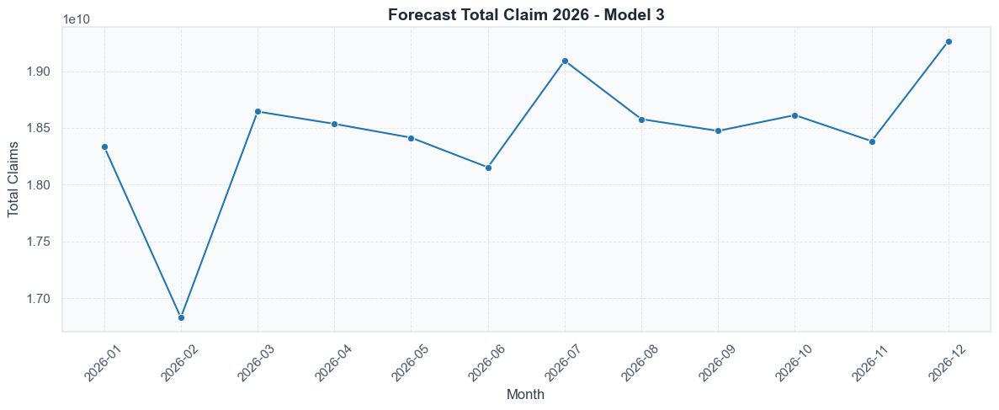

In [147]:
# Forecast Model 3 untuk tahun 2026 (harian -> bulanan)
forecast_start_2026 = pd.Timestamp("2026-01-01")
forecast_end_2026 = pd.Timestamp("2026-12-31")
forecast_months_2026 = pd.period_range("2026-01", "2026-12", freq="M")

hist_daily = m3_daily.set_index("Date").sort_index()
hist_freq = hist_daily["target_frequency"].astype(float)
hist_nom = hist_daily["target_nominal"].astype(float)

# Jika prediksi 2025-08 s.d 2025-12 sudah ada, gunakan sebagai history tambahan
if "pred_freq_daily" in globals() and len(pred_freq_daily) > 0:
	hist_freq = pd.concat([hist_freq, pred_freq_daily.astype(float)]).groupby(level=0).last().sort_index()
if "pred_nom_daily" in globals() and len(pred_nom_daily) > 0:
	hist_nom = pd.concat([hist_nom, pred_nom_daily.astype(float)]).groupby(level=0).last().sort_index()

exog_profile_dow_2026, exog_fallback_2026 = build_m3_exog_profile(m3_daily, m3_exog_cols)

model_m3_freq_2026 = build_model_3_rf(random_state=42)
model_m3_freq_2026.fit(X_m3_freq, y_m3_freq)

model_m3_nom_2026 = build_model_3_rf(random_state=42)
model_m3_nom_2026.fit(X_m3_nom, y_m3_nom)

start_recursive = hist_freq.index.max() + pd.Timedelta(days=1)
if start_recursive > forecast_end_2026:
	raise ValueError("History sudah melewati periode forecast 2026.")

pred_freq_ext = recursive_daily_forecast_m3(
	model=model_m3_freq_2026,
	history_series=hist_freq,
	start_date=start_recursive,
	end_date=forecast_end_2026,
	feature_cols=m3_feature_cols_freq,
	exog_profile_dow=exog_profile_dow_2026,
	exog_fallback=exog_fallback_2026,
)

pred_nom_ext = recursive_daily_forecast_m3(
	model=model_m3_nom_2026,
	history_series=hist_nom,
	start_date=start_recursive,
	end_date=forecast_end_2026,
	feature_cols=m3_feature_cols_nom,
	exog_profile_dow=exog_profile_dow_2026,
	exog_fallback=exog_fallback_2026,
)

pred_freq_2026 = pred_freq_ext[pred_freq_ext.index.year == 2026]
pred_nom_2026 = pred_nom_ext[pred_nom_ext.index.year == 2026]

monthly_freq_2026 = (
	pred_freq_2026.groupby(pred_freq_2026.index.to_period("M")).sum()
	.reindex(forecast_months_2026, fill_value=0.0)
)
monthly_nom_2026 = (
	pred_nom_2026.groupby(pred_nom_2026.index.to_period("M")).sum()
	.reindex(forecast_months_2026, fill_value=0.0)
)

forecast_m3_2026 = pd.DataFrame({
	"Month": forecast_months_2026.astype(str),
	"Pred_Claim_Frequency": np.round(monthly_freq_2026.values).astype(int),
	"Pred_Total_Approved_Claim": monthly_nom_2026.values,
})

forecast_m3_2026["Pred_Claim_Severity"] = np.where(
	forecast_m3_2026["Pred_Claim_Frequency"] > 0,
	forecast_m3_2026["Pred_Total_Approved_Claim"] / forecast_m3_2026["Pred_Claim_Frequency"],
	0.0,
)

rows_m3_2026 = []
for _, rr in forecast_m3_2026.iterrows():
	month_key = rr["Month"].replace("-", "_")
	rows_m3_2026.append({"id": f"{month_key}_Claim_Frequency", "value": float(rr["Pred_Claim_Frequency"])})
	rows_m3_2026.append({"id": f"{month_key}_Claim_Severity", "value": float(rr["Pred_Claim_Severity"])})
	rows_m3_2026.append({"id": f"{month_key}_Total_Claim", "value": float(rr["Pred_Total_Approved_Claim"])})

submission_m3_2026 = pd.DataFrame(rows_m3_2026)

forecast_m3_2026["Month_dt"] = pd.to_datetime(forecast_m3_2026["Month"] + "-01")
forecast_m3_2026["Quarter"] = forecast_m3_2026["Month_dt"].dt.to_period("Q").astype(str)

quarter_summary_m3_2026 = (
	forecast_m3_2026.groupby("Quarter", as_index=False)
	.agg(
		avg_frequency=("Pred_Claim_Frequency", "mean"),
		total_claims=("Pred_Total_Approved_Claim", "sum"),
	)
)

display(forecast_m3_2026[["Month", "Pred_Claim_Frequency", "Pred_Claim_Severity", "Pred_Total_Approved_Claim", "Quarter"]])
display(quarter_summary_m3_2026)
display(submission_m3_2026)

plt.figure(figsize=(12, 5))
sns.lineplot(data=forecast_m3_2026, x="Month", y="Pred_Total_Approved_Claim", marker="o")
plt.title("Forecast Total Claim 2026 - Model 3")
plt.xlabel("Month")
plt.ylabel("Total Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### F.4 Model 4

#### F.4.1 Define Model 4 (Use SARIMA)

In [151]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

def generate_sarima_forecast(df_input, severity_per_claim=200000, forecast_steps=5, seasonal_period=12):
    """
    Fungsi forecast menggunakan model SARIMA untuk menangkap tren dan musiman.
    """
    # 1. Preprocessing
    df = df_input.copy()
    df['YearMonth'] = pd.to_datetime(df['YearMonth'].astype(str) + '-01')
    df = df.sort_values('YearMonth').set_index('YearMonth')
    
    # Ambil data frekuensi
    if 'total_claim_frequency' in df.columns:
        y = df['total_claim_frequency']
    else:
        feature_cols = [c for c in df.columns if c != 'YearMonth']
        y = df[feature_cols].sum(axis=1)

    # 2. Fit Model SARIMA
    # Order (p,d,q) & Seasonal Order (P,D,Q,s)
    # Kita gunakan p=1, d=1, q=1 sebagai baseline umum
    model = SARIMAX(y, 
                    order=(1, 1, 1), 
                    seasonal_order=(1, 1, 1, seasonal_period),
                    enforce_stationarity=False,
                    enforce_invertibility=False)
    
    model_fit = model.fit(disp=False)
    
    # 3. Forecast
    forecast_obj = model_fit.get_forecast(steps=forecast_steps)
    freq_forecast = forecast_obj.predicted_mean
    conf_int = forecast_obj.conf_int() # Batas atas & bawah (confidence interval)

    # 4. Post-processing
    freq_final = np.round(np.maximum(freq_forecast, 1)).astype(int)
    total_forecast = freq_final * severity_per_claim
    
    # Label bulan
    future_dates = [d.strftime('%Y_%m') for d in freq_forecast.index]
    
    result_df = pd.DataFrame({
        'Month': future_dates,
        'Freq_Forecast': freq_final.values,
        'Lower_CI': np.round(conf_int.iloc[:, 0]).values, # Batas bawah prediksi
        'Upper_CI': np.round(conf_int.iloc[:, 1]).values, # Batas atas prediksi
        'Total_Claim_Forecast': total_forecast.values
    })
    
    return result_df, model_fit


Model ini melakukan forecasting frekuensi klaim bulanan dengan SARIMA, yaitu model time series yang menangkap pola tren + musiman sekaligus. Alurnya: data dibersihkan dulu (YearMonth jadi datetime, diurutkan), lalu target frekuensi diambil dari total_claim_frequency (atau dijumlah dari kolom fitur jika kolom itu tidak ada), kemudian model SARIMAX(1,1,1)(1,1,1,12) dilatih untuk belajar pola historis tahunan (musiman 12 bulan). Setelah itu model memprediksi beberapa bulan ke depan beserta confidence interval (batas bawah-atas), hasil frekuensi dipaksa minimal 1 dan dibulatkan ke integer agar realistis, lalu dihitung total klaim dengan rumus sederhana Total_Claim = Frequency x severity_per_claim. Output akhirnya berupa tabel bulan prediksi + frekuensi + CI + total klaim, serta objek model yang sudah fit.

In [152]:
# F.4.2 Cross Validation Model 4 (SARIMA)

def safe_mape_m4(y_true, y_pred, eps=1e-8):
	y_true = np.asarray(y_true, dtype=float)
	y_pred = np.asarray(y_pred, dtype=float)
	mask = np.abs(y_true) > eps
	if not np.any(mask):
		return np.nan
	return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def _normalize_yearmonth_m4(series):
	if pd.api.types.is_datetime64_any_dtype(series):
		return pd.to_datetime(series).dt.to_period("M").dt.to_timestamp()
	if pd.api.types.is_period_dtype(series):
		return series.dt.to_timestamp()

	normalized = (
		series.astype(str)
		.str.replace("/", "-", regex=False)
		.str.replace("_", "-", regex=False)
		.str.slice(0, 7)
	)
	return pd.to_datetime(normalized + "-01")


def _extract_frequency_m4(df_data, year_month_col="YearMonth", frequency_col="total_claim_frequency"):
	if frequency_col in df_data.columns:
		return df_data[frequency_col].astype(float).to_numpy()

	numeric_cols = [
		c for c in df_data.columns
		if c != year_month_col and pd.api.types.is_numeric_dtype(df_data[c])
	]
	if not numeric_cols:
		raise ValueError("Tidak ada kolom numerik untuk menghitung frequency aktual.")
	return df_data[numeric_cols].sum(axis=1).astype(float).to_numpy()


def _one_step_sarima_forecast_m4(history, order=(1, 1, 1), seasonal_period=12):
	# Coba SARIMA musiman dulu
	try:
		model = SARIMAX(
			history,
			order=order,
			seasonal_order=(1, 1, 1, seasonal_period),
			enforce_stationarity=False,
			enforce_invertibility=False,
		)
		fit = model.fit(disp=False)
		fc = fit.forecast(steps=1)
		pred = float(fc.iloc[0] if hasattr(fc, "iloc") else fc[0])
		return max(pred, 1.0)
	except Exception:
		pass

	# Fallback ke ARIMA non-musiman
	try:
		model = SARIMAX(
			history,
			order=order,
			seasonal_order=(0, 0, 0, 0),
			enforce_stationarity=False,
			enforce_invertibility=False,
		)
		fit = model.fit(disp=False)
		fc = fit.forecast(steps=1)
		pred = float(fc.iloc[0] if hasattr(fc, "iloc") else fc[0])
		return max(pred, 1.0)
	except Exception:
		return max(float(history.iloc[-1]), 1.0)


def cross_validate_model_4(
	df_input,
	dataset_name="dataset",
	year_month_col="YearMonth",
	frequency_col="total_claim_frequency",
	initial_train_months=12,
	forecast_horizon=1,
	step=1,
	order=(1, 1, 1),
	seasonal_period=12,
):
	df_cv = df_input.copy()

	if year_month_col not in df_cv.columns:
		raise ValueError(f"Kolom '{year_month_col}' tidak ditemukan pada {dataset_name}.")

	df_cv["_ym_dt"] = _normalize_yearmonth_m4(df_cv[year_month_col])
	df_cv = df_cv.sort_values("_ym_dt").reset_index(drop=True)

	dates = df_cv["_ym_dt"]
	y_all = _extract_frequency_m4(df_cv, year_month_col=year_month_col, frequency_col=frequency_col)

	n = len(df_cv)
	min_required = initial_train_months + forecast_horizon
	if n < min_required:
		raise ValueError(f"Data {dataset_name} terlalu pendek: {n} bulan, minimal {min_required} bulan.")

	cv_rows = []
	fold = 1

	for train_end in range(initial_train_months, n - forecast_horizon + 1, step):
		y_train = pd.Series(y_all[:train_end], index=dates.iloc[:train_end])
		y_true = y_all[train_end:train_end + forecast_horizon]

		history = y_train.copy()
		preds = []
		for h in range(forecast_horizon):
			pred = _one_step_sarima_forecast_m4(
				history=history,
				order=order,
				seasonal_period=seasonal_period,
			)
			pred = float(np.round(max(pred, 1.0)))
			preds.append(pred)

			future_dt = dates.iloc[train_end + h]
			history.loc[future_dt] = pred

		y_pred = np.asarray(preds, dtype=float)

		cv_rows.append({
			"Dataset": dataset_name,
			"Fold": fold,
			"Train_End": dates.iloc[train_end - 1].strftime("%Y-%m"),
			"Valid_Start": dates.iloc[train_end].strftime("%Y-%m"),
			"Valid_End": dates.iloc[train_end + forecast_horizon - 1].strftime("%Y-%m"),
			"MAE": np.mean(np.abs(y_true - y_pred)),
			"RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)),
			"MAPE(%)": safe_mape_m4(y_true, y_pred),
		})
		fold += 1

	cv_df = pd.DataFrame(cv_rows)

	print(f"\nCross Validation Model 4 (SARIMA) - {dataset_name}")
	print("=" * 90)
	print(cv_df.to_string(index=False))
	print("=" * 90)
	print(f"Mean MAE     : {cv_df['MAE'].mean():.4f}")
	print(f"Mean RMSE    : {cv_df['RMSE'].mean():.4f}")
	print(f"Mean MAPE(%) : {cv_df['MAPE(%)'].mean():.4f}%")

	return cv_df


# Jalankan CV pada data unscaled & scaled
cv_m4_unscaled = cross_validate_model_4(
	df_input=df_model_2,
	dataset_name="unscaled",
	initial_train_months=12,
	forecast_horizon=1,
	seasonal_period=12,
)

cv_m4_scaled = cross_validate_model_4(
	df_input=df_model_2_scaled,
	dataset_name="scaled",
	initial_train_months=12,
	forecast_horizon=1,
	seasonal_period=12,
)

cv_model_4_summary = pd.DataFrame({
	"Dataset": ["unscaled", "scaled"],
	"Total_Folds": [len(cv_m4_unscaled), len(cv_m4_scaled)],
	"Mean_MAE": [cv_m4_unscaled["MAE"].mean(), cv_m4_scaled["MAE"].mean()],
	"Mean_RMSE": [cv_m4_unscaled["RMSE"].mean(), cv_m4_scaled["RMSE"].mean()],
	"Mean_MAPE(%)": [cv_m4_unscaled["MAPE(%)"].mean(), cv_m4_scaled["MAPE(%)"].mean()],
})

print("\nSummary CV Model 4")
print("=" * 90)
display(cv_model_4_summary)

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\3349292495.py:15: DeprecationWarning: is_period_dtype is deprecated and will be removed in a future version. Use `isinstance(dtype, pd.PeriodDtype)` instead
  if pd.api.types.is_period_dtype(series):
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
c:\Users\Tuf Gaming\ana


Cross Validation Model 4 (SARIMA) - unscaled
 Dataset  Fold Train_End Valid_Start Valid_End   MAE  RMSE    MAPE(%)
unscaled     1   2024-12     2025-01   2025-01 220.0 220.0 101.851852
unscaled     2   2025-01     2025-02   2025-02 119.0 119.0  48.373984
unscaled     3   2025-02     2025-03   2025-03  11.0  11.0   4.782609
unscaled     4   2025-03     2025-04   2025-04  19.0  19.0   9.134615
unscaled     5   2025-04     2025-05   2025-05   7.0   7.0   2.928870
unscaled     6   2025-05     2025-06   2025-06  33.0  33.0  14.102564
unscaled     7   2025-06     2025-07   2025-07 136.0 136.0  51.515152
Mean MAE     : 77.8571
Mean RMSE    : 77.8571
Mean MAPE(%) : 33.2414%

Cross Validation Model 4 (SARIMA) - scaled
Dataset  Fold Train_End Valid_Start Valid_End   MAE  RMSE    MAPE(%)
 scaled     1   2024-12     2025-01   2025-01 220.0 220.0 101.851852
 scaled     2   2025-01     2025-02   2025-02 119.0 119.0  48.373984
 scaled     3   2025-02     2025-03   2025-03  11.0  11.0   4.782609
 sca

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate sta

,Dataset,Total_Folds,Mean_MAE,Mean_RMSE,Mean_MAPE(%)
0,unscaled,7,77.857143,77.857143,33.241378
1,scaled,7,77.857143,77.857143,33.241378


#### F.4.3 Forecast for August to December 2025

In [150]:
df_sarima, model_summary = generate_sarima_forecast(df_model_2_scaled)
df_sarima

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


,Month,Freq_Forecast,Lower_CI,Upper_CI,Total_Claim_Forecast
0,2025_08,267,221.0,313.0,53400000
1,2025_09,224,163.0,286.0,44800000
2,2025_10,311,234.0,387.0,62200000
3,2025_11,289,202.0,375.0,57800000
4,2025_12,272,175.0,370.0,54400000


In [154]:
df_sarima.to_csv("forecast_sarima_model_4.csv", index=False)

#### F.4.4 Forecast For 2026

c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Tuf Gaming\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


,Month,Frequency,Severity,Total_Claims,Lower_CI,Upper_CI,Quarter
0,2026_01,237,4.673966e+07,1.107730e+10,130.0,343.0,2026Q1
1,2026_02,279,4.673966e+07,1.304036e+10,164.0,394.0,2026Q1
2,2026_03,252,4.673966e+07,1.177839e+10,129.0,375.0,2026Q1
3,2026_04,239,4.673966e+07,1.117078e+10,109.0,370.0,2026Q2
4,2026_05,262,4.673966e+07,1.224579e+10,125.0,399.0,2026Q2
5,2026_06,264,4.673966e+07,1.233927e+10,121.0,408.0,2026Q2
6,2026_07,288,4.673966e+07,1.346102e+10,138.0,438.0,2026Q3
7,2026_08,297,4.673966e+07,1.388168e+10,122.0,472.0,2026Q3
8,2026_09,249,4.673966e+07,1.163817e+10,55.0,443.0,2026Q3
9,2026_10,340,4.673966e+07,1.589148e+10,126.0,553.0,2026Q4


,Quarter,avg_frequency,total_claims
0,2026Q1,256.000000,3.589606e+10
1,2026Q2,255.000000,3.575584e+10
2,2026Q3,278.000000,3.898087e+10
3,2026Q4,318.333333,4.463637e+10


,id,value
0,2026_01_Claim_Frequency,2.370000e+02
1,2026_01_Claim_Severity,4.673966e+07
2,2026_01_Total_Claim,1.107730e+10
3,2026_02_Claim_Frequency,2.790000e+02
4,2026_02_Claim_Severity,4.673966e+07
5,2026_02_Total_Claim,1.304036e+10
6,2026_03_Claim_Frequency,2.520000e+02
7,2026_03_Claim_Severity,4.673966e+07
8,2026_03_Total_Claim,1.177839e+10
9,2026_04_Claim_Frequency,2.390000e+02


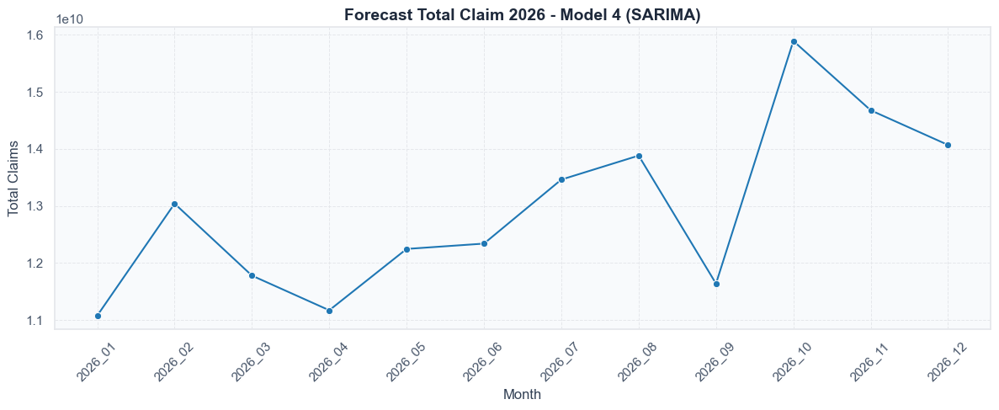

In [155]:
# F.4.4 Forecast for 2026 (Model 4 - SARIMA)

df_m4_source = df_model_2_scaled if "df_model_2_scaled" in globals() else df_model_2
severity_m4_2026 = float(severity) if "severity" in globals() else 200000.0

# Hitung horizon agar forecast mencapai 2026-12
ym_norm = (
    df_m4_source["YearMonth"].astype(str)
    .str.replace("/", "-", regex=False)
    .str.replace("_", "-", regex=False)
    .str.slice(0, 7)
)
last_obs_m4 = pd.to_datetime(ym_norm + "-01").max()
target_end_m4 = pd.Timestamp("2026-12-01")
forecast_steps_m4 = (target_end_m4.year - last_obs_m4.year) * 12 + (target_end_m4.month - last_obs_m4.month)

if forecast_steps_m4 <= 0:
    raise ValueError(f"Data terakhir ({last_obs_m4:%Y-%m}) sudah melewati 2026-12.")

# Forecast penuh sampai 2026-12, lalu ambil hanya bulan 2026
df_sarima_all_2026, model_m4_2026 = generate_sarima_forecast(
    df_input=df_m4_source,
    severity_per_claim=severity_m4_2026,
    forecast_steps=forecast_steps_m4,
    seasonal_period=12
)

forecast_m4_2026 = (
    df_sarima_all_2026[df_sarima_all_2026["Month"].str.startswith("2026_")]
    .rename(columns={"Freq_Forecast": "Frequency", "Total_Claim_Forecast": "Total_Claims"})
    .reset_index(drop=True)
)

forecast_m4_2026["Severity"] = severity_m4_2026
forecast_m4_2026["Month_dt"] = pd.to_datetime(
    forecast_m4_2026["Month"].str.replace("_", "-", regex=False) + "-01"
)
forecast_m4_2026["Quarter"] = forecast_m4_2026["Month_dt"].dt.to_period("Q").astype(str)

quarter_summary_m4_2026 = (
    forecast_m4_2026.groupby("Quarter", as_index=False)
    .agg(
        avg_frequency=("Frequency", "mean"),
        total_claims=("Total_Claims", "sum")
    )
)

# Format submission
rows_m4_2026 = []
for _, rr in forecast_m4_2026.iterrows():
    month_key = rr["Month"]
    rows_m4_2026.append({"id": f"{month_key}_Claim_Frequency", "value": float(rr["Frequency"])})
    rows_m4_2026.append({"id": f"{month_key}_Claim_Severity", "value": float(rr["Severity"])})
    rows_m4_2026.append({"id": f"{month_key}_Total_Claim", "value": float(rr["Total_Claims"])})

submission_m4_2026 = pd.DataFrame(rows_m4_2026)

display(forecast_m4_2026[["Month", "Frequency", "Severity", "Total_Claims", "Lower_CI", "Upper_CI", "Quarter"]])
display(quarter_summary_m4_2026)
display(submission_m4_2026)

plt.figure(figsize=(12, 5))
sns.lineplot(data=forecast_m4_2026, x="Month", y="Total_Claims", marker="o")
plt.title("Forecast Total Claim 2026 - Model 4 (SARIMA)")
plt.xlabel("Month")
plt.ylabel("Total Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Optional save:
# submission_m4_2026.to_csv("submission_model_4_2026.csv", index=False)

## G. Analysis

### G.1. Feature Importance

#### G.1.1 Feature Importance Model 1

In [110]:
# Model 1 Feature Importance
fi_folds = []

fi_df = df_model_1.reset_index().copy()
if 'YearMonth' not in fi_df.columns:
    fi_df = fi_df.rename(columns={fi_df.columns[0]: 'YearMonth'})

fi_df['YearMonth'] = pd.to_datetime(fi_df['YearMonth'])
fi_df = fi_df.sort_values('YearMonth').reset_index(drop=True)

target_col_fi = 'Total_Nominal' if 'Total_Nominal' in fi_df.columns else 'Frequency'

fi_df['month'] = fi_df['YearMonth'].dt.month
fi_df['quarter'] = fi_df['YearMonth'].dt.quarter
fi_df['trend_idx'] = np.arange(len(fi_df))
fi_df['lag_1'] = fi_df[target_col_fi].shift(1)
fi_df['lag_2'] = fi_df[target_col_fi].shift(2)
fi_df['lag_3'] = fi_df[target_col_fi].shift(3)
fi_df['roll_mean_3'] = fi_df[target_col_fi].shift(1).rolling(3).mean()
fi_df['roll_std_3'] = fi_df[target_col_fi].shift(1).rolling(3).std()

fi_df = fi_df.dropna().reset_index(drop=True)
feature_cols_fi = [
    'month', 'quarter', 'trend_idx', 'lag_1', 'lag_2', 'lag_3', 'roll_mean_3', 'roll_std_3'
]

if len(fi_df) < 6:
    uniform_importance = np.repeat(1 / len(feature_cols_fi), len(feature_cols_fi))
    fi_folds.append(pd.Series(uniform_importance, index=feature_cols_fi, name='Fold_1'))
else:
    n_splits_fi = min(5, len(fi_df) - 1)
    n_splits_fi = max(2, n_splits_fi)

    tscv_fi = TimeSeriesSplit(n_splits=n_splits_fi)
    X_fi = fi_df[feature_cols_fi]
    y_fi = fi_df[target_col_fi]

    for fold_idx, (train_idx, _) in enumerate(tscv_fi.split(X_fi), start=1):
        rf_fi = RandomForestRegressor(
            n_estimators=300,
            random_state=42 + fold_idx,
            n_jobs=-1
        )
        rf_fi.fit(X_fi.iloc[train_idx], y_fi.iloc[train_idx])

        fi_folds.append(
            pd.Series(rf_fi.feature_importances_, index=feature_cols_fi, name=f'Fold_{fold_idx}')
        )


,Feature,Importance
0,roll_mean_3,0.225261
1,roll_std_3,0.150024
2,lag_2,0.147026
3,lag_1,0.129188
4,lag_3,0.112371
5,trend_idx,0.103221
6,month,0.085860
7,quarter,0.047050


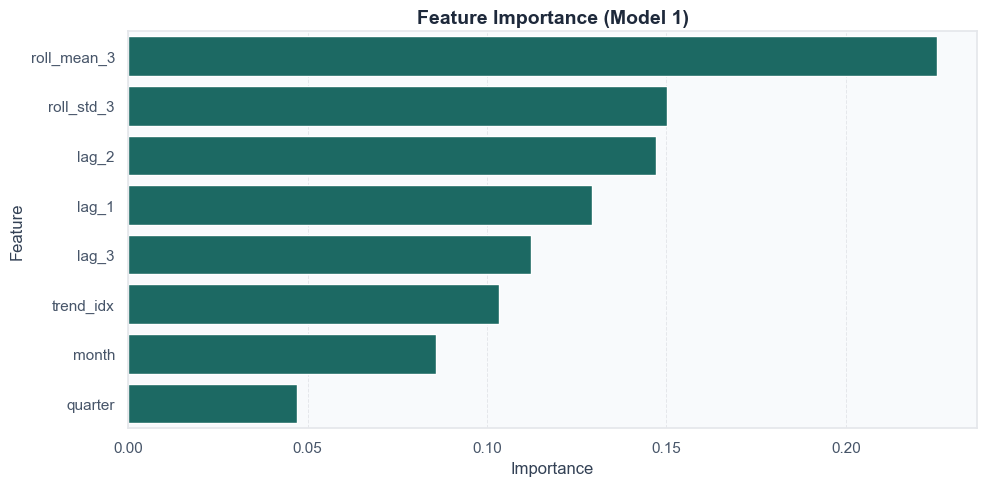

In [111]:
df_compare_claim_biayars = (
    df.groupby('YearMonth')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
    )
    .reset_index()
)
df_compare_claim_biayars['YearMonth'] = df_compare_claim_biayars['YearMonth'].astype(str)

df_compare_claim_biayars_quarter = (
    df.groupby('Quarter')
    .agg(
        total_nominal_klaim=('Nominal Klaim Yang Disetujui', 'sum'),
        total_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'sum'),
        avg_nominal_klaim=('Nominal Klaim Yang Disetujui', 'mean'),
        avg_biaya_rs=('Nominal Biaya RS Yang Terjadi', 'mean'),
    )
    .reset_index()
)
df_compare_claim_biayars_quarter['Quarter'] = df_compare_claim_biayars_quarter['Quarter'].astype(str)

df_long = df_compare_claim_biayars_quarter.melt(
    id_vars='Quarter',
    value_vars=['total_nominal_klaim', 'total_biaya_rs'],
    var_name='Jenis',
    value_name='Jumlah'
)
df_long_avg = df_compare_claim_biayars_quarter.melt(
    id_vars='Quarter',
    value_vars=['avg_nominal_klaim', 'avg_biaya_rs'],
    var_name='Jenis',
    value_name='Jumlah'
)

feature_importance_df = (
    pd.concat(fi_folds, axis=1)
    .mean(axis=1)
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={'index': 'Feature', 0: 'Importance'})
)

display(feature_importance_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature', color='#0f766e')
plt.title('Feature Importance (Model 1)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Hasil dari Feature importance menunjukkan bahwasanya Fitur Rolling WIndow 3 Bulan lah yang memiliki pengaruh yang paling besar dalam model hybrid ini. Ini pun di dukung pada grafik trend Nominal Klaim yang memiliki pattern yang cukup konsisten setiap 3 bulan yang meskipun tidak selalu sama tetapi setiap quartalnya memiliki karakteristiknya masing-masing.


#### G.1.2 Feature Importance Model 2

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\1580572524.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako')


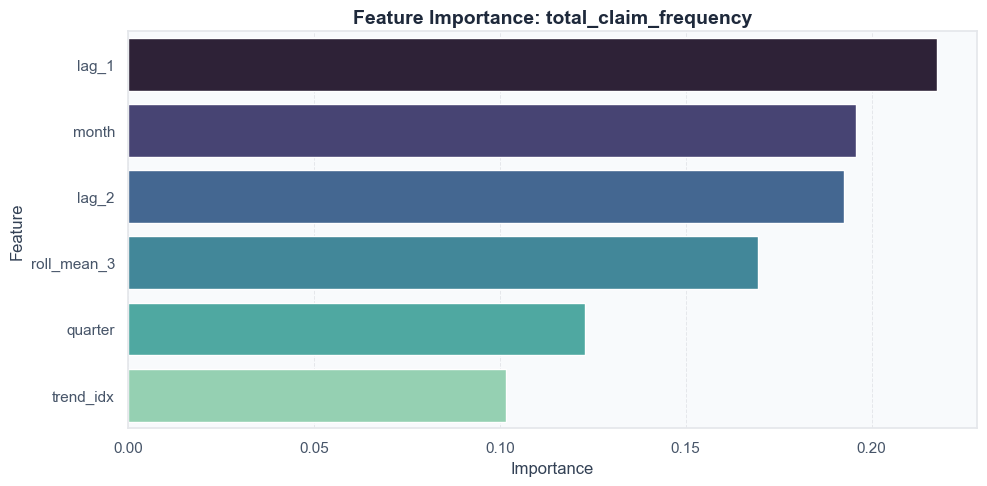

,Feature,Importance
3,lag_1,0.217501
0,month,0.195909
4,lag_2,0.192528
5,roll_mean_3,0.169514
1,quarter,0.122804
2,trend_idx,0.101744


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\1580572524.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako')


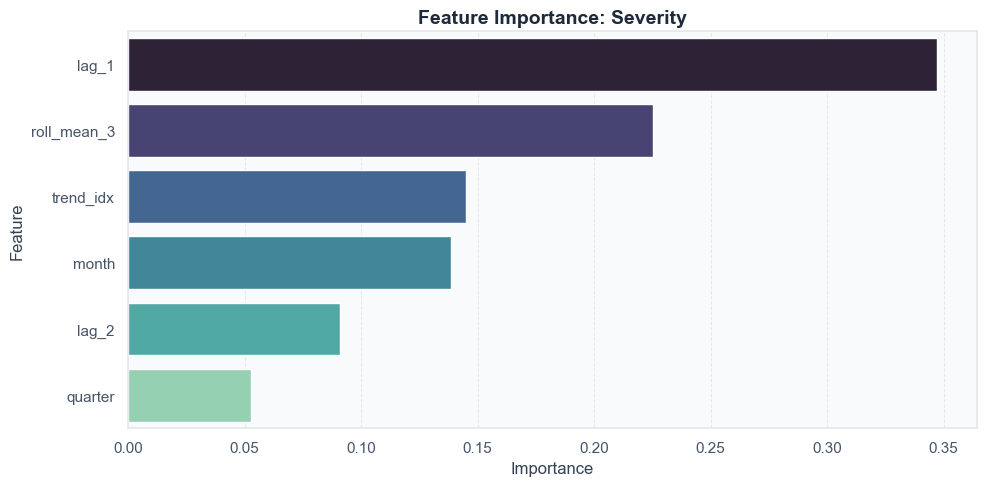

,Feature,Importance
3,lag_1,0.346984
5,roll_mean_3,0.225348
2,trend_idx,0.144965
0,month,0.138665
4,lag_2,0.091125
1,quarter,0.052913


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\1580572524.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako')


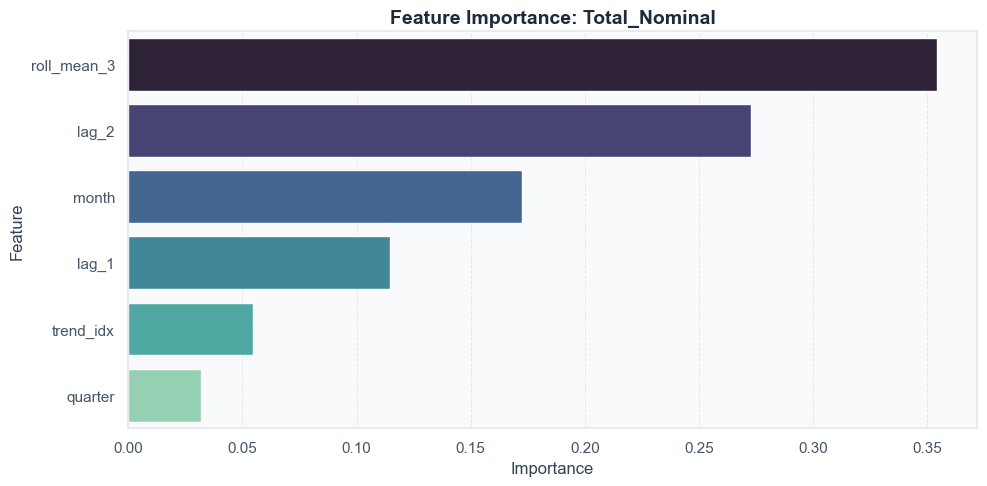

,Feature,Importance
5,roll_mean_3,0.353976
4,lag_2,0.272566
0,month,0.172357
3,lag_1,0.114641
2,trend_idx,0.054575
1,quarter,0.031885


In [112]:
def get_monthly_feature_importance(df_input, target_col='total_claim_frequency', year_month_col='YearMonth'):
    
    # Preprocessing Data Bulanan

    df = df_input.copy()



    # Support jika YearMonth tersimpan sebagai index

    if year_month_col not in df.columns:

        if df.index.name == year_month_col:

            df = df.reset_index()

        else:

            raise KeyError(

                f"Kolom '{year_month_col}' tidak ditemukan. "

            )



    if target_col not in df.columns:

        raise KeyError(f"Kolom target '{target_col}' tidak ada di DataFrame.")



    df[year_month_col] = pd.to_datetime(df[year_month_col])

    df = df.sort_values(year_month_col).reset_index(drop=True)



    # 1. Feature Engineering

    df['month'] = df[year_month_col].dt.month

    df['quarter'] = df[year_month_col].dt.quarter

    df['trend_idx'] = np.arange(len(df))  # Mewakili linear trend



    # Fitur lag (sangat penting untuk klaim)

    df['lag_1'] = df[target_col].shift(1)

    df['lag_2'] = df[target_col].shift(2)

    df['roll_mean_3'] = df[target_col].shift(1).rolling(3).mean()



    df = df.dropna().reset_index(drop=True)

    if df.empty:

        raise ValueError("Error coy")



    features = ['month', 'quarter', 'trend_idx', 'lag_1', 'lag_2', 'roll_mean_3']

    X = df[features]

    y = df[target_col]



    # 2. Fit Model untuk mencari importance

    model = RandomForestRegressor(n_estimators=500, random_state=42)

    model.fit(X, y)



    fi_df = pd.DataFrame({

        'Feature': features,

        'Importance': model.feature_importances_

    }).sort_values('Importance', ascending=False)



    # Visualisasi

    plt.figure(figsize=(10, 5))

    sns.barplot(data=fi_df, x='Importance', y='Feature', palette='mako')

    plt.title(f'Feature Importance: {target_col}')

    plt.tight_layout()

    plt.show()



    return fi_df, X, y



# Versi Frequency (model bulanan untuk frequency)

fi_frequency, X_frequency, y_frequency = get_monthly_feature_importance(

    df_model_2_scaled,

    target_col='total_claim_frequency',

    year_month_col='YearMonth'

)

display(fi_frequency)



# Versi Severity

fi_severity, X_severity, y_severity = get_monthly_feature_importance(

    df_model_1,

    target_col='Severity',

    year_month_col='YearMonth'

)

display(fi_severity)



# Versi Nominal Klaim

fi_nominal, X_nominal, y_nominal = get_monthly_feature_importance(

    df_model_1,

    target_col='Total_Nominal',

    year_month_col='YearMonth'

)

display(fi_nominal)


#### G.1.3 Feature Importance Model 3

Severity daily dataset siap: 564 baris, 1778 fitur

=== Feature Importance | Model 3 - Daily Claim Frequency (Raw Daily Features) ===


,Feature,Importance
0,raw_cat_Lokasi RS=Singapore,0.168175
1,dayofweek,0.149838
2,is_weekend,0.101783
3,raw_cat_ICD_prefix=C,0.080504
4,raw_cat_Reimburse/Cashless=R,0.027211
5,raw_cat_ICD_prefix=H,0.026699
6,raw_cat_ICD_prefix=D,0.024434
7,raw_cat_ICD_prefix=M,0.021288
8,raw_cat_ICD_prefix=K,0.020183
9,raw_cat_Lokasi RS=Indonesia,0.018165


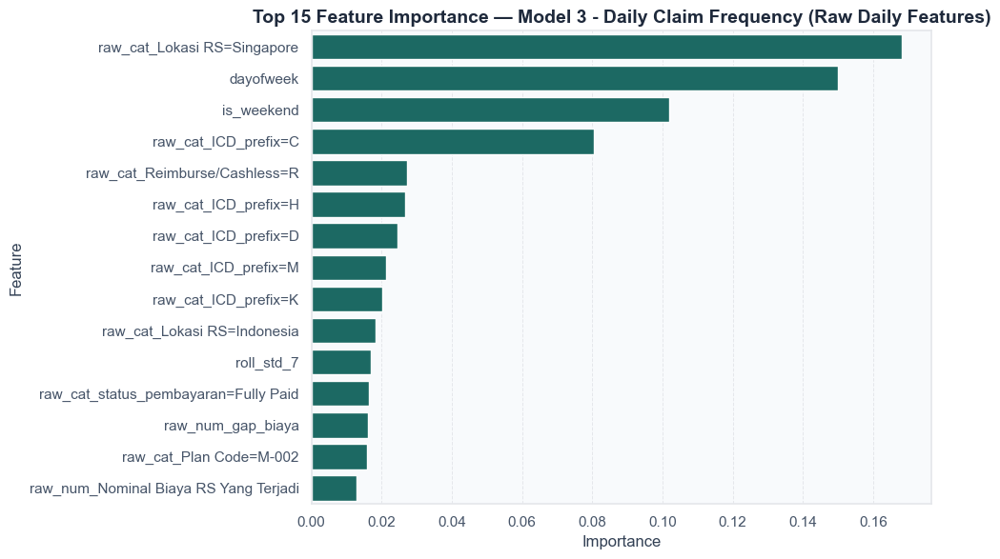


=== Feature Importance | Model 3 - Daily Claim Severity / Nominal per Klaim (Raw Daily Features) ===


,Feature,Importance
0,raw_num_Nominal Biaya RS Yang Terjadi,0.911135
1,raw_num_gap_biaya,0.017708
2,raw_cat_Domisili=SURABAYA,0.011754
3,raw_cat_Lokasi RS=Indonesia,0.007995
4,raw_cat_Lokasi RS=Singapore,0.005063
5,day,0.003180
6,raw_cat_ICD_prefix=M,0.002845
7,raw_cat_ICD Diagnosis=I73.9,0.002824
8,raw_cat_Gender=M,0.002399
9,lag_1,0.002164


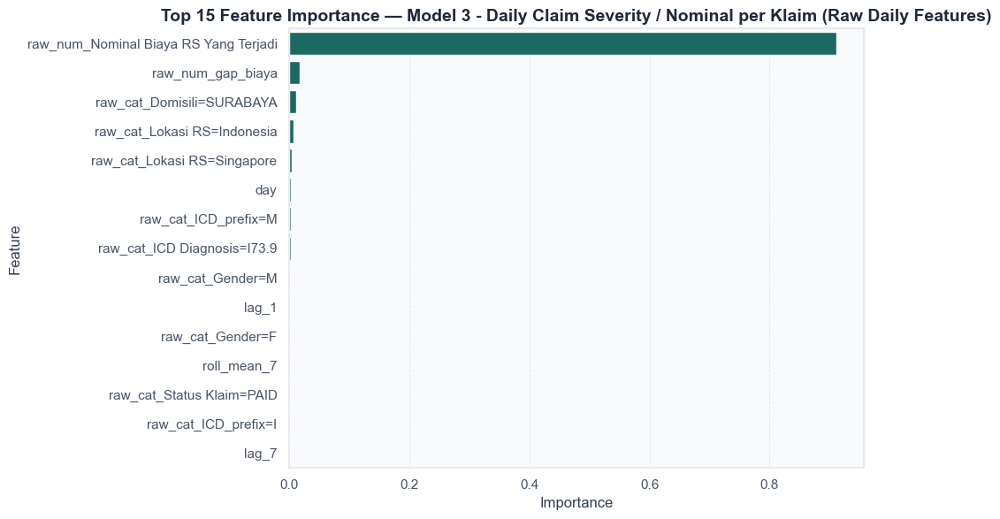


=== Feature Importance | Model 3 - Daily Total Nominal Klaim (Raw Daily Features) ===


,Feature,Importance
0,raw_num_Nominal Biaya RS Yang Terjadi,0.589420
1,raw_cat_Lokasi RS=Singapore,0.052254
2,raw_num_gap_biaya,0.050593
3,raw_cat_Lokasi RS=Indonesia,0.037712
4,dayofweek,0.013521
5,raw_cat_ICD_prefix=C,0.011111
6,raw_cat_ICD_prefix=M,0.010136
7,raw_cat_ICD_prefix=I,0.010066
8,raw_cat_Reimburse/Cashless=R,0.009544
9,raw_cat_Domisili=JAKARTA,0.008016


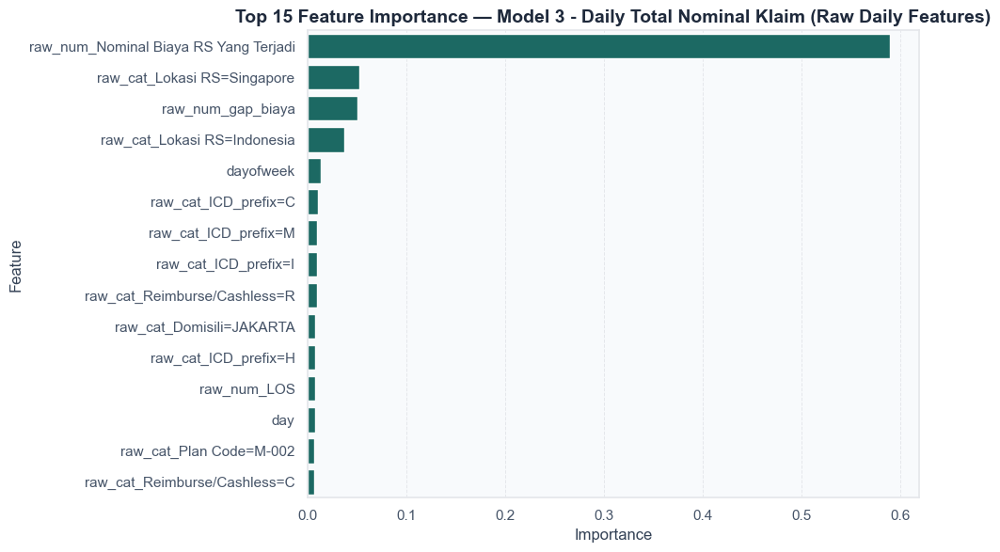

In [113]:
def run_model_3_feature_importance_only(X, y, feature_cols, label, n_splits=5):
    tscv_local = get_model_3_tscv(X, n_splits=n_splits)

    fi_folds = []
    for fold, (train_idx, _) in enumerate(tscv_local.split(X), start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

        model = build_model_3_rf(random_state=142 + fold)
        model.fit(X_train, y_train)

        fi_folds.append(
            pd.Series(model.feature_importances_, index=feature_cols, name=f'Fold_{fold}')
        )

    fi_df = (
        pd.concat(fi_folds, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
        .reset_index()
        .rename(columns={'index': 'Feature', 0: 'Importance'})
    )

    print(f"\n=== Feature Importance | {label} ===")
    display(fi_df.head(20))

    plt.figure(figsize=(10, 6))
    sns.barplot(data=fi_df.head(15), x='Importance', y='Feature', color='#0f766e')
    plt.title(f'Top 15 Feature Importance — {label}')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

    return fi_df


# --- Turunkan target Claim Severity harian (rata-rata nominal per klaim) ---
m3_daily_sev = m3_daily.copy()
m3_daily_sev['target_severity'] = np.where(
    m3_daily_sev['target_frequency'] > 0,
    m3_daily_sev['target_nominal'] / m3_daily_sev['target_frequency'],
    0.0
)
m3_sev_daily, X_m3_sev, y_m3_sev, date_m3_sev, m3_feature_cols_sev = build_m3_target_dataset(
    m3_daily_sev, 'target_severity'
)
print(f"Severity daily dataset siap: {X_m3_sev.shape[0]} baris, {X_m3_sev.shape[1]} fitur")


# Feature Importance — Claim Frequency
fi_m3_freq = run_model_3_feature_importance_only(
    X=X_m3_freq,
    y=y_m3_freq,
    feature_cols=m3_feature_cols_freq,
    label='Model 3 - Daily Claim Frequency (Raw Daily Features)'
)

# Feature Importance — Claim Severity (Nominal per Klaim, harian)
fi_m3_sev = run_model_3_feature_importance_only(
    X=X_m3_sev,
    y=y_m3_sev,
    feature_cols=m3_feature_cols_sev,
    label='Model 3 - Daily Claim Severity / Nominal per Klaim (Raw Daily Features)'
)

# Feature Importance — Total Nominal Klaim
fi_m3_nom = run_model_3_feature_importance_only(
    X=X_m3_nom,
    y=y_m3_nom,
    feature_cols=m3_feature_cols_nom,
    label='Model 3 - Daily Total Nominal Klaim (Raw Daily Features)'
)

### G.2. Predictive Analysis 2026

### G.3. Advanced Deeper Data Analysis

#### G.3.1. Claim vs Hospital Cost Analysis

##### G.3.1.1. Total Claim vs Total Hospital Cost

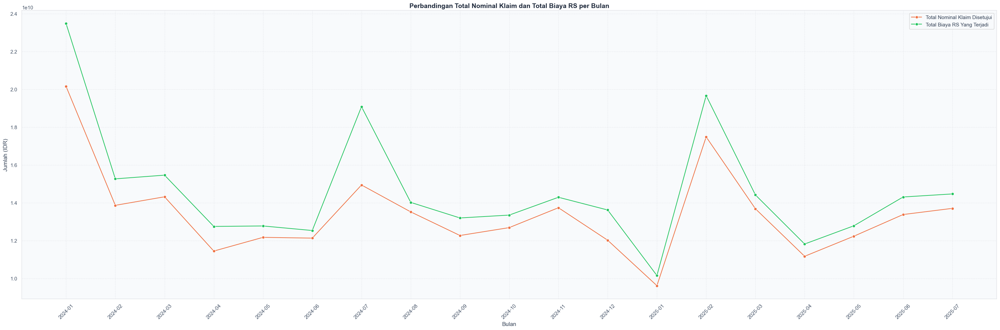

In [114]:
plt.figure(figsize=(30, 10))
sns.lineplot(
    x='YearMonth',
    y='total_nominal_klaim',
    data=df_compare_claim_biayars,
    label='Total Nominal Klaim Disetujui',
    marker='o',
    color="#EF7244"
)
sns.lineplot(
    x='YearMonth',
    y='total_biaya_rs',
    data=df_compare_claim_biayars,
    label='Total Biaya RS Yang Terjadi',
    marker='o',
    color='#22C55E'
)
plt.title('Perbandingan Total Nominal Klaim dan Total Biaya RS per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah (IDR)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

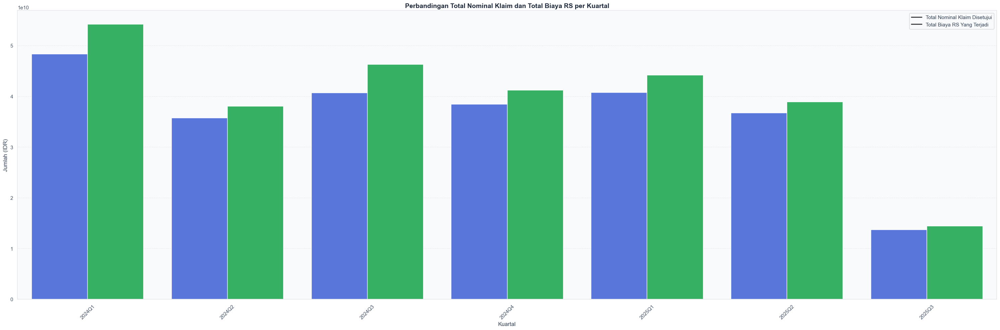

In [115]:
plt.figure(figsize=(30,10))

sns.barplot(
    x='Quarter',
    y='Jumlah',
    hue='Jenis',
    data=df_long,
    palette=['#446CEF', '#22C55E']
)

plt.title('Perbandingan Total Nominal Klaim dan Total Biaya RS per Kuartal')
plt.xlabel('Kuartal')
plt.ylabel('Jumlah (IDR)')
plt.xticks(rotation=45)

plt.legend([
    'Total Nominal Klaim Disetujui',
    'Total Biaya RS Yang Terjadi'
])

plt.tight_layout()
plt.show()

##### G.3.1.2. Average Claim vs Average Hospital Cost

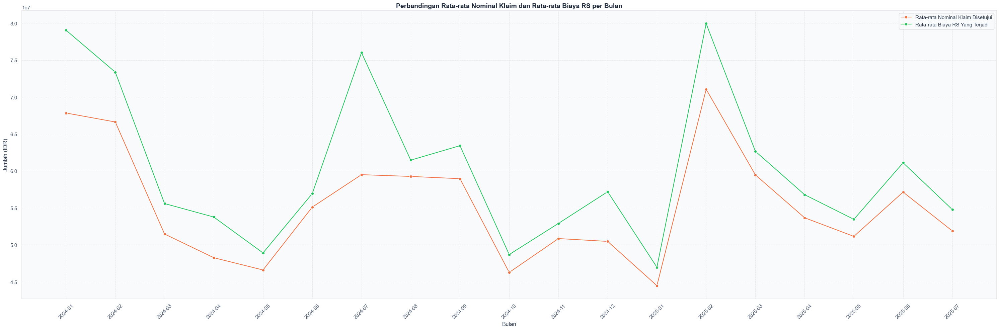

In [116]:
from turtle import color


plt.figure(figsize=(30, 10))
sns.lineplot(
    x='YearMonth',
    y='avg_nominal_klaim',
    data=df_compare_claim_biayars,
    label='Rata-rata Nominal Klaim Disetujui',
    marker='o',
    color="#EF7244"
)
sns.lineplot(
    x='YearMonth',
    y='avg_biaya_rs',
    data=df_compare_claim_biayars,
    label='Rata-rata Biaya RS Yang Terjadi',
    marker='o',
    color='#22C55E'
)
plt.title('Perbandingan Rata-rata Nominal Klaim dan Rata-rata Biaya RS per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah (IDR)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

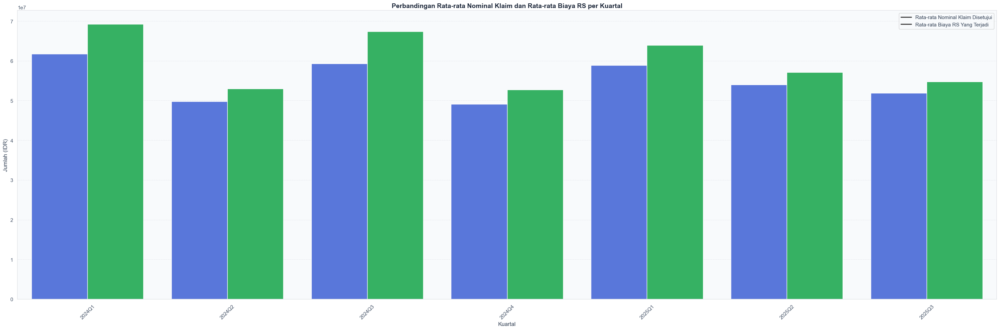

In [117]:
plt.figure(figsize=(30, 10))
sns.barplot(
    x='Quarter',
    y='Jumlah',
    hue='Jenis',
    data=df_long_avg,
    palette=['#446CEF', '#22C55E']
)
plt.title('Perbandingan Rata-rata Nominal Klaim dan Rata-rata Biaya RS per Kuartal')
plt.xlabel('Kuartal')
plt.ylabel('Jumlah (IDR)')
plt.xticks(rotation=45)
plt.legend([
    'Rata-rata Nominal Klaim Disetujui',
    'Rata-rata Biaya RS Yang Terjadi'
])
plt.tight_layout()
plt.show()

Berdasarkan grafik di atas, insight dan kesimpulan yang di dapat adalah:
1. Berdasarkan grafik per bulan, dapat dilihat bahwa garis biaya RS dan klaim selalu naik dan turun secara bersamaan degan gap yang kecil. Terlihat lonjakan setiap awal tahun dan satu lonjakan kecil pada pertengahan tahun. Dilihat juga bahwa biaya RS selalu berada di atas nominal klaim, menunjukkan pola gap yang konsisten tiap bulannya
2. Berdasarkan Grafik per kuartal, Q1 selalu berada paling tinggi setiap tahunnya, hal ini menunjukkan terdapat pola musiman di awal tahun. Q2 cenderung turun kemudian terjadi rebound pada Q3. Pada setiap kuartal, Biaya RS selalu lebih tinggi dibanding klaim pada semua kuartal, menunjukkan bahwa pola gap terlihat konsisten

##### G.3.2. Cost Gap (Excess)

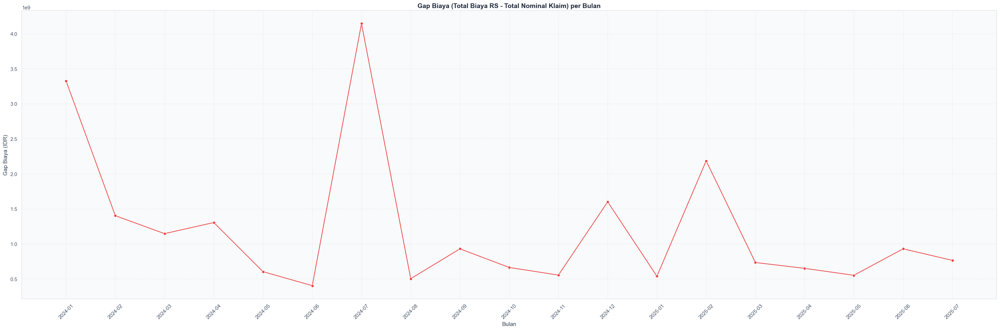

In [118]:
df_compare_claim_biayars['Gap Biaya'] = df_compare_claim_biayars['total_biaya_rs'] - df_compare_claim_biayars['total_nominal_klaim']
plt.figure(figsize=(30, 10))
sns.lineplot(
    x='YearMonth',
    y='Gap Biaya',
    data=df_compare_claim_biayars,
    marker='o',
    color='#EF4444'
)
plt.title('Gap Biaya (Total Biaya RS - Total Nominal Klaim) per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Gap Biaya (IDR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

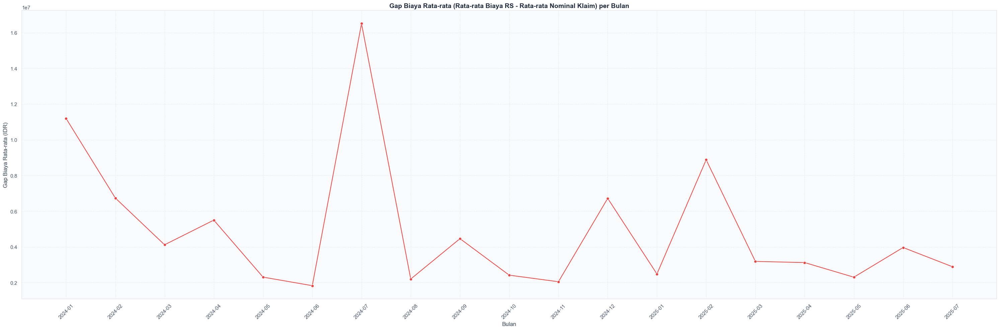

In [119]:
df_compare_claim_biayars['Avg Gap Biaya'] = df_compare_claim_biayars['avg_biaya_rs'] - df_compare_claim_biayars['avg_nominal_klaim']
plt.figure(figsize=(30, 10))
sns.lineplot(
    x='YearMonth',
    y='Avg Gap Biaya',
    data=df_compare_claim_biayars,
    marker='o',
    color='#EF4444'
)
plt.title('Gap Biaya Rata-rata (Rata-rata Biaya RS - Rata-rata Nominal Klaim) per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Gap Biaya Rata-rata (IDR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

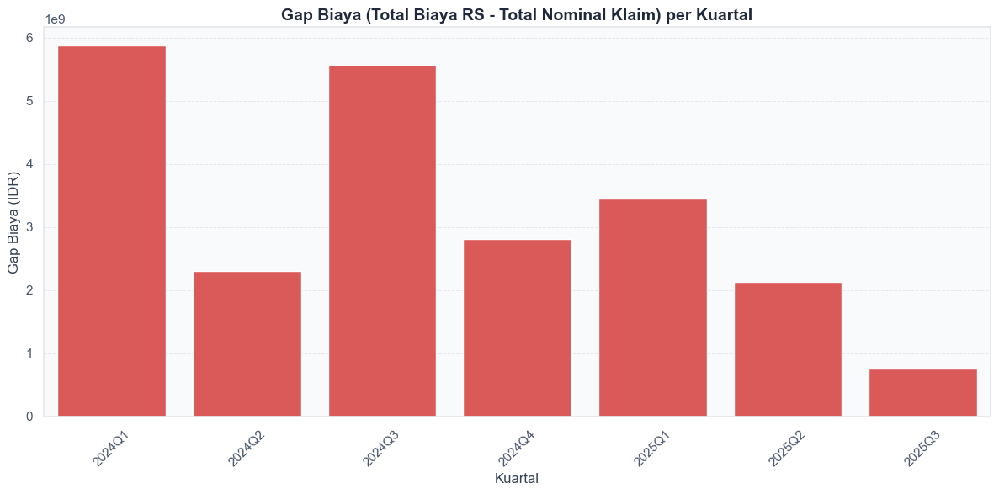

In [120]:
df_compare_claim_biayars_quarter['Gap Biaya'] = df_compare_claim_biayars_quarter['total_biaya_rs'] - df_compare_claim_biayars_quarter['total_nominal_klaim']
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Quarter',
    y='Gap Biaya',
    data=df_compare_claim_biayars_quarter,
    color='#EF4444'
)
plt.title('Gap Biaya (Total Biaya RS - Total Nominal Klaim) per Kuartal')
plt.xlabel('Kuartal')
plt.ylabel('Gap Biaya (IDR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

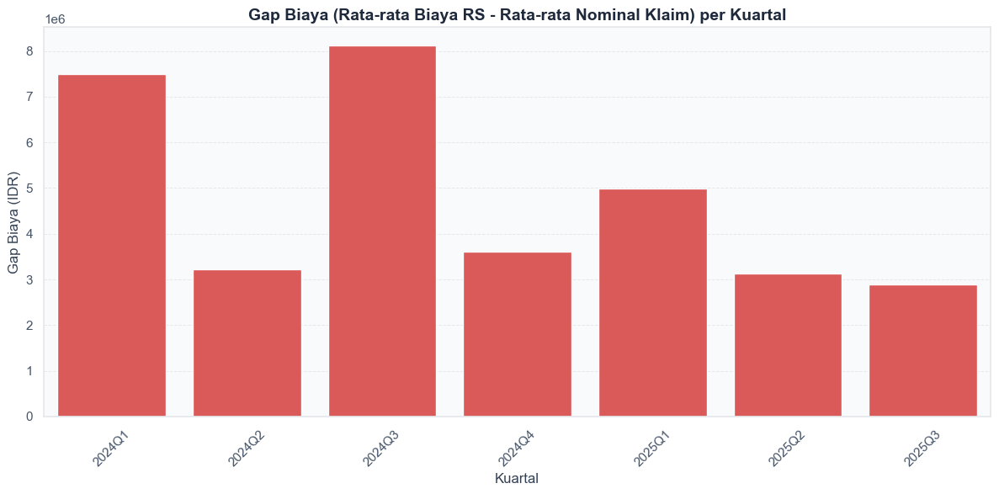

In [121]:
df_compare_claim_biayars_quarter['Gap Biaya'] = df_compare_claim_biayars_quarter['avg_biaya_rs'] - df_compare_claim_biayars_quarter['avg_nominal_klaim']
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Quarter',
    y='Gap Biaya',
    data=df_compare_claim_biayars_quarter,
    color='#EF4444'
)
plt.title('Gap Biaya (Rata-rata Biaya RS - Rata-rata Nominal Klaim) per Kuartal')
plt.xlabel('Kuartal')
plt.ylabel('Gap Biaya (IDR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Berdasarkan grafik mengenai gap biaya di atas, kami mendapatkan insight dan kesimpulan sebagai berikut:
1. Kami menemukan bahwa pada Q1 dan Q3 tahun 2024 terdapat lonjakan yang cukup tinggi pada gap biaya, artinya nominal klaim yang disetujui berada lebih jauh daripada biaya RS yang terjadi. Hal ini menjadi concern kami untuk dilakukan analisis mengapa terjadi gap yang cukup besar pada bulan itu, dan mungkin hasilnya dapat membantu untuk menentukan strategi di masa depan
2. Ketika memasuki tahun 2025, terlihat bahwa gap biaya mulai stabil dan mengecil, artinya payout rate mulai membaik. Hal ini menunjukkan peningkatan kemampuan Perusahaan AXA dalam menanggung biaya perawatan RS semakin besar dan stabil.

##### G.3.3. Checking Q1 and Q3 Increasing Cost Gap in 2024

In [122]:
# q1 2024
df_q1_2024 = df[df['Tanggal Pasien Masuk RS'].dt.to_period('Q') == '2024Q1']
df_q1_2024['gap_biaya'] = df_q1_2024['Nominal Biaya RS Yang Terjadi'] - df_q1_2024['Nominal Klaim Yang Disetujui']

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\2865616212.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_q1_2024['gap_biaya'] = df_q1_2024['Nominal Biaya RS Yang Terjadi'] - df_q1_2024['Nominal Klaim Yang Disetujui']


In [123]:
df_q1_2024.sort_values('gap_biaya', ascending=False)[
    ['Nomor Polis', 'Plan Code' ,'ICD_prefix', 'Nominal Klaim Yang Disetujui', 'Nominal Biaya RS Yang Terjadi', 'gap_biaya']].head(10)

,Nomor Polis,Plan Code,ICD_prefix,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,gap_biaya
2584,POL-1988,M-001,I,5.366324e+08,1.898035e+09,1.361402e+09
544,POL-2411,M-001,D,2.331518e+08,8.716469e+08,6.384951e+08
2586,POL-1988,M-001,I,6.930134e+08,1.141529e+09,4.485160e+08
3931,POL-1037,M-002,M,7.269154e+07,3.982327e+08,3.255412e+08
543,POL-2411,M-001,C,4.799528e+08,6.384951e+08,1.585423e+08
964,POL-1240,M-002,E,1.756406e+09,1.905637e+09,1.492314e+08
2724,POL-1305,M-002,I,7.100064e+07,2.131432e+08,1.421426e+08
965,POL-1240,M-002,E,2.434554e+07,1.492314e+08,1.248858e+08
3117,POL-1884,M-002,C,6.655046e+08,7.882399e+08,1.227353e+08
406,POL-3935,M-001,M,7.000000e+06,1.119948e+08,1.049948e+08


Kami melihat bahwa gap terbesar berada pada POL-1988 dengan Gap Biaya sekitar 1.36 x 1e9 (1,3 Miliar Rupiah). Mari kita cek lebih dalam mengenai POL-1988.

In [124]:
# cek POL-1988
df_pol_1988 = df[df['Nomor Polis'] == 'POL-1988'].sort_values('Tanggal Pasien Masuk RS')
df_pol_1988[['Claim ID', 'Tanggal Pasien Masuk RS','Tanggal Pasien Keluar RS','ICD_prefix','ICD Description','Nominal Klaim Yang Disetujui', 'Nominal Biaya RS Yang Terjadi', 'gap_biaya']]

,Claim ID,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,ICD_prefix,ICD Description,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,gap_biaya
2591,C-3374-M,2024-01-12,2024-01-12,I,"GANGRENE, NOT ELSEWHERE CLASSIFIED",5.000000e+06,5.721162e+06,7.211620e+05
2592,C-3375-M,2024-01-13,2024-01-15,I,"GANGRENE, NOT ELSEWHERE CLASSIFIED",1.874667e+08,1.882580e+08,7.913050e+05
2593,C-3376-M,2024-01-15,2024-01-21,I,"GANGRENE, NOT ELSEWHERE CLASSIFIED",7.257766e+08,8.201399e+08,9.436326e+07
2585,C-3368-M,2024-01-21,2024-01-29,I,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",1.290821e+09,1.361402e+09,7.058119e+07
2584,C-3367-M,2024-01-21,2024-01-29,I,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",5.366324e+08,1.898035e+09,1.361402e+09
2586,C-3369-M,2024-02-14,2024-02-19,I,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",6.930134e+08,1.141529e+09,4.485160e+08
2587,C-3370-M,2024-02-14,2024-02-19,I,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",3.510817e+08,4.485160e+08,9.743436e+07
2590,C-3373-M,2024-04-04,2024-04-05,I,"PERIPHERAL VASCULAR DISEASE, UNSPECIFIED",4.721754e+08,4.886182e+08,1.644278e+07
1079,C-1367-M,2024-10-10,2024-10-11,I,"Peripheral vascular disease, unspecified",6.241844e+08,6.252993e+08,1.114895e+06
1641,C-2062-M,2025-05-27,2025-05-28,I,"Peripheral vascular disease, unspecified",7.298712e+08,7.314495e+08,1.578219e+06


In [125]:
# cek total klaim dan biaya RS untuk POL-1988
total_klaim_pol_1988 = df_pol_1988['Nominal Klaim Yang Disetujui'].sum()
total_biaya_pol_1988 = df_pol_1988['Nominal Biaya RS Yang Terjadi'].sum()
print("Total Klaim Disetujui (POL-1988):", total_klaim_pol_1988)
print("Total Biaya RS Yang Terjadi (POL-1988):", total_biaya_pol_1988)

Total Klaim Disetujui (POL-1988): 5616023110.58
Total Biaya RS Yang Terjadi (POL-1988): 7708968639.809999


Setelah melakukan penelusuran terhadap pemegang polis POL-1988, kami menemukan bahwa peserta tersebut merupakan pasien yang memiliki penyakit jantung dan pembuluh darah (I). Berikut ini adalah analisis kami:
1. Ketika melihat claim ID, C-3367-M dan C-3368-M, kami menemukan sebuah anomali, yaitu sebuah tanda-tanda terjadinya sebuah splitting bill. Artinya total tagihan sebenarnya adalah 1,89M namun dibayarkan sebanyak 2x claim (1.29M dan 500 Juta) sehingga gap sebenarnya dari kasus klaim tersebut adalah 70 juta.
2. Karena kita menghitung gap per baris data, terciptalah sebuah nilai gap yang sangat besar dikarenakan tercatat 2x claim berbeda, namun ternyata terindikasi itu merupakan sebuah split bill claim
3. Hal ini menunjukkan bahwa ternyata, sebenarnya pada Q1 tidak terjadi lonjakan yang terlalu tinggi, dikarenakan seharusnya klaim tersebut memiliki GAP 70 juta saja. Artinya perusahaan AXA bahkan mampu untuk hampir melakukan full cover pada biaya RS 1.89M Rupiah.

In [126]:
# q3 2024
df_q3_2024 = df[df['Tanggal Pasien Masuk RS'].dt.to_period('Q') == '2024Q3']
df_q3_2024['gap_biaya'] = df_q3_2024['Nominal Biaya RS Yang Terjadi'] - df_q3_2024['Nominal Klaim Yang Disetujui']

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_15064\592859289.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_q3_2024['gap_biaya'] = df_q3_2024['Nominal Biaya RS Yang Terjadi'] - df_q3_2024['Nominal Klaim Yang Disetujui']


In [127]:
df_q3_2024.sort_values('gap_biaya', ascending=False)[
    ['Nomor Polis','Plan Code' ,'ICD_prefix', 'Nominal Klaim Yang Disetujui', 'Nominal Biaya RS Yang Terjadi', 'gap_biaya']].head(10)

,Nomor Polis,Plan Code,ICD_prefix,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,gap_biaya
905,POL-0830,M-002,E,7.888780e+08,3.892810e+09,3.103932e+09
252,POL-3622,M-002,C,1.813035e+09,2.152368e+09,3.393333e+08
1029,POL-1792,M-002,K,1.769290e+08,3.556440e+08,1.787150e+08
2666,POL-3581,M-003,J,4.119493e+07,2.128776e+08,1.716827e+08
1127,POL-1337,M-001,M,8.894176e+08,1.033511e+09,1.440934e+08
283,POL-3277,M-002,M,4.388819e+08,5.598831e+08,1.210013e+08
2364,POL-0935,M-002,C,1.104661e+09,1.188142e+09,8.348103e+07
2205,POL-3321,M-002,C,7.452481e+08,8.237470e+08,7.849892e+07
2250,POL-0696,M-002,C,7.082789e+08,7.762518e+08,6.797284e+07
3868,POL-3374,M-002,M,4.985380e+08,5.606320e+08,6.209396e+07


In [128]:
df_pol_0830 = df[df['Nomor Polis'] == 'POL-0830'].sort_values('Tanggal Pasien Masuk RS')
df_pol_0830[['Claim ID', 'Tanggal Pasien Masuk RS','Lokasi RS','Tanggal Pasien Keluar RS','ICD_prefix','ICD Diagnosis','Nominal Klaim Yang Disetujui', 'Nominal Biaya RS Yang Terjadi', 'gap_biaya']]

,Claim ID,Tanggal Pasien Masuk RS,Lokasi RS,Tanggal Pasien Keluar RS,ICD_prefix,ICD Diagnosis,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,gap_biaya
898,C-1154-M,2024-01-30,Indonesia,2024-02-01,I,I63.6,4.155554e+07,4.716851e+07,5.612965e+06
901,C-1158-M,2024-07-27,Indonesia,2024-07-30,I,I63,2.271200e+07,2.383400e+07,1.122000e+06
905,C-1162-M,2024-07-31,Singapore,2024-08-28,E,E13.6,7.888780e+08,3.892810e+09,3.103932e+09
904,C-1161-M,2024-08-28,Indonesia,2024-10-21,C,C34.9,1.411122e+09,1.465628e+09,5.450644e+07


Setelah melakukan analisis lebih dalam terhadap POL-0830, kami menemukan bahwa gap biaya terbesar terdapat pada 31 Juli 2024. Terdapat insight atau kesimpulan yang kami dapatkan, yaitu:
1. Lokasi RS ketika klaim tersebut diajukan adalah di Singapore, di mana harga perawatan rumah sakit di Singapore lebih tinggi dibandingkan harga perawatan di Indonesia
2. Perawatan dilakukan selama sekitar 29 hari di rumah sakit, dan penyakitnya berkaitan dengan komplikasi diabetes
3. Hal ini menyebabkan nominal biaya RS yang terjadi masih memungkinkan untuk menyentuh angka 3.89M Rupiah
4. Nominal klaim yang disetujui hanya sekitar 788 Juta saja, menurut asumsi kami hal ini dapat dikarenakan plan code yang dipilih oleh peserta tersebut. Namun kami memerlukan anallisis lebih lanjut mengenai ini

##### G.3.4. Plan Code Analysis

In [129]:
# fully paid, 90% paid, not fully paid
def categorize_payment_status(row):
    if row['gap_biaya'] == 0:
        return 'Fully Paid'
    elif row['gap_biaya'] <= 0.1 * row['Nominal Biaya RS Yang Terjadi']:
        return '90% Paid'
    else:
        return 'Not Fully Paid'
df['status_pembayaran'] = df.apply(categorize_payment_status, axis=1)

df_status_prop = (
    df.groupby(['Plan Code', 'status_pembayaran'])
    .size()
    .reset_index(name='jumlah_klaim')
)

df_status_prop['proporsi'] = (
    df_status_prop['jumlah_klaim'] /
    df_status_prop.groupby('Plan Code')['jumlah_klaim'].transform('sum')
)

plan_palette = {
    'M-001': '#446CEF',   
    'M-002': '#22C55E',   
    'M-003': '#F59E0B'    
}

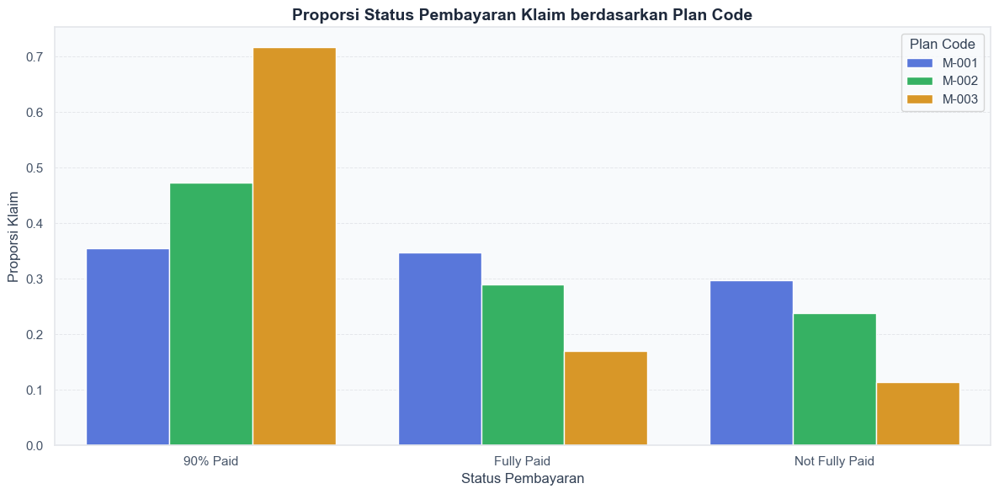

In [130]:
plt.figure(figsize=(12,6))

sns.barplot(
    x='status_pembayaran',
    y='proporsi',
    hue='Plan Code',
    data=df_status_prop,
    palette=plan_palette
)

plt.title('Proporsi Status Pembayaran Klaim berdasarkan Plan Code')
plt.xlabel('Status Pembayaran')
plt.ylabel('Proporsi Klaim')

plt.legend(title='Plan Code')

plt.tight_layout()
plt.show()

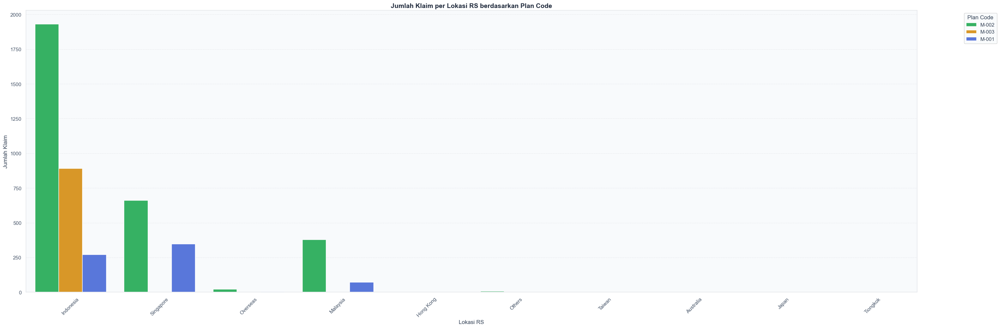

In [131]:
plt.figure(figsize=(30,10))
sns.countplot(
    x='Lokasi RS',
    hue='Plan Code',
    data=df,
    palette=plan_palette
)
plt.title('Jumlah Klaim per Lokasi RS berdasarkan Plan Code')
plt.xlabel('Lokasi RS')
plt.ylabel('Jumlah Klaim')
plt.xticks(rotation=45)
plt.legend(title='Plan Code', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()

Berdasarkan analisis mengenai plan code, kami mendapatkan beberapa insight dan kesimpulan:
1. Berdasarkan hasil analisis mengenai plan code dengan fully paid, 90% paid, dan not fully paid, kami mendapatkan kesimpulan bahwa secara proporsi, M-001 memiliki distribusi yang cukup merata antara klaim yang dibayar penuh, sebagian, maupun tidak sepenuhnya dibayar. M-002 Menunjukkan fully paid yang cukup tinggi, M-002 memiliki distribusi pembayaran klaim yang lebih seimbang, meskipun sebagian besar masih berada pada 90% paid. M-003 sangat dominan di 90% paid, namun memiliki fully paid yang relatif lebih keci dari yang lain
2. Berdasarkan analisis mengenai lokasi RS dengan plan code, kami melihat bahwa M-001 dan M-002 terdapat pada negara lain selain Indonesia. Sedangkan untuk M-003 hanya berada pada Negara Indonesia saja. Dengan informasi ini, kami dapat berasumsi bahwa M-001 dan M-002 memiliki benerfit untuk luar negeri, sedangkan untuk M-003 hanya memiliki manfaat dalam negeri saja

##### G.3.5. Disease Cost Driver Analysis (ICD Analysis)

In [132]:
df_icd_month = (
    df
    .groupby(['YearMonth', 'ICD_prefix'])
    .size()
    .reset_index(name='Jumlah Klaim')
)

df_icd_month['YearMonth'] = df_icd_month['YearMonth'].dt.strftime('%Y-%m')
df_icd_month = df_icd_month.sort_values('YearMonth')

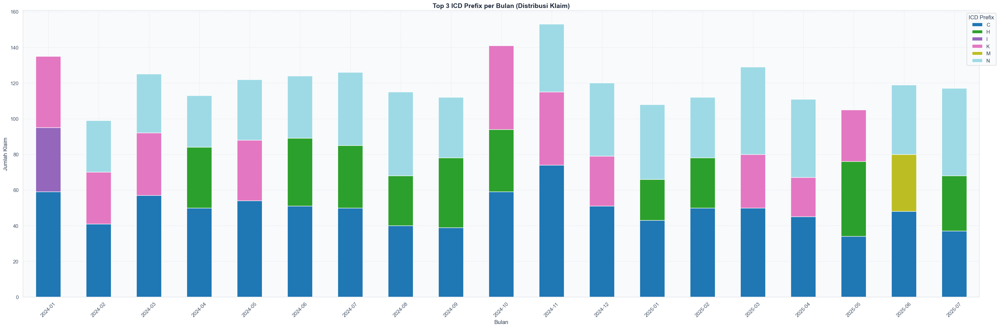

In [133]:
# top 3 ICD per bulan
top3_icd = (
    df_icd_month
    .sort_values(['YearMonth', 'Jumlah Klaim'], ascending=[True, False])
    .groupby('YearMonth')
    .head(3)
)

# Pivot untuk stacked bar
pivot_icd = top3_icd.pivot(
    index='YearMonth',
    columns='ICD_prefix',
    values='Jumlah Klaim'
).fillna(0)

pivot_icd.plot(
    kind='bar',
    stacked=True,
    figsize=(30, 10),
    colormap='tab20'
)

plt.title('Top 3 ICD Prefix per Bulan (Distribusi Klaim)')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Klaim')
plt.xticks(rotation=45)
plt.legend(title='ICD Prefix', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Dari grafik di atas, kami melihat bahwa penyakit yang konsisten muncul di setiap bulan adalah C atau kanker. Kemudian penyakit ginjal dan saluran kemih (N), Mata dan telinga (H) dan penyakit sistem pencernaan (K) juga muncul secara konsisten tiap bulannya. Disini juga terlihat bahwa ada penyakit jantung dan pembuluh darah yang muncul di awal 2024 dan penyakit otot/tulang pada Juni 2025. Dari hasil ini, kami dapat menyimpulkan hal berikut:
1. Setiap bulan pasien kanker secara konsisten melakukan klaim, hal ini mungkin berkaitan dengan treatment cancer yang dijalankan
2. Penyakit ginjal dan saluran kemih juga muncul secara konsisten hampir pada setiap bulan, berkaitan dengan penyakit ginjal, treatment penyakit ini juga biasanya dilakukan secara rutin seperti Hemodialisis atau kontrol dokter
3. Penyakit lain perlu kami periksa kembali untuk melihat pola, maupun adakah musim dari penyakit tertentu

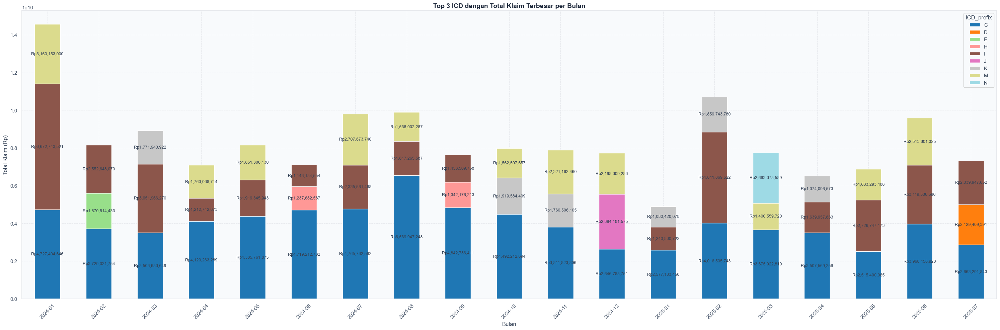

In [134]:
df_icd_cost_month = (
    df.groupby(['YearMonth', 'ICD_prefix'])
    .agg(
        total_klaim_rp=('Nominal Klaim Yang Disetujui', 'sum'),
        avg_klaim_rp=('Nominal Klaim Yang Disetujui', 'mean'),
    )
    .reset_index()
)

top3_icd_cost = (
    df_icd_cost_month
    .sort_values(['YearMonth', 'total_klaim_rp'], ascending=[True, False])
    .groupby('YearMonth')
    .head(3)
)

pivot_cost = top3_icd_cost.pivot(
    index='YearMonth',
    columns='ICD_prefix',
    values='total_klaim_rp'
).fillna(0)

ax = pivot_cost.plot(
    kind='bar',
    stacked=True,
    figsize=(30, 10),
    colormap='tab20'
)

plt.title('Top 3 ICD dengan Total Klaim Terbesar per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Klaim (Rp)')
plt.xticks(rotation=45)

for container in ax.containers:
    labels = [
        f"Rp{int(v):,}" if v > 0 else ""
        for v in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

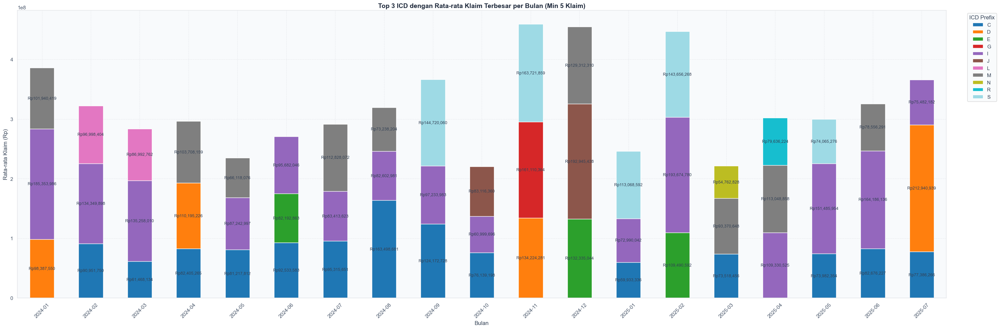

In [135]:
# hitung avg dan jumlah klaim
df_icd_avg_month = (
    df.groupby(['YearMonth', 'ICD_prefix'])
    .agg(
        avg_klaim_rp=('Nominal Klaim Yang Disetujui', 'mean'),
        jumlah_klaim=('Nominal Klaim Yang Disetujui', 'count')
    )
    .reset_index()
)

df_icd_avg_month = df_icd_avg_month[df_icd_avg_month['jumlah_klaim'] >= 5]

top3_icd_avg_cost = (
    df_icd_avg_month
    .sort_values(['YearMonth', 'avg_klaim_rp'], ascending=[True, False])
    .groupby('YearMonth')
    .head(3)
)

pivot_avg_cost = top3_icd_avg_cost.pivot(
    index='YearMonth',
    columns='ICD_prefix',
    values='avg_klaim_rp'
).fillna(0)

ax = pivot_avg_cost.plot(
    kind='bar',
    stacked=True,
    figsize=(30,10),
    colormap='tab20'
)

plt.title('Top 3 ICD dengan Rata-rata Klaim Terbesar per Bulan (Min 5 Klaim)')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata Klaim (Rp)')
plt.xticks(rotation=45)

for container in ax.containers:
    labels = [
        f"Rp{int(v):,}" if v > 0 else ""
        for v in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9
    )
ax.legend(title='ICD Prefix', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Grafik di atas merupakan top 3 penyakit dengan nominal cost terbesar dan average cost terbesar setiap bulannya, setelah melakukan analisis kami memiliki kesimpulan sebagai berikut:
1. Di setiap bulannya, Cancer masih menjadi cost driver utama karena setiap bulannya average dan total cost dari penyakit cancer tergolong tinggi dan selalu masuk dalam top 3 penyakit pada bulan itu. Hal ini menunjukkan biaya perawatan kanker per kasus juga tergolong tinggi, dikarenakan perawatan kanker yang melibatkan perawatan intensif, dan prosedur medis seperti kemoterapi, radioterapi, operasi, dan lain-lain. Untuk menjustifikasi hal ini, kami perlu melihat dan menganalisis lebih dalam mengenai penyakit cancer dalam dataset
2. Beberapa kategori lain juga muncul dalam top 3 ICD, seperti penyakit saraf (G), penyakit pernapasan (J), dan lain-lain. Hal ini menunjukkan bahwa kategori lain yang tidak muncul setiap bulanna=ya, bisa menghasilkan biaya pengobatan yang tinggi ketika kasusnya terjadi. Kami juga melihat bahwa penyakit pernapasan muncul pada akhir tahun 2024, maka kami mungkin akan lanjut untuk melihat tren dari penyakit tersebut


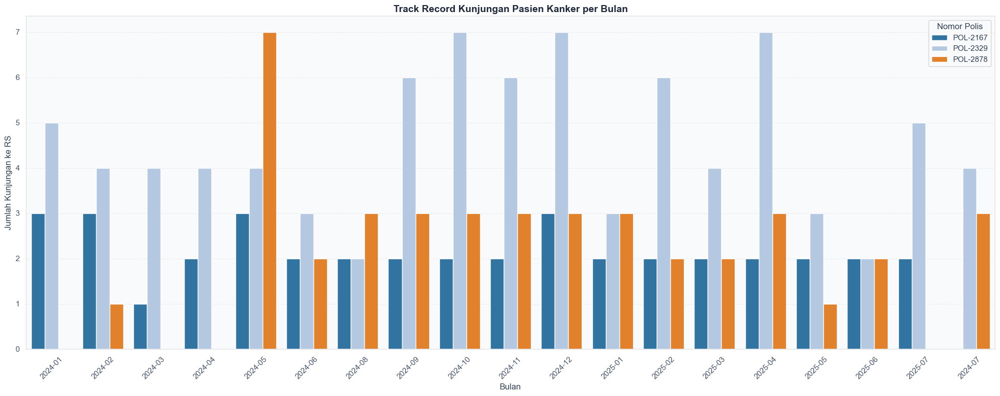

In [136]:
df_cancer = df[df['ICD_prefix'] == 'C'].copy()

sample_patients = (
    df_cancer.groupby('Nomor Polis')
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
)

df_sample = df_cancer[df_cancer['Nomor Polis'].isin(sample_patients)]

df_track = (
    df_sample
    .groupby(['Nomor Polis', 'YearMonth'])
    .size()
    .reset_index(name='Jumlah Kunjungan')
)

df_track['YearMonth'] = df_track['YearMonth'].astype(str)

plt.figure(figsize=(20, 8))

sns.barplot(
    data=df_track,
    x='YearMonth',
    y='Jumlah Kunjungan',
    hue='Nomor Polis'
)

plt.title('Track Record Kunjungan Pasien Kanker per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Kunjungan ke RS')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

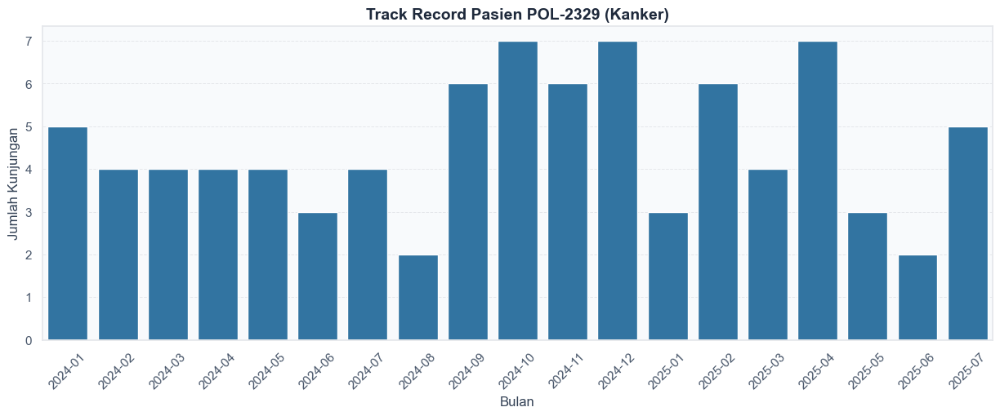

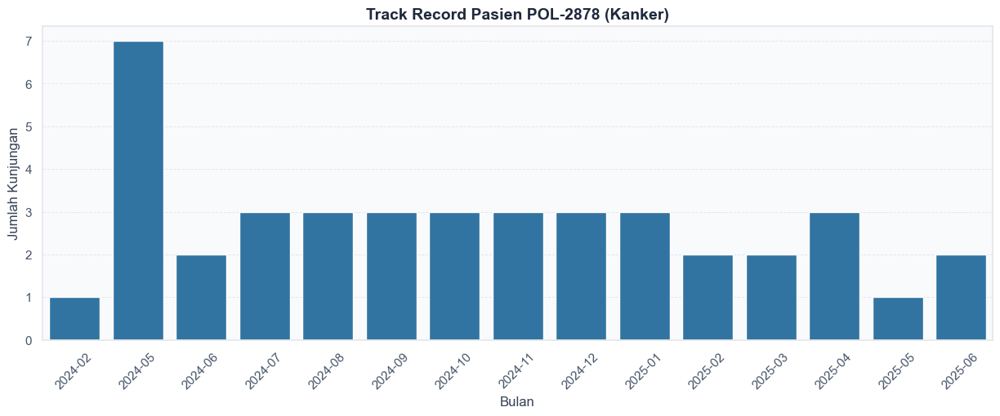

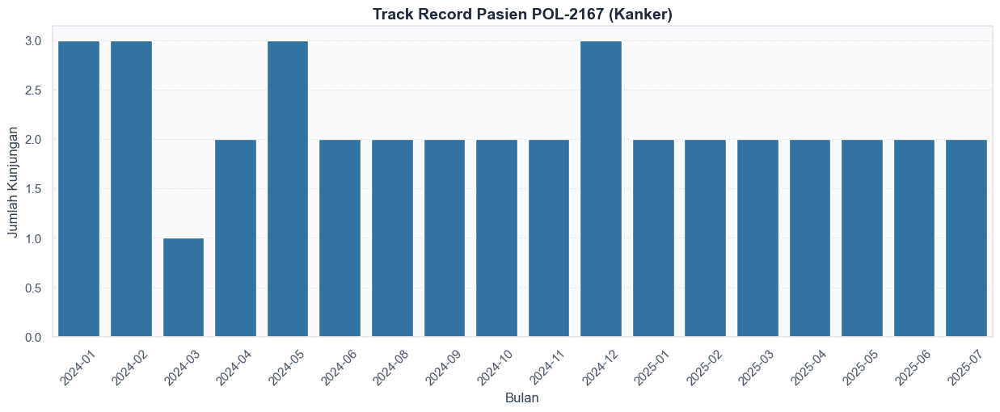

In [137]:
for patient in sample_patients:
    data_patient = df_track[df_track['Nomor Polis'] == patient]

    plt.figure(figsize=(15, 5))
    sns.barplot(
        data=data_patient,
        x='YearMonth',
        y='Jumlah Kunjungan'
    )

    plt.title(f'Track Record Pasien {patient} (Kanker)')
    plt.xlabel('Bulan')
    plt.ylabel('Jumlah Kunjungan')
    plt.xticks(rotation=45)
    plt.show()

Dari grafik di atas, kami mendapatkan kesimpulan dan insight sebagai berikut:
1. Berdasarkan grafik top peserta kanker yang melakukan klaim dengan kasus penyakit kanker, kami melihat bahwa pasien kanker secara konsisten dan repetitif mengunjungi rumah sakit beberapa kali dalam satu bulan
2. Berdasarkan track record pribadi, dapat terlihat juga bahwa terbukti apabila pasien penderita kanker, akan cenderung untuk mengunjungi rumah sakit setiap bulan dan bisa lebih dari 1 kali kunjungan dalam sebulan.
3. Asumsi kami, peserta penderita kanker akan secara rutin setiap bulannya untuk mengunjungi rumah sakit untuk melakukan pengobatan rutin (kemoterapi, radioterapi), kontrol dokter, maupun perawatan lainnya. Sehingga kanker menjadi penyakit yang konsisten tiap bulan menyumbang cost yang cukup tinggi ke nominal klaim

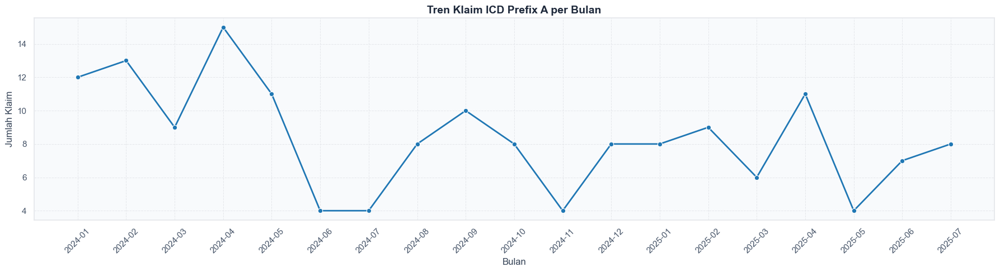

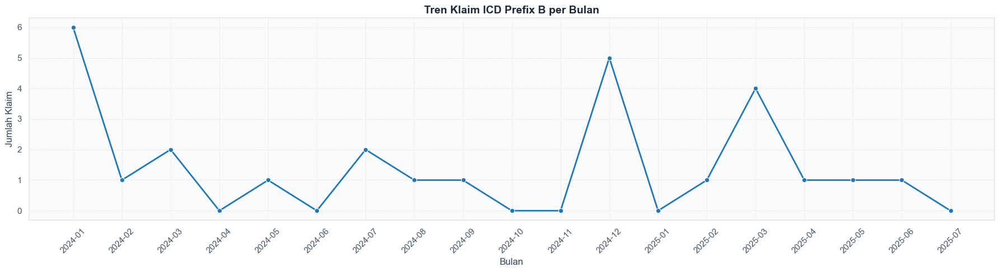

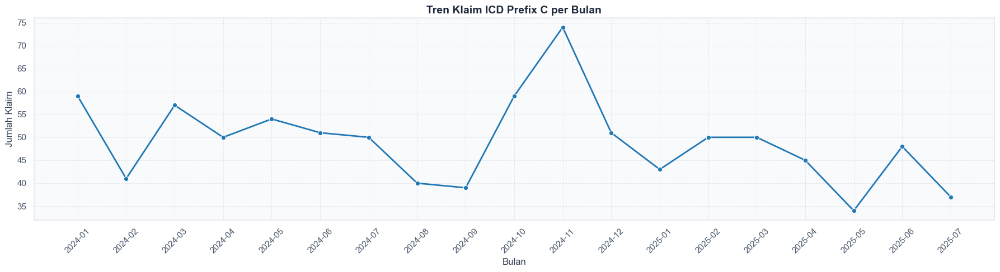

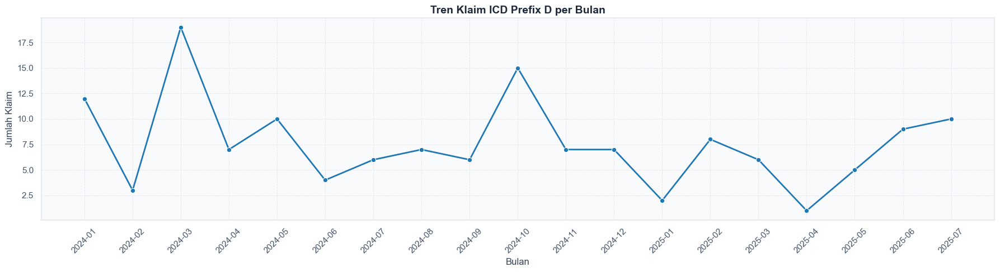

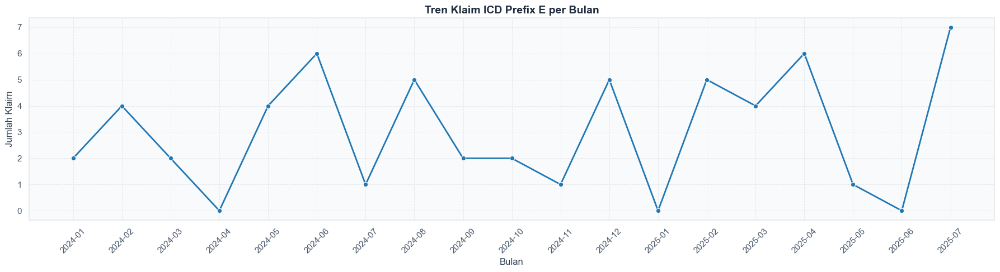

...

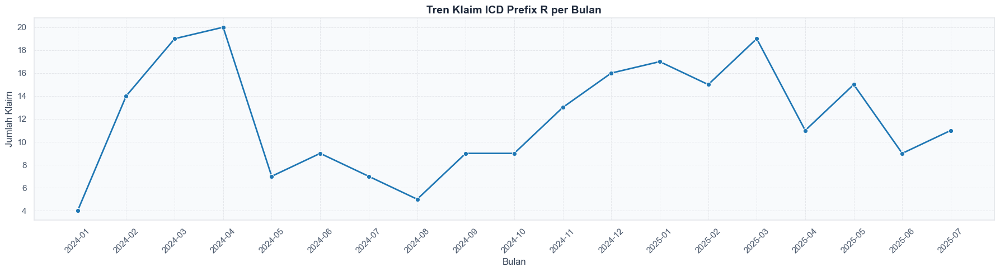

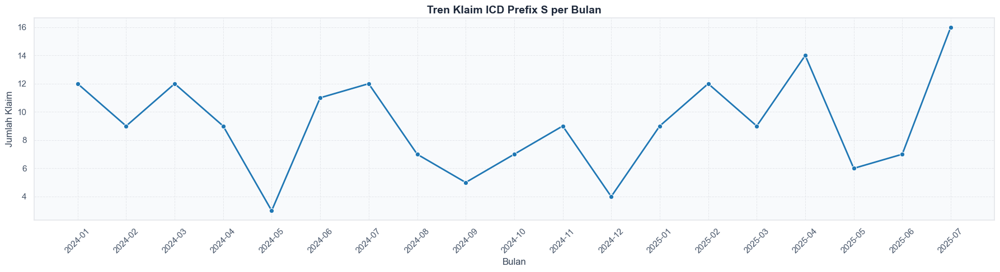

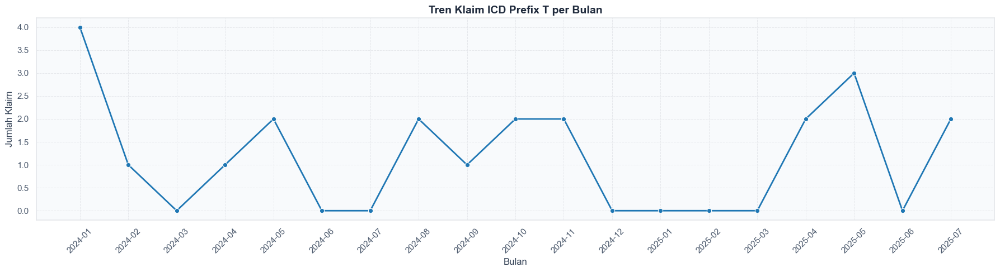

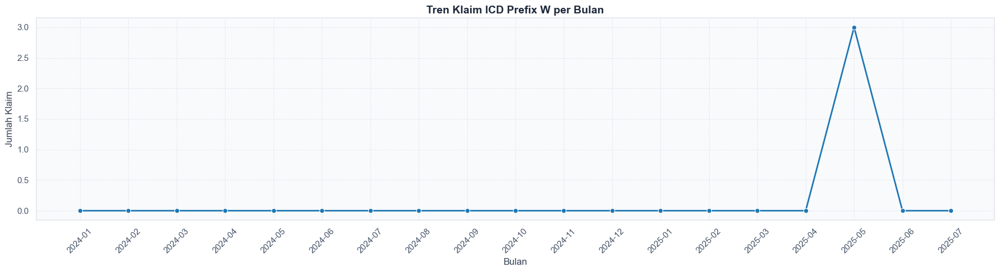

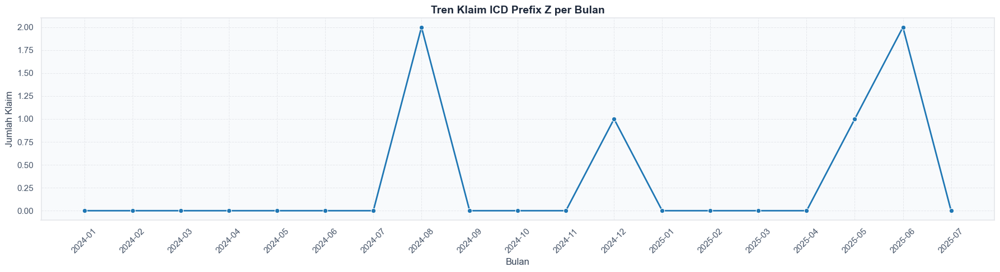

In [138]:
df_prefix_month = (
    df.groupby(['YearMonth', 'ICD_prefix'])
    .size()
    .reset_index(name='Jumlah Klaim')
)

all_months = sorted(df['YearMonth'].unique())
all_icd = sorted(df['ICD_prefix'].unique())

full_index = pd.MultiIndex.from_product(
    [all_months, all_icd],
    names=['YearMonth', 'ICD_prefix']
)

df_prefix_month = (
    df_prefix_month
    .set_index(['YearMonth', 'ICD_prefix'])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

df_prefix_month['YearMonth'] = df_prefix_month['YearMonth'].astype(str)

for icd in all_icd:
    data_icd = df_prefix_month[df_prefix_month['ICD_prefix'] == icd]

    plt.figure(figsize=(18, 5))
    sns.lineplot(
        data=data_icd,
        x='YearMonth',
        y='Jumlah Klaim',
        marker='o',
        linewidth=2
    )

    plt.title(f'Tren Klaim ICD Prefix {icd} per Bulan')
    plt.xlabel('Bulan')
    plt.ylabel('Jumlah Klaim')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Berdasarkan grafik tren klaim per ICD di atas, kami mendapatkan insight dan kesimpulan sebagai berikut:
1. Berdasarkan grafik, penyakit Cancer (C) menjadi tren yang konsisten setiap bulannya
2. Selain penyakit cancer, kami juga concern pada penyakit pernapasan J yang muncul pada akhir tahun 2024. Dari situ kami melihat bahwa penyakit pernapasan terjadi sebuah spike pada akhir tahun 2024 padahal di bulan-bulan sebelumnya penyakit ini stabil rendah, ini dapat mengindikasikan adanya musim virus tertentu, cuaca, maupun musim dingin yang menyebabkan penyakit pernapasan jadi lebih banyak di akhir tahun. 
3. Penyakit ginjal dan saluran kemih (N) juga menunjukkan rata-rata klaim yang tinggi, walaupun terdapat beberapa fluktuasi di beberapa bulan. Menurut asumsi kami, penyakit ginjal juga memiliki perawatan yang perlu dilakukan secara rutin sehingga penyakit ini juga secara konsisten tinggi setiap bulannya. Fluktuasi yang terjadi mungkin muncul karena perawatan ginjal seperti Hemodialisis biasanya dilakukan dalam rentang 2 bulan sekali atau 3 bulan sekali, sehingga dapat menyebabkan fluktuasi di beberapa bulan sekali

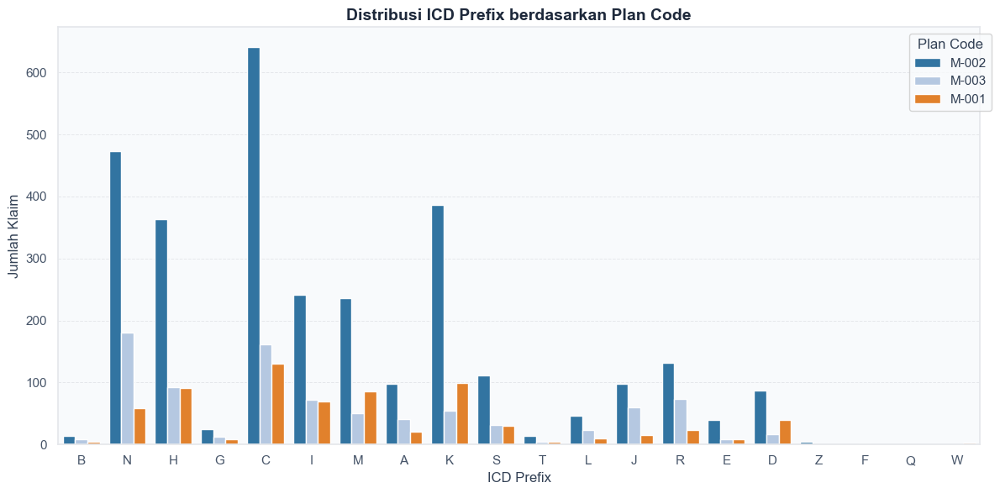

In [139]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x='ICD_prefix',
    hue='Plan Code'
)
plt.title('Distribusi ICD Prefix berdasarkan Plan Code')
plt.xlabel('ICD Prefix')
plt.ylabel('Jumlah Klaim')
plt.legend(title='Plan Code', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Berdasarkan grafik di atas, kami mendapatkan kesimpulan sebagai berikut:
1. Setiap penyakit atau ICD masing-masing ditempati oleh ketiga plan code, yang artinya ketiga plan tersebut cover seluruh penyakit yang terdapat dalam ICD. Hal ini menunjukkan bahwa perusahaan asuransi AXA menyediakan plan code yang dapat cover segala penyakit yang dialami oleh pemegang polis, sehingga peserta yang ingin membeli polis dapat menyesuaikan polis yang diinginkan tanpa memikirkan coverage penyakit dari polis tersebut
2. M-002 menjadi plan yang paling dominan pada setiap ICD

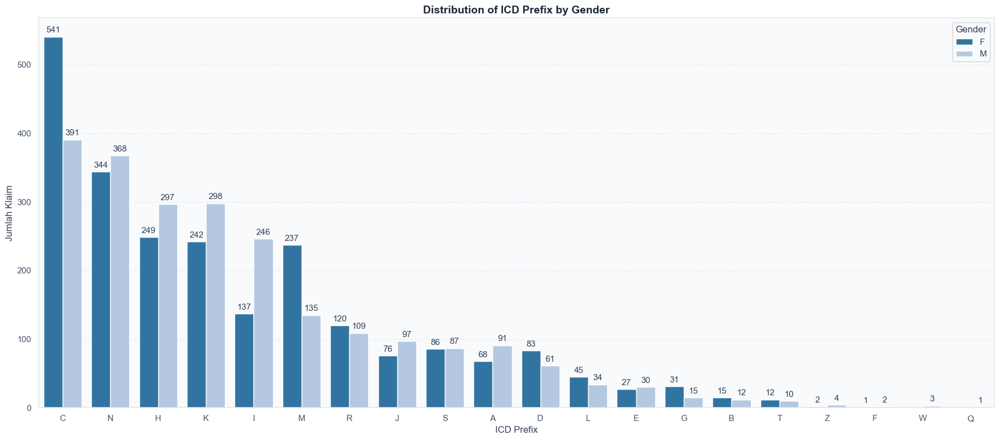

In [140]:
df_sorted_icd = df.groupby(['ICD_prefix', 'Gender']).size().reset_index(name='Jumlah_Klaim')

order_icd = (
    df_sorted_icd.groupby('ICD_prefix')['Jumlah_Klaim']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(18, 8))

ax = sns.barplot(
    data=df_sorted_icd,
    x='ICD_prefix',
    y='Jumlah_Klaim',
    hue='Gender',
    order=order_icd
)

plt.title('Distribution of ICD Prefix by Gender')
plt.xlabel('ICD Prefix')
plt.ylabel('Jumlah Klaim')
plt.tight_layout()

# tampilkan angka di bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.show()

Berdasarkan grafik di atas, kita dapat melihat penyakit mana yang paling banyak diderita oleh perempuan dan mana yang paling banyak diderita oleh laki-laki

##### G.3.6. Risk Map

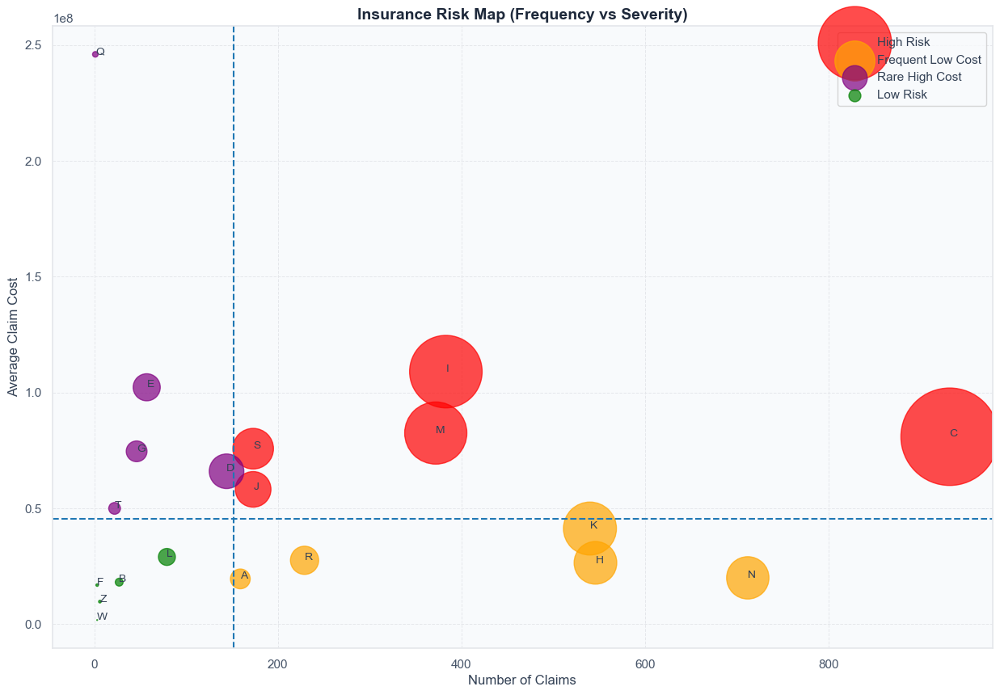

In [141]:
df_risk_map = (
    df.groupby('ICD_prefix')
    .agg(
        frequency=('Nominal Klaim Yang Disetujui', 'count'),
        severity=('Nominal Klaim Yang Disetujui', 'mean'),
        total_cost=('Nominal Klaim Yang Disetujui', 'sum')
    )
    .reset_index()
)

freq_median = df_risk_map['frequency'].median()
sev_median = df_risk_map['severity'].median()

conditions = [
    (df_risk_map['frequency'] >= freq_median) & (df_risk_map['severity'] >= sev_median),
    (df_risk_map['frequency'] >= freq_median) & (df_risk_map['severity'] < sev_median),
    (df_risk_map['frequency'] < freq_median) & (df_risk_map['severity'] >= sev_median),
    (df_risk_map['frequency'] < freq_median) & (df_risk_map['severity'] < sev_median)
]

labels = [
    'High Risk',
    'Frequent Low Cost',
    'Rare High Cost',
    'Low Risk'
]

df_risk_map['risk_type'] = np.select(conditions, labels, default='Low Risk')

color_map = {
    'High Risk': 'red',
    'Frequent Low Cost': 'orange',
    'Rare High Cost': 'purple',
    'Low Risk': 'green'
}

plt.figure(figsize=(15,10))

for risk in color_map:
    subset = df_risk_map[df_risk_map['risk_type'] == risk]
    plt.scatter(
        subset['frequency'],
        subset['severity'],
        s=subset['total_cost'] / 1e7,
        c=color_map[risk],
        label=risk,
        alpha=0.7
    )

plt.axvline(freq_median, linestyle='--')
plt.axhline(sev_median, linestyle='--')

for i in range(len(df_risk_map)):
    plt.text(
        df_risk_map['frequency'].iloc[i],
        df_risk_map['severity'].iloc[i],
        df_risk_map['ICD_prefix'].iloc[i],
        fontsize=10
    )

plt.title('Insurance Risk Map (Frequency vs Severity)')
plt.xlabel('Number of Claims')
plt.ylabel('Average Claim Cost')
plt.legend()
plt.show()

Pada grafik di atas, menunjukkan risk map dimana sumbu X adalah jumlah klaim dan sumbu y adalah average claim cost. Berdasarkan grafik di atas, kesimpulan dan insight yang didapat adalah sebagai berikut:
1. Pada kuadran High Risk, artinya ICD tersebut merupakan penyumbang terbesar biaya total klaim. Dikarenakan frekuensi yang tinggi ditambah dengan severity yang tinggi juga, menyebabkan penyakit tersebut tergolong sebagai high risk. Pada kategori ini, terdapat 5 high risk ICD yaitu, Cancer (C), Penyakit jantung dan pembuluh darah (I), Penyakit otot dan tulang (M), Penyakit pernapasan (J), dan injury/trauma (S). Kategori-kategori tersebut akan mendominasi beban klaim perusahaan
2. Kemudian terdapat 3 kuadran lainnya yaitu, frequent low cost artinya frekuensinya cukup tinggi namun severity atau harga rata-ratanya tidak terlalu tinggi, rare high cost artinya frekuensinya jarang terjadi namun setiap kasus memiliki rata-rata yang tinggi, kemudian yang terakhir adalah low risk yang artinya penyakit tersebut jarang terjadi dan memiliki severity atau average cost per case yang rendah.

### G.4. Prescriptive Analysis